# Hotel Bar Demand Forecasting and Inventory Optimization

## Business problem

Hotel bars need enough stock to meet guest demand without tying up excessive capital in inventory or risking stockouts. Historical consumption, purchasing, and balance records can help estimate demand and support consistent replenishment decisions. This project will use the supplied records to explore demand and, in later stages, evaluate forecasting and inventory policies.

## Project objectives

- Understand the hotel bar inventory and demand-planning problem.
- Explore and validate the supplied dataset before analysis.
- Analyze consumption by date, bar, brand, and alcohol category.
- Engineer forecasting features and evaluate a demand model using chronological validation.
- Recommend inventory par levels, reorder points, and safety stock.
- Simulate replenishment scenarios, build an executive dashboard, export results to Excel, and prepare a business report.

Missing dates will not be assumed to have zero consumption. Data limitations and any assumptions will be documented as the analysis develops.

## Technology stack

Python, Pandas, NumPy, Matplotlib, Seaborn, Scikit-learn, SciPy, Jupyter, and OpenPyXL.

## Python imports

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import openpyxl
import pandas as pd
import seaborn as sns
from scipy import stats
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import TimeSeriesSplit

## Load the dataset

The CSV is stored in the project-level `data` folder. This path check supports running the notebook with either the project root or the `notebooks` folder as the current working directory; it does not modify or impute the data.

In [2]:
project_root = Path.cwd()
if not (project_root / "data").is_dir() and (project_root.parent / "data").is_dir():
    project_root = project_root.parent

dataset_path = project_root / "data" / "Consumption Dataset - Dataset.csv"
if not dataset_path.is_file():
    raise FileNotFoundError(f"Dataset not found at expected relative path: {dataset_path}")

df = pd.read_csv(dataset_path)
print(f"Dataset loaded from: {dataset_path.relative_to(project_root)}")
print(f"Shape: {df.shape[0]:,} rows × {df.shape[1]} columns")
print("Columns:")
for column in df.columns:
    print(f"- {column}")

Dataset loaded from: data\Consumption Dataset - Dataset.csv
Shape: 6,575 rows × 8 columns
Columns:
- Date Time Served
- Bar Name
- Alcohol Type
- Brand Name
- Opening Balance (ml)
- Purchase (ml)
- Consumed (ml)
- Closing Balance (ml)


## Phase 3: Data Cleaning, Data Validation, and Exploratory Data Analysis

The source DataFrame `df` is retained unchanged. The analysis uses a separate copy for parsed dates and numeric validation. Recorded consumption below means the values present in the source records; it is not a forecast or an estimate of unobserved demand.

### 1. Dataset structure

Review the inferred data types and summaries before interpreting any values. The date field is still shown in its original form here; parsing is checked separately below.

In [3]:
print(f"Dataset shape: {df.shape[0]:,} rows × {df.shape[1]} columns")
print("Column names:")
print(df.columns.tolist())

print("\nData types:")
display(df.dtypes.rename("Data type").to_frame())

print("Sample records:")
display(df.head())

numerical_columns = df.select_dtypes(include=["number"]).columns.tolist()
categorical_columns = df.select_dtypes(include=["object", "category"]).columns.tolist()

print("Numerical column summary:")
if numerical_columns:
    display(df[numerical_columns].describe().T)
else:
    print("No numerical columns were inferred.")

print("Categorical column summary:")
if categorical_columns:
    display(df[categorical_columns].describe().T)
else:
    print("No categorical columns were inferred.")

Dataset shape: 6,575 rows × 8 columns
Column names:
['Date Time Served', 'Bar Name', 'Alcohol Type', 'Brand Name', 'Opening Balance (ml)', 'Purchase (ml)', 'Consumed (ml)', 'Closing Balance (ml)']

Data types:


,Data type
Date Time Served,str
Bar Name,str
Alcohol Type,str
Brand Name,str
Opening Balance (ml),float64
Purchase (ml),float64
Consumed (ml),float64
Closing Balance (ml),float64


Sample records:


,Date Time Served,Bar Name,Alcohol Type,Brand Name,Opening Balance (ml),Purchase (ml),Consumed (ml),Closing Balance (ml)
0,1/1/2023 19:35,Smith's Bar,Rum,Captain Morgan,2555.04,1824.84,0.0,4379.88
1,1/1/2023 10:07,Smith's Bar,Wine,Yellow Tail,1344.37,0.00,0.0,1344.37
2,1/1/2023 11:26,Johnson's Bar,Vodka,Grey Goose,1034.28,0.00,0.0,1034.28
3,1/1/2023 13:53,Johnson's Bar,Beer,Coors,2194.53,0.00,0.0,2194.53
4,1/1/2023 22:28,Johnson's Bar,Wine,Yellow Tail,1020.90,0.00,0.0,1020.90


Numerical column summary:


C:\Users\madhu\AppData\Local\Temp\ipykernel_16436\741267996.py:12: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = df.select_dtypes(include=["object", "category"]).columns.tolist()


,count,mean,std,min,25%,50%,75%,max
Opening Balance (ml),6575.0,2468.397180,2284.552895,0.0,619.135,1848.44,3853.020,11862.52
Purchase (ml),6575.0,315.841757,582.120264,0.0,0.000,0.00,526.345,1999.84
Consumed (ml),6575.0,299.419264,191.903874,0.0,156.640,300.39,450.870,1180.58
Closing Balance (ml),6575.0,2484.811748,2302.363298,0.0,611.000,1849.84,3906.050,11862.52


Categorical column summary:


,count,unique,top,freq
Date Time Served,6575,6497,1/12/2023 12:25,2
Bar Name,6575,6,Johnson's Bar,1106
Alcohol Type,6575,5,Vodka,1331
Brand Name,6575,16,Yellow Tail,479


### 2. Data quality and inventory-balance validation

Missing values and exact duplicate rows are reported without deleting anything. Inventory fields are converted only in `analysis_df`; values that cannot be parsed and negative values are counted. The balance difference is **actual closing balance − expected closing balance**, where expected closing balance is opening balance + purchase − consumption. Differences whose absolute value exceeds 0.01 ml are flagged to allow for centi-millilitre rounding. Flagged records remain unchanged in both DataFrames.

In [4]:
DATE_COLUMN = "Date Time Served"
BAR_COLUMN = "Bar Name"
BRAND_COLUMN = "Brand Name"
ALCOHOL_COLUMN = "Alcohol Type"
CONSUMPTION_COLUMN = "Consumed (ml)"
INVENTORY_COLUMNS = [
    "Opening Balance (ml)",
    "Purchase (ml)",
    CONSUMPTION_COLUMN,
    "Closing Balance (ml)",
]

required_columns = [
    DATE_COLUMN,
    BAR_COLUMN,
    BRAND_COLUMN,
    ALCOHOL_COLUMN,
    *INVENTORY_COLUMNS,
]
missing_required_columns = [column for column in required_columns if column not in df.columns]
if missing_required_columns:
    raise KeyError(f"Required dataset columns are missing: {missing_required_columns}")

analysis_df = df.copy(deep=True)
analysis_df[DATE_COLUMN] = pd.to_datetime(
    df[DATE_COLUMN], errors="coerce", format="mixed"
)
for column in INVENTORY_COLUMNS:
    analysis_df[column] = pd.to_numeric(df[column], errors="coerce")

print("Missing values by source column:")
display(df.isna().sum().rename("Missing values").to_frame())

print(f"Exact duplicate rows: {df.duplicated().sum():,}")

invalid_numeric_counts = {
    column: int((df[column].notna() & analysis_df[column].isna()).sum())
    for column in INVENTORY_COLUMNS
}
negative_value_counts = {
    column: int(analysis_df[column].lt(0).sum())
    for column in INVENTORY_COLUMNS
}
numeric_quality = pd.DataFrame(
    {
        "Unparseable non-missing values": pd.Series(invalid_numeric_counts),
        "Negative values": pd.Series(negative_value_counts),
    }
)
print("Inventory and consumption value checks:")
display(numeric_quality)

date_parse_errors = int((df[DATE_COLUMN].notna() & analysis_df[DATE_COLUMN].isna()).sum())
missing_date_values = int(df[DATE_COLUMN].isna().sum())
print(f"Missing date values: {missing_date_values:,}")
print(f"Non-missing date values that could not be parsed: {date_parse_errors:,}")

analysis_df["Expected Closing Balance (ml)"] = (
    analysis_df["Opening Balance (ml)"]
    + analysis_df["Purchase (ml)"]
    - analysis_df[CONSUMPTION_COLUMN]
)
analysis_df["Balance Difference"] = (
    analysis_df["Closing Balance (ml)"]
    - analysis_df["Expected Closing Balance (ml)"]
)

balance_inputs = [
    "Opening Balance (ml)",
    "Purchase (ml)",
    CONSUMPTION_COLUMN,
    "Closing Balance (ml)",
]
balance_checkable = analysis_df[balance_inputs].notna().all(axis=1)
balance_tolerance_ml = 0.01
inconsistent_balances = balance_checkable & analysis_df["Balance Difference"].abs().gt(
    balance_tolerance_ml
)
print(
    f"Balance records checked: {int(balance_checkable.sum()):,}; "
    f"inconsistent records (absolute difference > {balance_tolerance_ml:.2f} ml): "
    f"{int(inconsistent_balances.sum()):,}"
)
if inconsistent_balances.any():
    print("Examples of flagged records (not corrected):")
    display(
        analysis_df.loc[
            inconsistent_balances,
            [
                DATE_COLUMN,
                BAR_COLUMN,
                BRAND_COLUMN,
                "Opening Balance (ml)",
                "Purchase (ml)",
                CONSUMPTION_COLUMN,
                "Closing Balance (ml)",
                "Expected Closing Balance (ml)",
                "Balance Difference",
            ],
        ].head(10)
    )
else:
    print("No balance inconsistencies exceeded the tolerance.")

if balance_checkable.any():
    largest_balance_difference = analysis_df.loc[
        balance_checkable, "Balance Difference"
    ].abs().max()
    print(f"Largest absolute balance difference among checked records: {largest_balance_difference:.4f} ml")
else:
    print("No records had all four numeric balance inputs available for validation.")

Missing values by source column:


,Missing values
Date Time Served,0
Bar Name,0
Alcohol Type,0
Brand Name,0
Opening Balance (ml),0
Purchase (ml),0
Consumed (ml),0
Closing Balance (ml),0


Exact duplicate rows: 0
Inventory and consumption value checks:


,Unparseable non-missing values,Negative values
Opening Balance (ml),0,0
Purchase (ml),0,0
Consumed (ml),0,0
Closing Balance (ml),0,0


Missing date values: 0
Non-missing date values that could not be parsed: 0
Balance records checked: 6,575; inconsistent records (absolute difference > 0.01 ml): 149
Examples of flagged records (not corrected):


,Date Time Served,Bar Name,Brand Name,Opening Balance (ml),Purchase (ml),Consumed (ml),Closing Balance (ml),Expected Closing Balance (ml),Balance Difference
42,2023-01-03 20:00:00,Brown's Bar,Jim Beam,826.20,0.00,227.73,598.0,598.47,-0.47
58,2023-01-04 10:45:00,Smith's Bar,Miller,2300.00,0.00,349.22,1950.0,1950.78,-0.78
99,2023-01-06 13:10:00,Johnson's Bar,Barefoot,1427.79,0.00,248.86,1180.0,1178.93,1.07
125,2023-01-07 14:01:00,Taylor's Bar,Jim Beam,2510.00,0.00,494.68,2010.0,2015.32,-5.32
143,2023-01-08 14:46:00,Taylor's Bar,Captain Morgan,126.78,1736.61,569.99,1290.0,1293.40,-3.40
162,2023-01-09 13:49:00,Brown's Bar,Coors,1860.00,0.00,444.47,1420.0,1415.53,4.47
174,2023-01-09 10:09:00,Thomas's Bar,Jameson,905.40,0.00,517.22,388.0,388.18,-0.18
179,2023-01-10 20:13:00,Smith's Bar,Coors,2790.00,1416.82,583.52,3620.0,3623.30,-3.30
245,2023-01-13 22:04:00,Brown's Bar,Budweiser,4280.00,0.00,451.47,3830.0,3828.53,1.47
251,2023-01-13 17:21:00,Anderson's Bar,Jim Beam,2000.00,722.20,424.82,2300.0,2297.38,2.62


Largest absolute balance difference among checked records: 9.2500 ml


### 3. Business overview

Consumption totals and group summaries use only the recorded `Consumed (ml)` values. Missing consumption values are left missing and are excluded from sums; they are not treated as zero. Group totals are descriptive summaries of the supplied records, not estimates of total demand.

In [5]:
recorded_consumption = analysis_df[CONSUMPTION_COLUMN]
total_recorded_consumption_ml = recorded_consumption.sum(min_count=1)
valid_service_dates = analysis_df[DATE_COLUMN].dropna()

business_overview = pd.Series(
    {
        "Total recorded consumption (ml)": total_recorded_consumption_ml,
        "Unique bars": df[BAR_COLUMN].nunique(),
        "Unique brands": df[BRAND_COLUMN].nunique(),
        "Alcohol categories": df[ALCOHOL_COLUMN].nunique(),
        "First parsed service date": valid_service_dates.min(),
        "Last parsed service date": valid_service_dates.max(),
    },
    name="Value",
)
print("Business overview (recorded data):")
display(business_overview.to_frame())

consumption_by_bar = (
    analysis_df.groupby(BAR_COLUMN, dropna=False)[CONSUMPTION_COLUMN]
    .sum(min_count=1)
    .sort_values(ascending=False)
    .rename("Recorded Consumption (ml)")
)
consumption_by_brand = (
    analysis_df.groupby(BRAND_COLUMN, dropna=False)[CONSUMPTION_COLUMN]
    .sum(min_count=1)
    .sort_values(ascending=False)
    .rename("Recorded Consumption (ml)")
)
consumption_by_alcohol = (
    analysis_df.groupby(ALCOHOL_COLUMN, dropna=False)[CONSUMPTION_COLUMN]
    .sum(min_count=1)
    .sort_values(ascending=False)
    .rename("Recorded Consumption (ml)")
)

print("Recorded consumption by bar:")
display(consumption_by_bar.to_frame())
print("Recorded consumption by brand (top 10 shown):")
display(consumption_by_brand.head(10).to_frame())
print("Recorded consumption by alcohol category:")
display(consumption_by_alcohol.to_frame())

Business overview (recorded data):


,Value
Total recorded consumption (ml),1968681.66
Unique bars,6
Unique brands,16
Alcohol categories,5
First parsed service date,2023-01-01 10:07:00
Last parsed service date,2024-01-01 22:46:00


Recorded consumption by bar:


,Recorded Consumption (ml)
Bar Name,
Johnson's Bar,344184.38
Anderson's Bar,335818.95
Smith's Bar,328713.91
Brown's Bar,326371.92
Thomas's Bar,318415.94
Taylor's Bar,315176.56


Recorded consumption by brand (top 10 shown):


,Recorded Consumption (ml)
Brand Name,
Grey Goose,158924.02
Jim Beam,139702.43
Captain Morgan,138035.53
Barefoot,132312.95
Yellow Tail,129843.65
Smirnoff,129176.67
Bacardi,127951.80
Malibu,127279.51
Jack Daniels,125050.89


Recorded consumption by alcohol category:


,Recorded Consumption (ml)
Alcohol Type,
Vodka,411759.71
Beer,399498.39
Rum,393266.84
Whiskey,384754.46
Wine,379402.26


### 4. Recorded-consumption visualizations

Each chart aggregates observed consumption only. Daily and monthly series include dates that have records; dates with no records are not inserted as zero-consumption points.

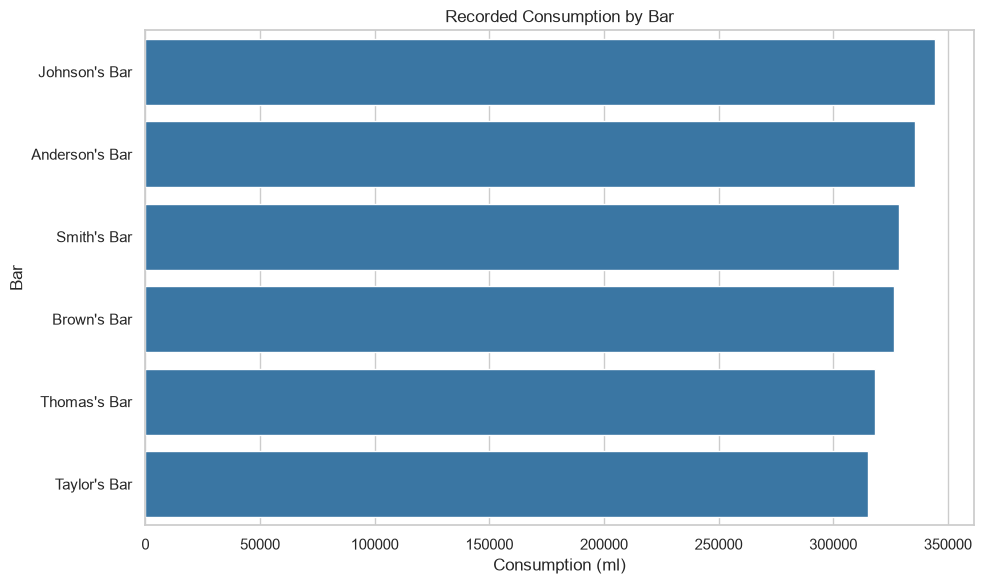

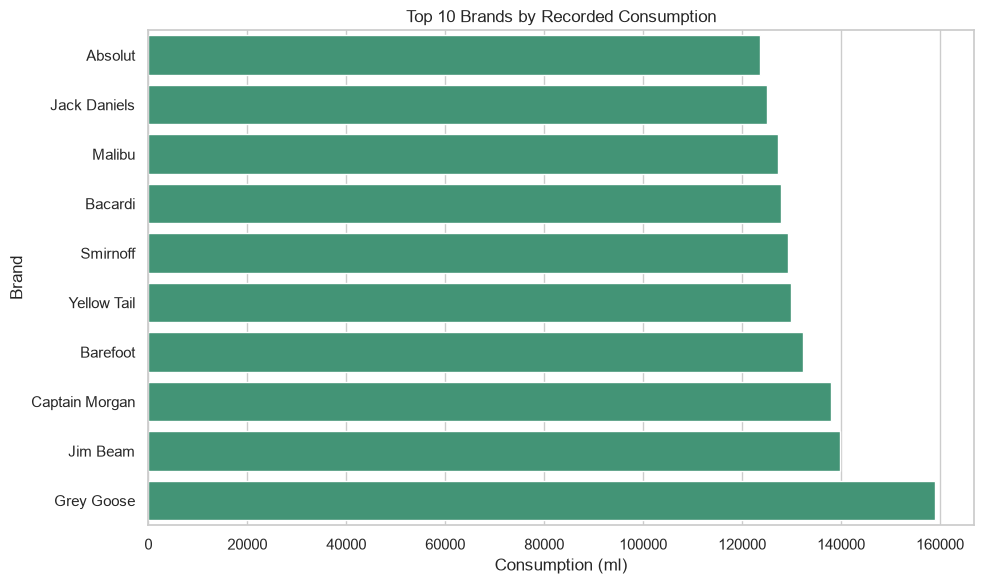

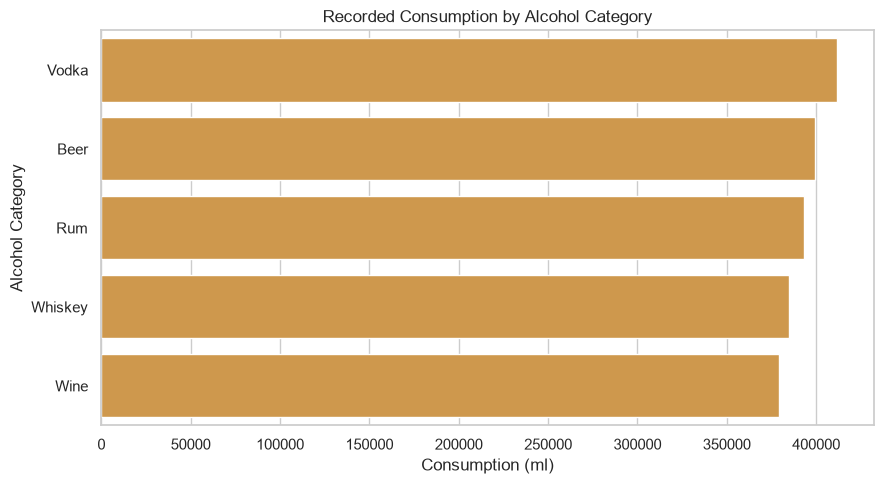

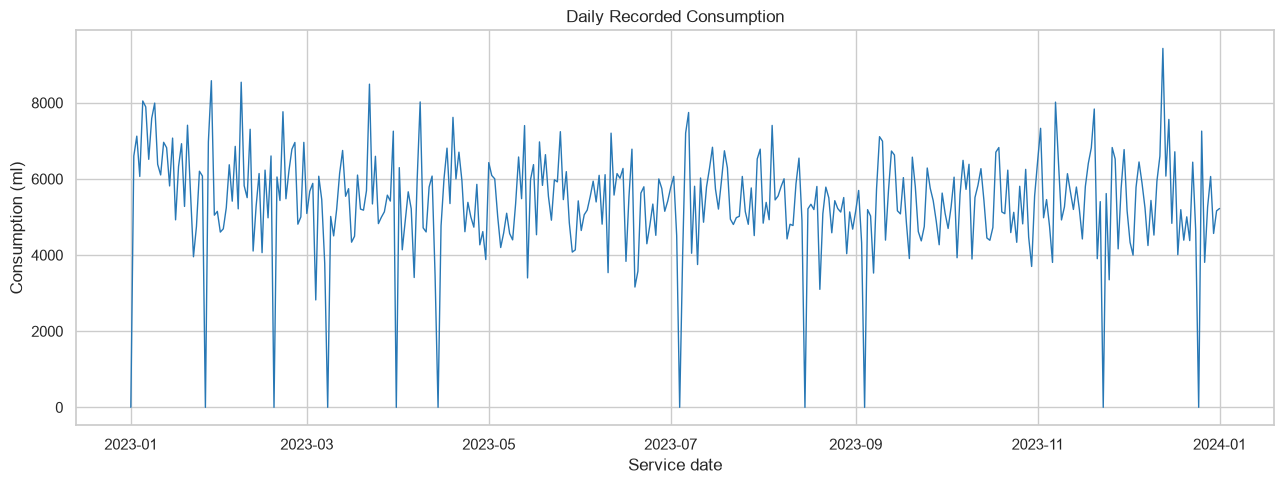

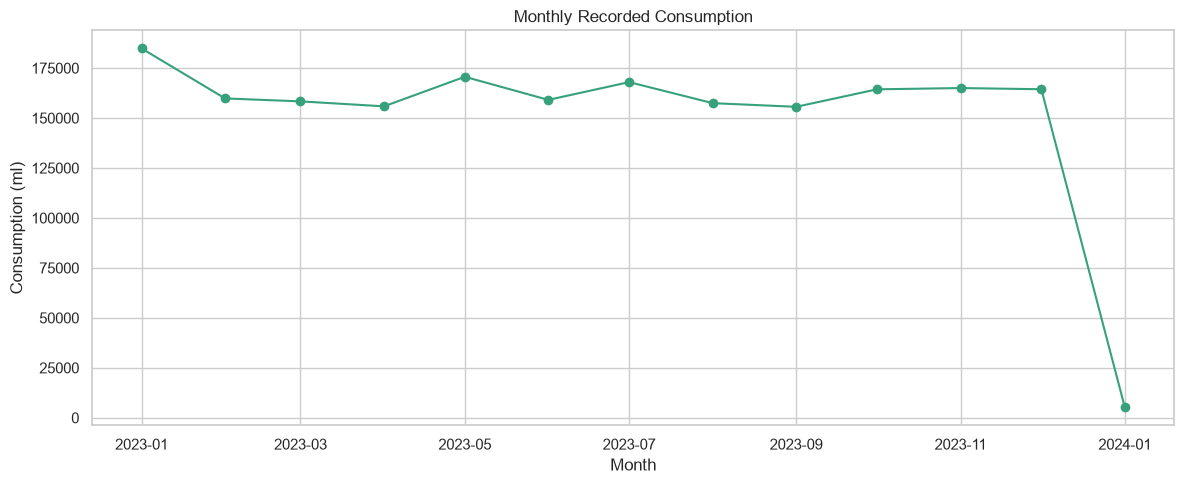

In [6]:
sns.set_theme(style="whitegrid", context="notebook")

fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(
    x=consumption_by_bar.values,
    y=consumption_by_bar.index.astype(str),
    color="#2878B5",
    ax=ax,
)
ax.set(title="Recorded Consumption by Bar", xlabel="Consumption (ml)", ylabel="Bar")
fig.tight_layout()
plt.show()

top_10_brands = consumption_by_brand.head(10).sort_values(ascending=True)
fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(
    x=top_10_brands.values,
    y=top_10_brands.index.astype(str),
    color="#36A17A",
    ax=ax,
)
ax.set(title="Top 10 Brands by Recorded Consumption", xlabel="Consumption (ml)", ylabel="Brand")
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(
    x=consumption_by_alcohol.values,
    y=consumption_by_alcohol.index.astype(str),
    color="#E39C37",
    ax=ax,
)
ax.set(title="Recorded Consumption by Alcohol Category", xlabel="Consumption (ml)", ylabel="Alcohol Category")
fig.tight_layout()
plt.show()

dated_consumption = analysis_df.dropna(subset=[DATE_COLUMN]).copy()
daily_recorded_consumption = (
    dated_consumption.groupby(dated_consumption[DATE_COLUMN].dt.normalize())[CONSUMPTION_COLUMN]
    .sum(min_count=1)
    .sort_index()
)
fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(daily_recorded_consumption.index, daily_recorded_consumption.values, color="#2878B5", linewidth=1)
ax.set(title="Daily Recorded Consumption", xlabel="Service date", ylabel="Consumption (ml)")
fig.tight_layout()
plt.show()

monthly_recorded_consumption = (
    dated_consumption.groupby(dated_consumption[DATE_COLUMN].dt.to_period("M"))[CONSUMPTION_COLUMN]
    .sum(min_count=1)
    .sort_index()
)
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(
    monthly_recorded_consumption.index.to_timestamp(),
    monthly_recorded_consumption.values,
    marker="o",
    color="#36A17A",
)
ax.set(title="Monthly Recorded Consumption", xlabel="Month", ylabel="Consumption (ml)")
fig.tight_layout()
plt.show()

### 5. Observation frequency and date coverage

Repeated bar-brand-date groups below mean multiple source rows for the same bar, brand, and calendar date; they are not necessarily exact duplicate rows. Date gaps are reported only as absent observations. For each bar-brand pair, within-span gaps are measured from that pair's first to last recorded date, avoiding claims about dates before its first or after its last record. None of these gaps are filled or interpreted as zero demand.

In [7]:
dated_observations = analysis_df.dropna(subset=[DATE_COLUMN]).copy()
dated_observations["Service Date"] = dated_observations[DATE_COLUMN].dt.normalize()

records_per_date = dated_observations.groupby("Service Date").size().sort_index()
print(f"Calendar dates with at least one parsed record: {records_per_date.size:,}")
print("Records per date summary:")
display(records_per_date.describe().to_frame("Records per date"))
print("First 5 dates by record count:")
display(records_per_date.head().to_frame("Record count"))

repeated_bar_brand_dates = (
    dated_observations.groupby(
        ["Service Date", BAR_COLUMN, BRAND_COLUMN], dropna=False
    )
    .size()
    .rename("Record count")
    .reset_index()
)
repeated_bar_brand_dates = repeated_bar_brand_dates.loc[
    repeated_bar_brand_dates["Record count"].gt(1)
].sort_values("Record count", ascending=False)
print(f"Repeated bar-brand-date groups: {len(repeated_bar_brand_dates):,}")
if not repeated_bar_brand_dates.empty:
    display(repeated_bar_brand_dates.head(20))
else:
    print("No bar-brand-date groups had more than one record.")

zero_consumption_records = int(analysis_df[CONSUMPTION_COLUMN].eq(0).sum())
missing_consumption_records = int(analysis_df[CONSUMPTION_COLUMN].isna().sum())
print(f"Records with explicitly recorded zero consumption: {zero_consumption_records:,}")
print(f"Records with missing or unparseable consumption: {missing_consumption_records:,}")

observations_per_bar_brand = (
    analysis_df.groupby([BAR_COLUMN, BRAND_COLUMN], dropna=False)
    .size()
    .rename("Record count")
    .reset_index()
    .sort_values("Record count", ascending=False)
)
print("Record-count distribution per bar-brand combination:")
display(observations_per_bar_brand["Record count"].describe().to_frame())
print("Top 10 combinations by number of source records:")
display(observations_per_bar_brand.head(10))

if not records_per_date.empty:
    expected_calendar_dates = pd.date_range(
        start=records_per_date.index.min(),
        end=records_per_date.index.max(),
        freq="D",
    )
    missing_dates_overall = expected_calendar_dates.difference(records_per_date.index)
else:
    missing_dates_overall = pd.DatetimeIndex([])
print(f"Calendar dates with no record anywhere between first and last dates: {len(missing_dates_overall):,}")
if len(missing_dates_overall):
    display(pd.DataFrame({"Date with no recorded observations": missing_dates_overall}))
else:
    print("Every calendar date in the parsed date range has at least one record.")

bar_brand_dates = dated_observations.dropna(subset=[BAR_COLUMN, BRAND_COLUMN])
bar_brand_date_coverage = (
    bar_brand_dates.groupby([BAR_COLUMN, BRAND_COLUMN])["Service Date"]
    .agg(First="min", Last="max", Observed_Dates="nunique")
    .reset_index()
)
bar_brand_date_coverage["Calendar Dates Within First-Last"] = (
    (bar_brand_date_coverage["Last"] - bar_brand_date_coverage["First"]).dt.days + 1
)
bar_brand_date_coverage["Unobserved Dates Within First-Last"] = (
    bar_brand_date_coverage["Calendar Dates Within First-Last"]
    - bar_brand_date_coverage["Observed_Dates"]
)
bar_brand_date_gaps = bar_brand_date_coverage.loc[
    bar_brand_date_coverage["Unobserved Dates Within First-Last"].gt(0)
].sort_values("Unobserved Dates Within First-Last", ascending=False)
print(f"Bar-brand combinations with unobserved calendar dates within their first-last span: {len(bar_brand_date_gaps):,}")
if not bar_brand_date_gaps.empty:
    display(bar_brand_date_gaps.head(20))
else:
    print("No within-span date gaps were found for combinations with parsed dates.")

Calendar dates with at least one parsed record: 366
Records per date summary:


,Records per date
count,366.000000
mean,17.964481
std,2.024872
min,13.000000
25%,17.000000
50%,18.000000
75%,19.000000
max,23.000000


First 5 dates by record count:


,Record count
Service Date,
2023-01-01,17
2023-01-02,20
2023-01-03,19
2023-01-04,18
2023-01-05,20


Repeated bar-brand-date groups: 0
No bar-brand-date groups had more than one record.
Records with explicitly recorded zero consumption: 910
Records with missing or unparseable consumption: 0
Record-count distribution per bar-brand combination:


,Record count
count,96.000000
mean,68.489583
std,11.148750
min,40.000000
25%,60.000000
50%,69.500000
75%,76.000000
max,99.000000


Top 10 combinations by number of source records:


,Bar Name,Brand Name,Record count
36,Johnson's Bar,Captain Morgan,99
31,Brown's Bar,Yellow Tail,88
48,Smith's Bar,Absolut,86
86,Thomas's Bar,Grey Goose,86
24,Brown's Bar,Jack Daniels,84
15,Anderson's Bar,Yellow Tail,84
70,Taylor's Bar,Grey Goose,83
95,Thomas's Bar,Yellow Tail,83
84,Thomas's Bar,Captain Morgan,82
32,Johnson's Bar,Absolut,82


Calendar dates with no record anywhere between first and last dates: 0
Every calendar date in the parsed date range has at least one record.
Bar-brand combinations with unobserved calendar dates within their first-last span: 96


,Bar Name,Brand Name,First,Last,Observed_Dates,Calendar Dates Within First-Last,Unobserved Dates Within First-Last
87,Thomas's Bar,Heineken,2023-01-08,2023-12-30,47,357,310
51,Smith's Bar,Budweiser,2023-01-03,2023-12-22,46,354,308
83,Thomas's Bar,Budweiser,2023-01-04,2023-12-25,48,356,308
12,Anderson's Bar,Miller,2023-01-01,2023-12-29,56,363,307
37,Johnson's Bar,Coors,2023-01-01,2024-01-01,59,366,307
23,Brown's Bar,Heineken,2023-01-03,2024-01-01,57,364,307
21,Brown's Bar,Coors,2023-01-07,2023-12-25,46,353,307
69,Taylor's Bar,Coors,2023-01-02,2023-12-30,56,363,307
53,Smith's Bar,Coors,2023-01-10,2023-12-28,47,353,306
55,Smith's Bar,Heineken,2023-01-08,2023-12-29,50,356,306


### 6. Interpretation and limitations

- The tables and plots describe consumption recorded in the supplied rows; they do not represent estimates of demand on unobserved dates.
- Explicit zero-consumption records are counted separately from missing consumption values and from dates with no observations.
- Balance differences and negative or unparseable values are diagnostic flags only. The source `df` is preserved, and no inconsistent records are silently corrected or removed.
- Date-gap counts depend on the recorded date range. A gap does not establish that the bar was open, the product was available, or demand was zero on that date.
- The source contains transaction/observation records, so repeated bar-brand-date entries may represent multiple legitimate observations and are not automatically deduplicated.

Use the validation outputs and grouped summaries above to review any data limitations before proceeding. Forecasting is intentionally not included in this phase.

## Phase 4: Demand Analysis and Feature Engineering

This phase creates daily bar-brand observations from the original records, analyzes observation coverage, visualizes recorded consumption patterns, and builds lag and calendar features for a future model. The source DataFrame `df` is not modified. Missing dates remain unobserved (not zero), and all summaries describe recorded consumption rather than complete or estimated demand. Model training is intentionally out of scope.

### 4.1 Create the daily demand dataset

The existing parsed date in `analysis_df` is normalized to a calendar date. Each row in `daily_demand` represents one observed date, bar, and brand. Consumption is summed from recorded values, `Source_Records` counts original rows, and `Alcohol_Type` is retained after checking it is consistent within each daily group. Dates with no source rows are not created.

In [8]:
daily_source = analysis_df[
    [DATE_COLUMN, BAR_COLUMN, BRAND_COLUMN, ALCOHOL_COLUMN, CONSUMPTION_COLUMN]
].copy()
daily_source["Date"] = daily_source[DATE_COLUMN].dt.normalize()

if daily_source["Date"].isna().any():
    raise ValueError("Rows with invalid dates cannot be assigned to daily demand groups.")

daily_source = daily_source.rename(
    columns={
        ALCOHOL_COLUMN: "Alcohol_Type",
        CONSUMPTION_COLUMN: "Daily_Consumption_ml",
    }
)
daily_group_columns = ["Date", BAR_COLUMN, BRAND_COLUMN]

alcohol_type_counts = daily_source.groupby(
    daily_group_columns, dropna=False
)["Alcohol_Type"].nunique(dropna=False)
if alcohol_type_counts.gt(1).any():
    conflicting_groups = alcohol_type_counts[alcohol_type_counts.gt(1)]
    raise ValueError(
        "Alcohol_Type is inconsistent within daily bar-brand groups: "
        f"{conflicting_groups.head().to_dict()}"
    )

daily_demand = (
    daily_source.groupby(
        daily_group_columns, as_index=False, dropna=False, sort=True
    )
    .agg(
        Daily_Consumption_ml=(
            "Daily_Consumption_ml",
            lambda values: values.sum(min_count=1),
        ),
        Alcohol_Type=("Alcohol_Type", "first"),
        Source_Records=("Daily_Consumption_ml", "size"),
    )
    .sort_values([BAR_COLUMN, BRAND_COLUMN, "Date"])
    .reset_index(drop=True)
)

demand_target = "Daily_Consumption_ml"

print(f"Daily demand shape: {daily_demand.shape[0]:,} rows x {daily_demand.shape[1]} columns")
print(f"Source records represented: {daily_demand['Source_Records'].sum():,}")
print("Daily demand columns:")
print(daily_demand.columns.tolist())
display(daily_demand.head())

Daily demand shape: 6,575 rows x 6 columns
Source records represented: 6,575
Daily demand columns:
['Date', 'Bar Name', 'Brand Name', 'Daily_Consumption_ml', 'Alcohol_Type', 'Source_Records']


,Date,Bar Name,Brand Name,Daily_Consumption_ml,Alcohol_Type,Source_Records
0,2023-01-02,Anderson's Bar,Absolut,118.62,Vodka,1
1,2023-01-05,Anderson's Bar,Absolut,463.20,Vodka,1
2,2023-01-06,Anderson's Bar,Absolut,453.02,Vodka,1
3,2023-01-08,Anderson's Bar,Absolut,275.08,Vodka,1
4,2023-01-11,Anderson's Bar,Absolut,0.00,Vodka,1


### 4.2 Observation coverage by bar and brand

Coverage is calculated from observed daily rows. `Recorded_Observations` counts source records, while `Observed_Days` counts distinct date-bar-brand rows. Gaps are elapsed calendar days between consecutive observed dates; a one-day gap identifies consecutive-day observations, which are listed in the following table. A gap does not imply zero consumption or that the product was available on the missing date.

In [9]:
coverage_observations = daily_demand.sort_values(
    [BAR_COLUMN, BRAND_COLUMN, "Date"]
).copy()
coverage_observations["Gap_Days"] = coverage_observations.groupby(
    [BAR_COLUMN, BRAND_COLUMN], dropna=False, sort=False
)["Date"].diff().dt.days
coverage_groups = coverage_observations.groupby(
    [BAR_COLUMN, BRAND_COLUMN], dropna=False, sort=False
)
coverage_observations["Previous_Observation_Date"] = coverage_groups["Date"].shift(1)
coverage_observations["Previous_Daily_Consumption_ml"] = coverage_groups[
    demand_target
].shift(1)

bar_brand_coverage = (
    coverage_observations.groupby(
        [BAR_COLUMN, BRAND_COLUMN], dropna=False, sort=False
    )
    .agg(
        Recorded_Observations=("Source_Records", "sum"),
        Observed_Days=("Date", "size"),
        First_Observation_Date=("Date", "min"),
        Last_Observation_Date=("Date", "max"),
        Average_Gap_Days=("Gap_Days", "mean"),
        Maximum_Gap_Days=("Gap_Days", "max"),
        Consecutive_Day_Observation_Pairs=(
            "Gap_Days", lambda gaps: int(gaps.eq(1).sum())
        ),
    )
    .reset_index()
    .sort_values([BAR_COLUMN, BRAND_COLUMN])
    .reset_index(drop=True)
)
bar_brand_coverage["Has_Consecutive_Day_Observations"] = (
    bar_brand_coverage["Consecutive_Day_Observation_Pairs"].gt(0)
)

print(f"Bar-brand combinations analyzed: {len(bar_brand_coverage):,}")
display(bar_brand_coverage.head(10))
print("Gap statistics across bar-brand combinations:")
display(
    bar_brand_coverage[
        ["Average_Gap_Days", "Maximum_Gap_Days", "Consecutive_Day_Observation_Pairs"]
    ].describe().T
)
print(
    "Combinations with at least one consecutive-day pair: "
    f"{bar_brand_coverage['Has_Consecutive_Day_Observations'].sum():,}"
)
consecutive_day_observations = coverage_observations.loc[
    coverage_observations["Gap_Days"].eq(1),
    [
        BAR_COLUMN,
        BRAND_COLUMN,
        "Previous_Observation_Date",
        "Date",
        "Previous_Daily_Consumption_ml",
        demand_target,
    ],
].rename(
    columns={
        "Previous_Observation_Date": "Previous_Date",
        "Date": "Observation_Date",
        "Previous_Daily_Consumption_ml": "Previous_Consumption_ml",
    }
)
print(f"Consecutive-day observation pairs: {len(consecutive_day_observations):,}")
display(consecutive_day_observations.head(20))


Bar-brand combinations analyzed: 96


,Bar Name,Brand Name,Recorded_Observations,Observed_Days,First_Observation_Date,Last_Observation_Date,Average_Gap_Days,Maximum_Gap_Days,Consecutive_Day_Observation_Pairs,Has_Consecutive_Day_Observations
0,Anderson's Bar,Absolut,69,69,2023-01-02,2023-12-25,5.250000,18.0,10,True
1,Anderson's Bar,Bacardi,74,74,2023-01-01,2023-12-31,4.986301,22.0,13,True
2,Anderson's Bar,Barefoot,80,80,2023-01-03,2023-12-30,4.569620,22.0,17,True
3,Anderson's Bar,Budweiser,48,48,2023-01-09,2023-12-26,7.468085,35.0,7,True
4,Anderson's Bar,Captain Morgan,73,73,2023-01-13,2023-12-19,4.722222,24.0,17,True
5,Anderson's Bar,Coors,60,60,2023-01-02,2024-01-01,6.169492,26.0,10,True
6,Anderson's Bar,Grey Goose,68,68,2023-01-09,2023-12-30,5.298507,22.0,11,True
7,Anderson's Bar,Heineken,60,60,2023-01-10,2023-12-31,6.016949,34.0,15,True
8,Anderson's Bar,Jack Daniels,81,81,2023-01-08,2024-01-01,4.475000,19.0,11,True
9,Anderson's Bar,Jameson,73,73,2023-01-06,2023-12-30,4.972222,16.0,13,True


Gap statistics across bar-brand combinations:


,count,mean,std,min,25%,50%,75%,max
Average_Gap_Days,96.0,5.436082,0.987611,3.653061,4.784079,5.151616,6.038355,8.538462
Maximum_Gap_Days,96.0,23.958333,5.939904,15.000000,20.000000,23.000000,26.250000,40.000000
Consecutive_Day_Observation_Pairs,96.0,12.666667,4.443011,3.000000,9.000000,13.000000,16.000000,27.000000


Combinations with at least one consecutive-day pair: 96
Consecutive-day observation pairs: 1,216


,Bar Name,Brand Name,Previous_Date,Observation_Date,Previous_Consumption_ml,Daily_Consumption_ml
2,Anderson's Bar,Absolut,2023-01-05,2023-01-06,463.20,453.02
7,Anderson's Bar,Absolut,2023-01-31,2023-02-01,0.00,0.00
9,Anderson's Bar,Absolut,2023-02-04,2023-02-05,0.00,0.00
11,Anderson's Bar,Absolut,2023-02-22,2023-02-23,0.00,395.69
21,Anderson's Bar,Absolut,2023-04-11,2023-04-12,255.30,301.09
30,Anderson's Bar,Absolut,2023-06-10,2023-06-11,0.00,0.00
33,Anderson's Bar,Absolut,2023-06-20,2023-06-21,123.25,273.59
36,Anderson's Bar,Absolut,2023-06-28,2023-06-29,348.03,579.09
50,Anderson's Bar,Absolut,2023-09-10,2023-09-11,0.00,0.00
64,Anderson's Bar,Absolut,2023-12-06,2023-12-07,480.21,504.45


### 4.3 Recorded demand pattern visualizations

The charts below aggregate only dates with recorded observations. Selected-brand daily lines use `NaN` for dates with no observation, so gaps appear as breaks rather than zero consumption. Weekly averages are calculated across observed bar-brand-days, and monthly totals include recorded values only. These are descriptive views, not estimates of complete demand.

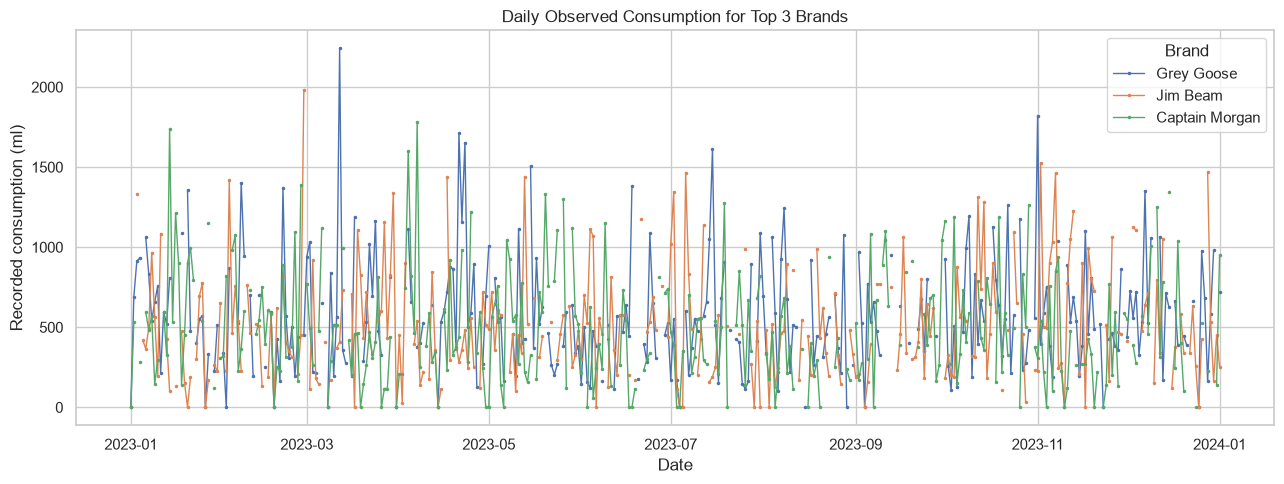

Weekly pattern (observed bar-brand-days only):


,Mean_Consumption_per_Observed_BarBrandDay,Observed_BarBrandDays,Total_Recorded_Consumption_ml
Monday,289.015411,937,270807.44
Tuesday,298.122761,938,279639.15
Wednesday,311.683543,937,292047.48
Thursday,297.083294,935,277772.88
Friday,302.749509,937,283676.29
Saturday,299.598820,941,281922.49
Sunday,297.700979,950,282815.93


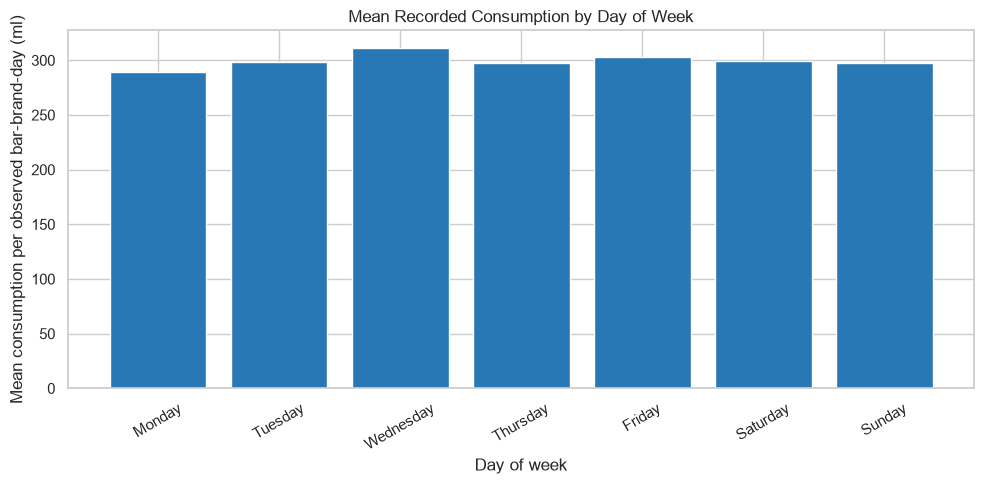

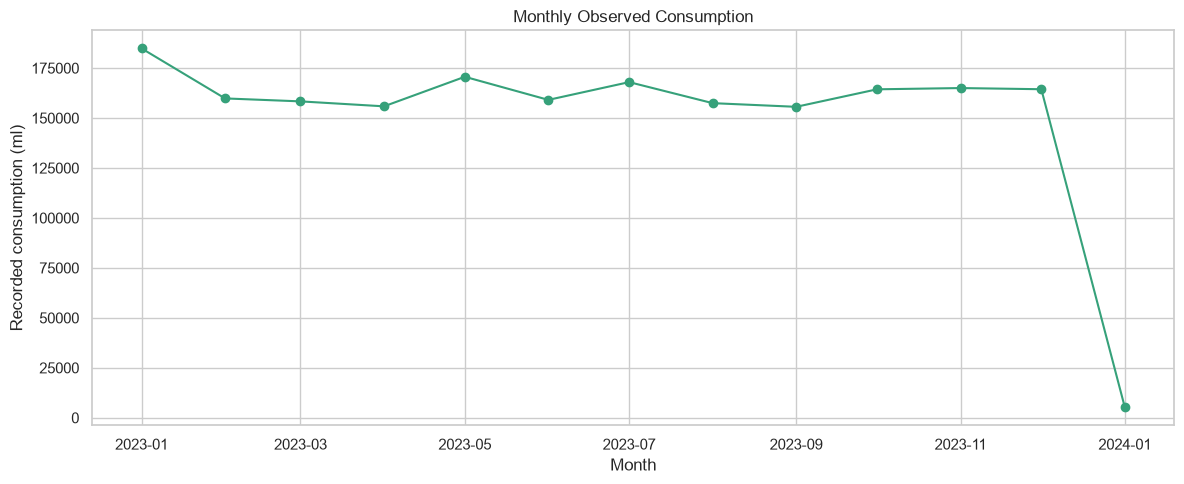

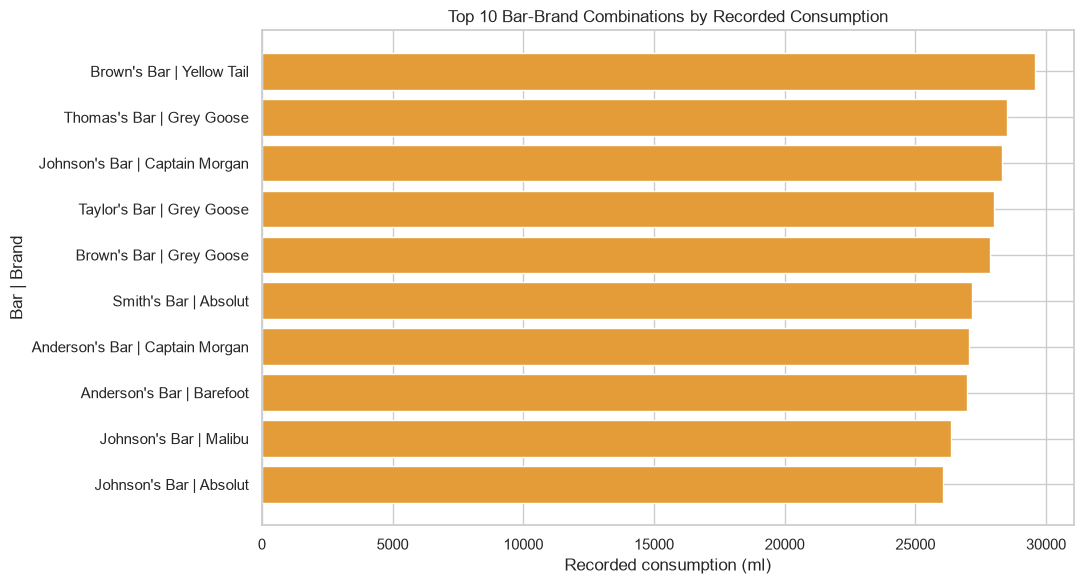

In [10]:
brand_totals = daily_demand.groupby(BRAND_COLUMN)[demand_target].sum(min_count=1)
selected_brands = brand_totals.nlargest(min(3, len(brand_totals))).index.tolist()
selected_brand_daily = (
    daily_demand.loc[daily_demand[BRAND_COLUMN].isin(selected_brands)]
    .groupby(["Date", BRAND_COLUMN])[demand_target]
    .sum(min_count=1)
    .unstack(BRAND_COLUMN)
)
calendar_dates = pd.date_range(
    daily_demand["Date"].min(), daily_demand["Date"].max(), freq="D"
)
selected_brand_daily = selected_brand_daily.reindex(calendar_dates)

fig, ax = plt.subplots(figsize=(13, 5))
for brand in selected_brands:
    ax.plot(
        selected_brand_daily.index,
        selected_brand_daily[brand],
        marker=".",
        markersize=3,
        linewidth=1,
        label=str(brand),
    )
ax.set(
    title="Daily Observed Consumption for Top 3 Brands",
    xlabel="Date",
    ylabel="Recorded consumption (ml)",
)
ax.legend(title="Brand")
fig.tight_layout()
plt.show()

weekday_names = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
weekly_consumption = (
    daily_demand.assign(DayOfWeek=daily_demand["Date"].dt.day_of_week)
    .groupby("DayOfWeek")
    .agg(
        Mean_Consumption_per_Observed_BarBrandDay=(demand_target, "mean"),
        Observed_BarBrandDays=("Date", "size"),
        Total_Recorded_Consumption_ml=(
            demand_target, lambda values: values.sum(min_count=1)
        ),
    )
    .reindex(range(7))
)
weekly_consumption.index = weekday_names
print("Weekly pattern (observed bar-brand-days only):")
display(weekly_consumption)

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(
    weekly_consumption.index,
    weekly_consumption["Mean_Consumption_per_Observed_BarBrandDay"],
    color="#2878B5",
)
ax.set(
    title="Mean Recorded Consumption by Day of Week",
    xlabel="Day of week",
    ylabel="Mean consumption per observed bar-brand-day (ml)",
)
ax.tick_params(axis="x", rotation=30)
fig.tight_layout()
plt.show()

monthly_observed_consumption = (
    daily_demand.groupby(daily_demand["Date"].dt.to_period("M"))[demand_target]
    .sum(min_count=1)
    .sort_index()
)
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(
    monthly_observed_consumption.index.to_timestamp(),
    monthly_observed_consumption.values,
    marker="o",
    color="#36A17A",
)
ax.set(
    title="Monthly Observed Consumption",
    xlabel="Month",
    ylabel="Recorded consumption (ml)",
)
fig.tight_layout()
plt.show()

bar_brand_totals = (
    daily_demand.groupby([BAR_COLUMN, BRAND_COLUMN])[demand_target]
    .sum(min_count=1)
    .sort_values(ascending=False)
)
top_10_bar_brand = bar_brand_totals.head(10).sort_values(ascending=True)
top_10_labels = [f"{bar} | {brand}" for bar, brand in top_10_bar_brand.index]
fig, ax = plt.subplots(figsize=(11, 6))
ax.barh(top_10_labels, top_10_bar_brand.values, color="#E39C37")
ax.set(
    title="Top 10 Bar-Brand Combinations by Recorded Consumption",
    xlabel="Recorded consumption (ml)",
    ylabel="Bar | Brand",
)
fig.tight_layout()
plt.show()

### 4.4 Historical and calendar features

- **Lag (`Previous_Consumption_ml`)** is the consumption on the previous recorded date for the same bar-brand pair; it never crosses groups.
- **Previous-three-record average** smooths short-term variation by averaging the three prior recorded observations. It excludes the current row and is unavailable until three prior observations exist.
- **Observation gaps** matter because consecutive rows may be separated by different numbers of calendar days. `Days_Since_Previous_Record` records that elapsed time; it does not fill the gap.
- **Temporal leakage prevention:** rows are sorted by bar, brand, and date before grouped `shift` and `rolling` operations. The rolling window is shifted before averaging, so it only uses earlier observations. `DayOfWeek`, `Month`, and `IsWeekend` use the known date of the row.

In [11]:
feature_data = daily_demand.sort_values(
    [BAR_COLUMN, BRAND_COLUMN, "Date"]
).reset_index(drop=True).copy()
feature_group_keys = [BAR_COLUMN, BRAND_COLUMN]
feature_groups = feature_data.groupby(
    feature_group_keys, dropna=False, sort=False
)

feature_data["Previous_Consumption_ml"] = feature_groups[demand_target].shift(1)
feature_data["Previous_3_Records_Avg_ml"] = feature_groups[
    demand_target
].transform(lambda values: values.shift(1).rolling(window=3, min_periods=3).mean())
feature_data["Days_Since_Previous_Record"] = feature_groups["Date"].diff().dt.days
feature_data["DayOfWeek"] = feature_data["Date"].dt.day_of_week
feature_data["Month"] = feature_data["Date"].dt.month
feature_data["IsWeekend"] = feature_data["Date"].dt.day_of_week.ge(5)

historical_feature_columns = [
    "Previous_Consumption_ml",
    "Previous_3_Records_Avg_ml",
    "Days_Since_Previous_Record",
]
calendar_feature_columns = ["DayOfWeek", "Month", "IsWeekend"]
model_feature_columns = historical_feature_columns + calendar_feature_columns

print("Feature columns:")
print(model_feature_columns)
print("Feature data sample:")
display(
    feature_data[
        ["Date", BAR_COLUMN, BRAND_COLUMN, demand_target, *model_feature_columns]
    ].head(10)
)

Feature columns:
['Previous_Consumption_ml', 'Previous_3_Records_Avg_ml', 'Days_Since_Previous_Record', 'DayOfWeek', 'Month', 'IsWeekend']
Feature data sample:


,Date,Bar Name,Brand Name,Daily_Consumption_ml,Previous_Consumption_ml,Previous_3_Records_Avg_ml,Days_Since_Previous_Record,DayOfWeek,Month,IsWeekend
0,2023-01-02,Anderson's Bar,Absolut,118.62,NaN,NaN,NaN,0,1,False
1,2023-01-05,Anderson's Bar,Absolut,463.20,118.62,NaN,3.0,3,1,False
2,2023-01-06,Anderson's Bar,Absolut,453.02,463.20,NaN,1.0,4,1,False
3,2023-01-08,Anderson's Bar,Absolut,275.08,453.02,344.946667,2.0,6,1,True
4,2023-01-11,Anderson's Bar,Absolut,0.00,275.08,397.100000,3.0,2,1,False
5,2023-01-26,Anderson's Bar,Absolut,0.00,0.00,242.700000,15.0,3,1,False
6,2023-01-31,Anderson's Bar,Absolut,0.00,0.00,91.693333,5.0,1,1,False
7,2023-02-01,Anderson's Bar,Absolut,0.00,0.00,0.000000,1.0,2,2,False
8,2023-02-04,Anderson's Bar,Absolut,0.00,0.00,0.000000,3.0,5,2,True
9,2023-02-05,Anderson's Bar,Absolut,0.00,0.00,0.000000,1.0,6,2,True


### 4.5 Model-ready dataset

`model_data` retains the target and descriptive keys together with the engineered features. Only rows missing required historical features are excluded; in this setup the first three observed rows in each bar-brand group cannot have a full previous-three-record average. No consumption is imputed, and no date is added. A future modeling phase should use chronological validation; model training is not performed here.

In [12]:
model_data = feature_data.dropna(
    subset=historical_feature_columns
).copy().reset_index(drop=True)

model_target_column = demand_target
model_key_columns = ["Date", BAR_COLUMN, BRAND_COLUMN]

print(f"model_data shape: {model_data.shape[0]:,} rows x {model_data.shape[1]} columns")
print("Missing values by model_data column:")
display(model_data.isna().sum().rename("Missing values").to_frame())
print(f"Exact duplicate rows: {model_data.duplicated().sum():,}")
print(
    "Duplicate Date-Bar-Brand keys: "
    f"{model_data.duplicated(subset=model_key_columns).sum():,}"
)
print("Model feature columns:")
print(model_feature_columns)
print(
    "Date range: "
    f"{model_data['Date'].min().date()} through {model_data['Date'].max().date()}"
)
print(
    "Bar-brand combinations in model_data: "
    f"{model_data[feature_group_keys].drop_duplicates().shape[0]:,}"
)
print("Historical feature statistics:")
display(model_data[historical_feature_columns].describe().T)
print("Calendar feature statistics:")
display(model_data[calendar_feature_columns].describe().T)
print(
    "Weekend share: "
    f"{model_data['IsWeekend'].mean():.1%} of model-ready observations"
)

model_data shape: 6,287 rows x 12 columns
Missing values by model_data column:


,Missing values
Date,0
Bar Name,0
Brand Name,0
Daily_Consumption_ml,0
Alcohol_Type,0
Source_Records,0
Previous_Consumption_ml,0
Previous_3_Records_Avg_ml,0
Days_Since_Previous_Record,0
DayOfWeek,0


Exact duplicate rows: 0
Duplicate Date-Bar-Brand keys: 0
Model feature columns:
['Previous_Consumption_ml', 'Previous_3_Records_Avg_ml', 'Days_Since_Previous_Record', 'DayOfWeek', 'Month', 'IsWeekend']
Date range: 2023-01-06 through 2024-01-01
Bar-brand combinations in model_data: 96
Historical feature statistics:


,count,mean,std,min,25%,50%,75%,max
Previous_Consumption_ml,6287.0,298.806972,192.109146,0.0,156.400000,299.640000,450.425,1180.58
Previous_3_Records_Avg_ml,6287.0,299.321465,131.666632,0.0,228.446667,312.296667,388.855,734.02
Days_Since_Previous_Record,6287.0,5.282647,4.846560,1.0,2.000000,4.000000,7.000,40.00


Calendar feature statistics:


,count,mean,std,min,25%,50%,75%,max
DayOfWeek,6287.0,3.012407,2.000041,0.0,1.0,3.0,5.0,6.0
Month,6287.0,6.704470,3.345349,1.0,4.0,7.0,10.0,12.0


Weekend share: 28.9% of model-ready observations


### 4.6 Manual feature validation

The following check selects a bar-brand pair with at least four recorded dates and verifies the fourth row against the three earlier recorded consumptions. It also checks that the first row in every group has no prior-record features. This confirms the lag and rolling calculations use history only and do not carry values across groups.

In [13]:
validation_pair = bar_brand_coverage.sort_values(
    "Recorded_Observations", ascending=False
).iloc[0]
validation_mask = (
    feature_data[BAR_COLUMN].eq(validation_pair[BAR_COLUMN])
    & feature_data[BRAND_COLUMN].eq(validation_pair[BRAND_COLUMN])
)
validation_group = feature_data.loc[validation_mask].sort_values("Date").head(4).copy()
if len(validation_group) < 4:
    raise AssertionError("Manual validation requires at least four observed dates.")

prior_values = validation_group[demand_target].iloc[:3]
checked_row = validation_group.iloc[3]
expected_previous = prior_values.iloc[-1]
expected_previous_three_average = prior_values.mean()
expected_elapsed_days = (
    checked_row["Date"] - validation_group["Date"].iloc[2]
).days

assert np.isclose(checked_row["Previous_Consumption_ml"], expected_previous)
assert np.isclose(
    checked_row["Previous_3_Records_Avg_ml"], expected_previous_three_average
)
assert checked_row["Days_Since_Previous_Record"] == expected_elapsed_days

first_rows_by_group = feature_data.groupby(
    feature_group_keys, dropna=False, sort=False
).head(1)
assert first_rows_by_group[historical_feature_columns].isna().all().all()

print(
    "Manual validation pair: "
    f"{validation_pair[BAR_COLUMN]} / {validation_pair[BRAND_COLUMN]}"
)
print("The fourth observed row was checked against these three prior observations:")
display(
    validation_group[
        ["Date", demand_target, *historical_feature_columns]
    ]
)
print(
    "Manual checks passed: lag = "
    f"{expected_previous:.2f} ml; previous-three average = "
    f"{expected_previous_three_average:.2f} ml; elapsed gap = "
    f"{expected_elapsed_days} day(s)."
)

Manual validation pair: Johnson's Bar / Captain Morgan
The fourth observed row was checked against these three prior observations:


,Date,Daily_Consumption_ml,Previous_Consumption_ml,Previous_3_Records_Avg_ml,Days_Since_Previous_Record
2471,2023-01-07,120.36,NaN,NaN,NaN
2472,2023-01-17,582.67,120.36,NaN,10.0
2473,2023-01-20,360.70,582.67,NaN,3.0
2474,2023-01-22,366.66,360.70,354.576667,2.0


Manual checks passed: lag = 360.70 ml; previous-three average = 354.58 ml; elapsed gap = 2 day(s).


## Phase 5: Demand Forecasting and Model Evaluation

### Define the forecasting problem

The target is `Daily_Consumption_ml` for the next **recorded** bar-brand observation. This is an observation-level, one-step-ahead forecasting exercise: the interval to the next recorded observation can vary, and the exercise does not produce a validated prediction for every calendar day. The Phase 4 `model_data` is reused; the original CSV and earlier analysis are unchanged. Inventory optimization and simulation are not part of this phase.

### 5.1 Chronological train-test split

A random row split could place later records in training and earlier records in testing. Instead, observations are sorted by date and split at a boundary between unique dates. Approximately the first 80% of dates are used for training and the final 20% for testing, so every training date precedes every test date.

In [14]:
model_data_sorted = model_data.sort_values("Date").reset_index(drop=True)
unique_model_dates = pd.Index(
    model_data_sorted["Date"].drop_duplicates().sort_values()
)
if len(unique_model_dates) < 2:
    raise ValueError("At least two unique dates are required for chronological validation.")

train_date_count = int(np.floor(len(unique_model_dates) * 0.80))
train_date_count = max(1, min(train_date_count, len(unique_model_dates) - 1))
split_date = unique_model_dates[train_date_count]
train_data = model_data_sorted.loc[model_data_sorted["Date"] < split_date].copy()
test_data = model_data_sorted.loc[model_data_sorted["Date"] >= split_date].copy()

train_dates = pd.Index(train_data["Date"].drop_duplicates())
test_dates = pd.Index(test_data["Date"].drop_duplicates())
if train_dates.max() >= test_dates.min():
    raise AssertionError("Training dates must all precede test dates.")

print(f"Unique dates: {len(unique_model_dates):,}")
print(f"Training dates: {len(train_dates):,} ({len(train_dates) / len(unique_model_dates):.1%})")
print(f"Test dates: {len(test_dates):,} ({len(test_dates) / len(unique_model_dates):.1%})")
print(f"Split date (first test date): {split_date.date()}")
print(
    "Training date range: "
    f"{train_data['Date'].min().date()} through {train_data['Date'].max().date()}"
)
print(
    "Test date range: "
    f"{test_data['Date'].min().date()} through {test_data['Date'].max().date()}"
)
print(f"Training rows: {len(train_data):,}; test rows: {len(test_data):,}")

Unique dates: 360
Training dates: 288 (80.0%)
Test dates: 72 (20.0%)
Split date (first test date): 2023-10-22
Training date range: 2023-01-06 through 2023-10-21
Test date range: 2023-10-22 through 2024-01-01
Training rows: 5,007; test rows: 1,280


### 5.2 Select the target and features

The six numerical/calendar features and three categorical identifiers below are taken from Phase 4. `Date` is used to establish the split, not passed as a raw predictor. The target is kept separate from both feature matrices to prevent target leakage. `OneHotEncoder(handle_unknown="ignore")` will safely handle a category appearing in the test dates that was not present in training.

In [15]:
target_column = "Daily_Consumption_ml"
numerical_features = [
    "Previous_Consumption_ml",
    "Previous_3_Records_Avg_ml",
    "Days_Since_Previous_Record",
    "DayOfWeek",
    "Month",
    "IsWeekend",
]
categorical_features = [BAR_COLUMN, BRAND_COLUMN, "Alcohol_Type"]
feature_columns = numerical_features + categorical_features

if target_column in feature_columns:
    raise AssertionError("The target must not be included in the feature matrix.")
missing_features = [column for column in feature_columns if column not in model_data.columns]
if missing_features:
    raise KeyError(f"Model features are missing from model_data: {missing_features}")

X_train = train_data[feature_columns].copy()
X_test = test_data[feature_columns].copy()
y_train = train_data[target_column].copy()
y_test = test_data[target_column].copy()

if X_train.isna().any().any() or X_test.isna().any().any():
    raise ValueError("Missing feature values were found; review model_data before fitting.")

category_support_rows = []
for column in categorical_features:
    training_categories = set(X_train[column].unique())
    test_categories = set(X_test[column].unique())
    unseen_categories = sorted(test_categories - training_categories, key=str)
    category_support_rows.append(
        {
            "Feature": column,
            "Training categories": len(training_categories),
            "Test categories not seen in training": len(unseen_categories),
            "Unseen test categories (handled by encoder)": unseen_categories,
        }
    )
category_support = pd.DataFrame(category_support_rows)

print(f"Target: {target_column}")
print(f"Numerical features ({len(numerical_features)}): {numerical_features}")
print(f"Categorical features ({len(categorical_features)}): {categorical_features}")
print(f"Target included in feature matrix: {target_column in feature_columns}")
print("Test category coverage:")
display(category_support)

Target: Daily_Consumption_ml
Numerical features (6): ['Previous_Consumption_ml', 'Previous_3_Records_Avg_ml', 'Days_Since_Previous_Record', 'DayOfWeek', 'Month', 'IsWeekend']
Categorical features (3): ['Bar Name', 'Brand Name', 'Alcohol_Type']
Target included in feature matrix: False
Test category coverage:


,Feature,Training categories,Test categories not seen in training,Unseen test categories (handled by encoder)
0,Bar Name,6,0,[]
1,Brand Name,16,0,[]
2,Alcohol_Type,5,0,[]


### 5.3 Baseline and Random Forest models

The **Previous Observation Baseline** predicts that the next recorded consumption equals the previous recorded consumption for the same bar-brand pair. It is a simple reference that any more complex model should be compared against.

A **Random Forest** combines many decision trees to model non-linear relationships. The pipeline first one-hot encodes the categorical fields and passes through the numeric fields, then fits the forest. Because the complete pipeline is fit only on training rows, category encoding is learned without looking at the test data.

In [16]:
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

baseline_predictions = X_test["Previous_Consumption_ml"].to_numpy(dtype=float)

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features,
        ),
    ],
    remainder="passthrough",
)
random_forest = RandomForestRegressor(
    n_estimators=200,
    max_depth=10,
    min_samples_split=5,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1,
)
random_forest_pipeline = Pipeline(
    steps=[("preprocessor", preprocessor), ("model", random_forest)]
)
random_forest_pipeline.fit(X_train, y_train)
random_forest_predictions = random_forest_pipeline.predict(X_test)

print("Previous Observation Baseline predictions created.")
print(
    "Random Forest pipeline fitted on training rows only; "
    f"trees: {random_forest_pipeline.named_steps['model'].n_estimators}."
)
print(f"Baseline predictions: {len(baseline_predictions):,}")
print(f"Random Forest predictions: {len(random_forest_predictions):,}")

Previous Observation Baseline predictions created.
Random Forest pipeline fitted on training rows only; trees: 200.
Baseline predictions: 1,280
Random Forest predictions: 1,280


### 5.4 Evaluate the models

- **MAE** (Mean Absolute Error) is the average absolute prediction error in ml; smaller is better.
- **RMSE** (Root Mean Squared Error) is in ml and penalizes large errors more strongly; smaller is better.
- **WAPE** (Weighted Absolute Percentage Error) is total absolute error divided by total absolute actual consumption, expressed as a percentage; smaller is better. If the denominator is zero, WAPE is undefined and is reported as `NaN` rather than dividing by zero.

The improvement column is the relative reduction in each error metric versus the baseline. A positive value means the Random Forest error is lower; a negative value means it is higher.

In [17]:
from sklearn.metrics import mean_absolute_error, mean_squared_error


def calculate_wape_percent(actual, predicted):
    denominator = np.abs(np.asarray(actual, dtype=float)).sum()
    if denominator == 0:
        return np.nan
    numerator = np.abs(np.asarray(actual, dtype=float) - np.asarray(predicted, dtype=float)).sum()
    return numerator / denominator * 100


def calculate_model_metrics(actual, predicted):
    return {
        "MAE (ml)": mean_absolute_error(actual, predicted),
        "RMSE (ml)": np.sqrt(mean_squared_error(actual, predicted)),
        "WAPE (%)": calculate_wape_percent(actual, predicted),
    }

baseline_metrics = calculate_model_metrics(y_test, baseline_predictions)
random_forest_metrics = calculate_model_metrics(y_test, random_forest_predictions)
metric_names = ["MAE (ml)", "RMSE (ml)", "WAPE (%)"]
metric_improvements = {}
for metric in metric_names:
    baseline_value = baseline_metrics[metric]
    model_value = random_forest_metrics[metric]
    if np.isfinite(baseline_value) and baseline_value != 0 and np.isfinite(model_value):
        metric_improvements[metric] = (baseline_value - model_value) / baseline_value * 100
    else:
        metric_improvements[metric] = np.nan

comparison_results = pd.DataFrame(
    {
        "Previous Observation Baseline": [baseline_metrics[name] for name in metric_names],
        "Random Forest": [random_forest_metrics[name] for name in metric_names],
        "Random Forest improvement over baseline (%)": [
            metric_improvements[name] for name in metric_names
        ],
    },
    index=metric_names,
)
comparison_results.index.name = "Metric"
print("Test-set model comparison:")
display(comparison_results.round(3))

Test-set model comparison:


,Previous Observation Baseline,Random Forest,Random Forest improvement over baseline (%)
Metric,,,
MAE (ml),176.278,147.911,16.092
RMSE (ml),238.279,180.944,24.062
WAPE (%),58.525,49.107,16.092


### 5.5 Prediction and error analysis

`prediction_results` contains one row per held-out recorded observation. Residuals are defined as actual minus predicted consumption. The charts compare the two models on the same chronological test records; they do not imply predictions for unrecorded dates.

Prediction results shape: 1,280 rows x 8 columns


,Date,Bar Name,Brand Name,Actual_Consumption_ml,Baseline_Prediction_ml,Random_Forest_Prediction_ml,Baseline_Absolute_Error_ml,Random_Forest_Absolute_Error_ml
0,2023-10-22,Brown's Bar,Captain Morgan,324.34,497.82,329.500399,173.48,5.160399
1,2023-10-22,Anderson's Bar,Yellow Tail,0.00,0.00,76.045203,0.00,76.045203
2,2023-10-22,Taylor's Bar,Bacardi,765.39,292.20,282.754486,473.19,482.635514
3,2023-10-22,Smith's Bar,Bacardi,392.98,610.67,366.466327,217.69,26.513673
4,2023-10-22,Smith's Bar,Smirnoff,0.00,0.00,86.689769,0.00,86.689769


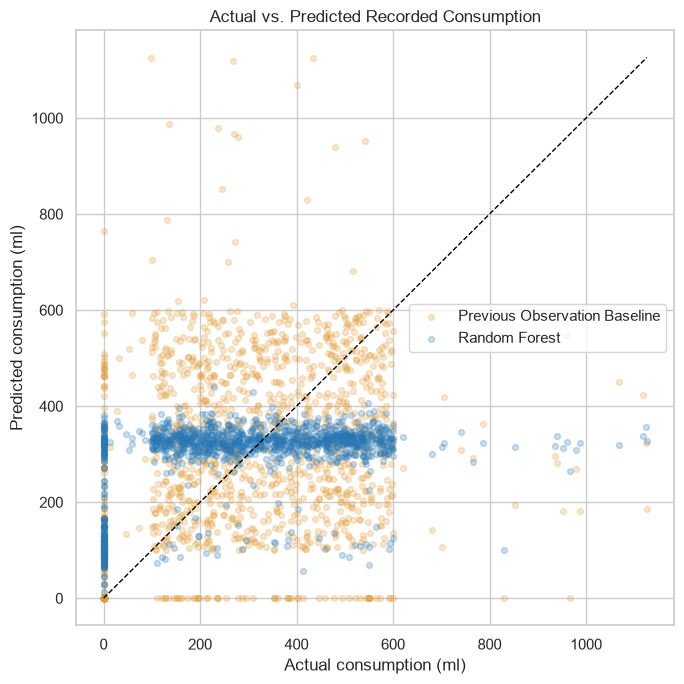

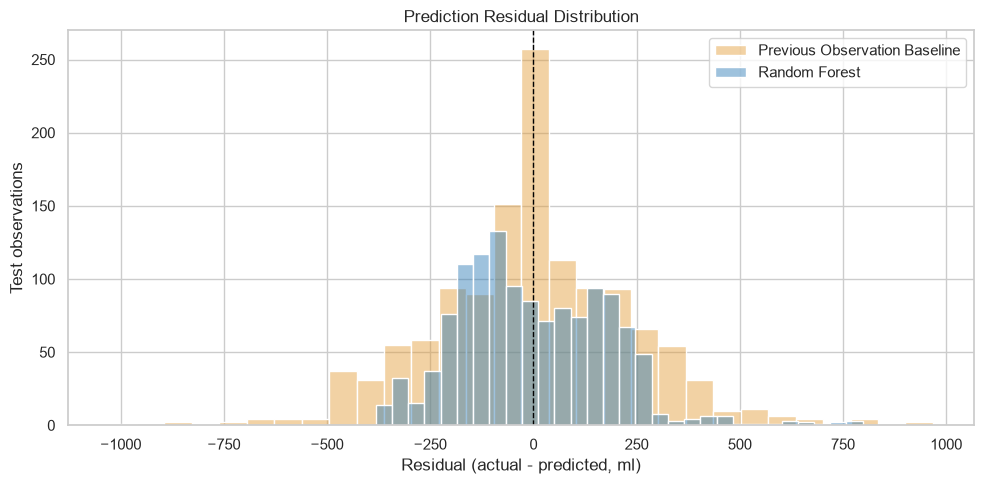

Mean absolute error by bar:


,Test_Records,Baseline_MAE_ml,Random_Forest_MAE_ml
Bar Name,,,
Taylor's Bar,211,182.315829,160.329546
Brown's Bar,219,200.947078,154.465859
Anderson's Bar,215,158.261209,147.046313
Smith's Bar,212,182.941698,146.496316
Thomas's Bar,211,163.495877,141.342232
Johnson's Bar,212,169.116745,137.612050


Mean absolute error by brand:


,Test_Records,Baseline_MAE_ml,Random_Forest_MAE_ml
Brand Name,,,
Miller,62,181.330484,165.211821
Coors,61,189.348689,161.045850
Jim Beam,97,191.582268,157.010733
Jameson,88,183.410341,152.416532
Bacardi,87,176.872299,150.941799
Jack Daniels,83,178.523494,150.036561
Grey Goose,98,192.924592,148.033923
Absolut,75,180.110400,147.359829
Captain Morgan,85,158.683882,146.075029


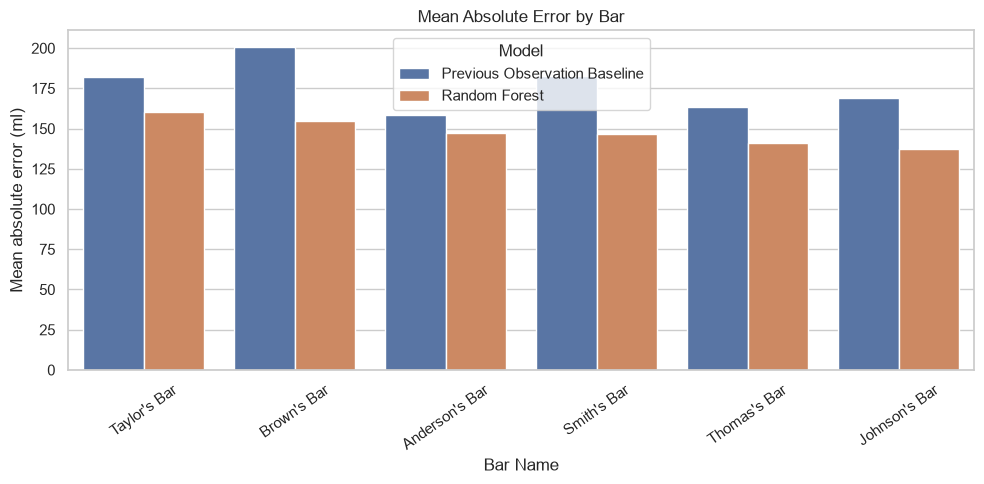

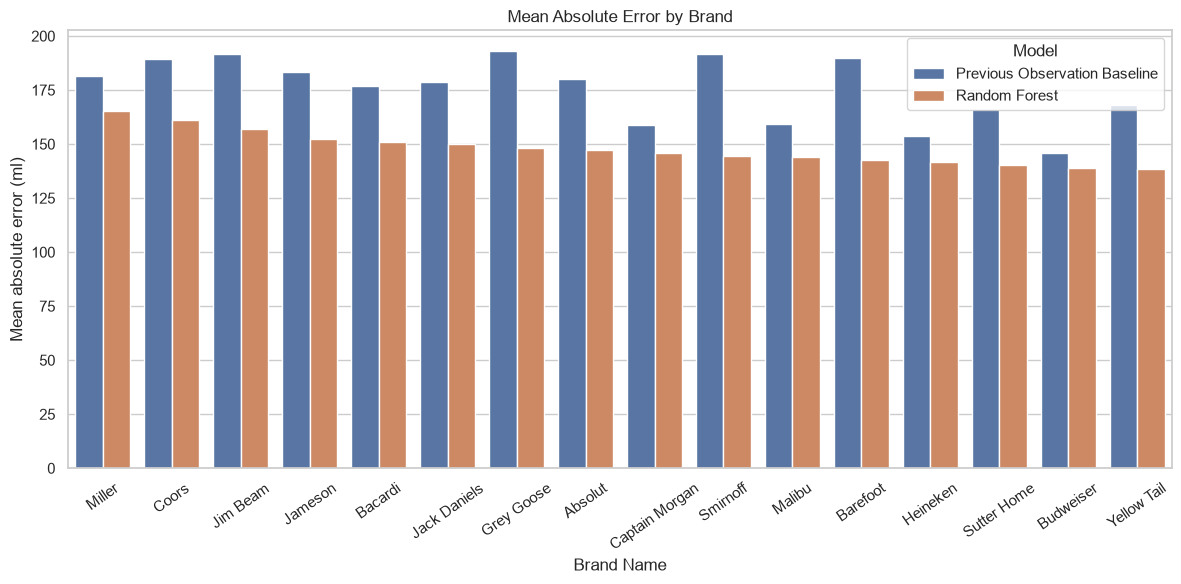

In [18]:
prediction_results = test_data[["Date", BAR_COLUMN, BRAND_COLUMN]].reset_index(drop=True).copy()
prediction_results["Actual_Consumption_ml"] = y_test.to_numpy(dtype=float)
prediction_results["Baseline_Prediction_ml"] = baseline_predictions
prediction_results["Random_Forest_Prediction_ml"] = random_forest_predictions
prediction_results["Baseline_Absolute_Error_ml"] = np.abs(
    prediction_results["Actual_Consumption_ml"]
    - prediction_results["Baseline_Prediction_ml"]
)
prediction_results["Random_Forest_Absolute_Error_ml"] = np.abs(
    prediction_results["Actual_Consumption_ml"]
    - prediction_results["Random_Forest_Prediction_ml"]
)

print(f"Prediction results shape: {prediction_results.shape[0]:,} rows x {prediction_results.shape[1]} columns")
display(prediction_results.head())

fig, ax = plt.subplots(figsize=(7, 7))
ax.scatter(
    prediction_results["Actual_Consumption_ml"],
    prediction_results["Baseline_Prediction_ml"],
    alpha=0.25,
    s=18,
    label="Previous Observation Baseline",
    color="#E39C37",
)
ax.scatter(
    prediction_results["Actual_Consumption_ml"],
    prediction_results["Random_Forest_Prediction_ml"],
    alpha=0.25,
    s=18,
    label="Random Forest",
    color="#2878B5",
)
plot_min = min(
    prediction_results["Actual_Consumption_ml"].min(),
    prediction_results["Baseline_Prediction_ml"].min(),
    prediction_results["Random_Forest_Prediction_ml"].min(),
)
plot_max = max(
    prediction_results["Actual_Consumption_ml"].max(),
    prediction_results["Baseline_Prediction_ml"].max(),
    prediction_results["Random_Forest_Prediction_ml"].max(),
)
ax.plot([plot_min, plot_max], [plot_min, plot_max], linestyle="--", color="black", linewidth=1)
ax.set(
    title="Actual vs. Predicted Recorded Consumption",
    xlabel="Actual consumption (ml)",
    ylabel="Predicted consumption (ml)",
)
ax.legend()
fig.tight_layout()
plt.show()

prediction_results["Baseline_Residual_ml"] = (
    prediction_results["Actual_Consumption_ml"]
    - prediction_results["Baseline_Prediction_ml"]
)
prediction_results["Random_Forest_Residual_ml"] = (
    prediction_results["Actual_Consumption_ml"]
    - prediction_results["Random_Forest_Prediction_ml"]
)
fig, ax = plt.subplots(figsize=(10, 5))
sns.histplot(
    prediction_results["Baseline_Residual_ml"],
    bins=30,
    color="#E39C37",
    alpha=0.45,
    label="Previous Observation Baseline",
    ax=ax,
)
sns.histplot(
    prediction_results["Random_Forest_Residual_ml"],
    bins=30,
    color="#2878B5",
    alpha=0.45,
    label="Random Forest",
    ax=ax,
)
ax.axvline(0, color="black", linestyle="--", linewidth=1)
ax.set(
    title="Prediction Residual Distribution",
    xlabel="Residual (actual - predicted, ml)",
    ylabel="Test observations",
)
ax.legend()
fig.tight_layout()
plt.show()


def summarize_absolute_error_by(group_column):
    return (
        prediction_results.groupby(group_column)
        .agg(
            Test_Records=("Date", "size"),
            Baseline_MAE_ml=("Baseline_Absolute_Error_ml", "mean"),
            Random_Forest_MAE_ml=("Random_Forest_Absolute_Error_ml", "mean"),
        )
        .sort_values("Random_Forest_MAE_ml", ascending=False)
    )


error_by_bar = summarize_absolute_error_by(BAR_COLUMN)
error_by_brand = summarize_absolute_error_by(BRAND_COLUMN)
print("Mean absolute error by bar:")
display(error_by_bar)
print("Mean absolute error by brand:")
display(error_by_brand)

for group_column, error_summary, title, figure_size in [
    (BAR_COLUMN, error_by_bar, "Mean Absolute Error by Bar", (10, 5)),
    (BRAND_COLUMN, error_by_brand, "Mean Absolute Error by Brand", (12, 6)),
]:
    error_plot_data = (
        error_summary[["Baseline_MAE_ml", "Random_Forest_MAE_ml"]]
        .rename(
            columns={
                "Baseline_MAE_ml": "Previous Observation Baseline",
                "Random_Forest_MAE_ml": "Random Forest",
            }
        )
        .reset_index()
        .melt(id_vars=group_column, var_name="Model", value_name="Mean absolute error (ml)")
    )
    fig, ax = plt.subplots(figsize=figure_size)
    sns.barplot(
        data=error_plot_data,
        x=group_column,
        y="Mean absolute error (ml)",
        hue="Model",
        ax=ax,
    )
    ax.set(title=title, xlabel=group_column, ylabel="Mean absolute error (ml)")
    ax.tick_params(axis="x", rotation=35)
    fig.tight_layout()
    plt.show()

### 5.6 Random Forest feature importance

The fitted forest exposes impurity-based feature importance after categorical fields are one-hot encoded. These scores indicate how the fitted trees used transformed features to reduce split impurity. They are descriptive model diagnostics, not evidence that a feature causes consumption.

Top 10 Random Forest features (impurity-based importance):


,Feature,Importance
0,remainder__Previous_Consumption_ml,0.455978
1,remainder__Previous_3_Records_Avg_ml,0.168303
2,remainder__Days_Since_Previous_Record,0.080560
3,remainder__Month,0.067391
4,remainder__DayOfWeek,0.049280
5,categorical__Bar Name_Johnson's Bar,0.011041
6,categorical__Bar Name_Taylor's Bar,0.010816
7,categorical__Bar Name_Thomas's Bar,0.010437
8,categorical__Bar Name_Brown's Bar,0.010212
9,categorical__Alcohol_Type_Beer,0.007929


Most influential feature in this fitted model: remainder__Previous_Consumption_ml (importance 0.456).


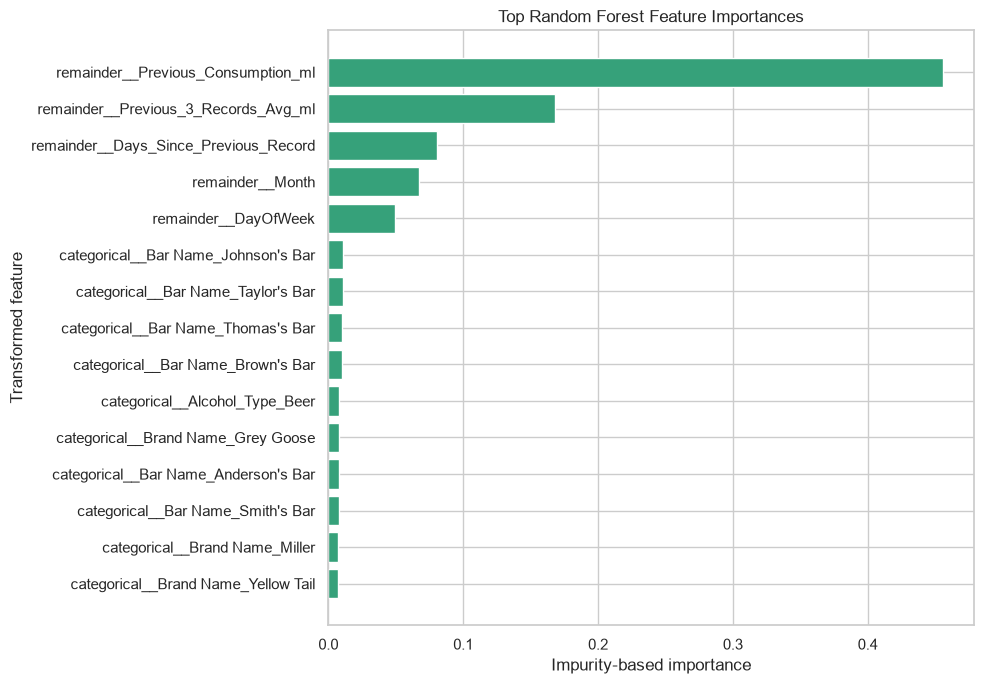

In [19]:
fitted_feature_names = random_forest_pipeline.named_steps[
    "preprocessor"
].get_feature_names_out()
fitted_importances = random_forest_pipeline.named_steps["model"].feature_importances_
if len(fitted_feature_names) != len(fitted_importances):
    raise ValueError("Feature names and Random Forest importances are not aligned.")

feature_importance = (
    pd.DataFrame(
        {
            "Feature": fitted_feature_names,
            "Importance": fitted_importances,
        }
    )
    .sort_values("Importance", ascending=False)
    .reset_index(drop=True)
)
top_feature_importance = feature_importance.head(15).sort_values("Importance")
print("Top 10 Random Forest features (impurity-based importance):")
display(feature_importance.head(10))
print(
    "Most influential feature in this fitted model: "
    f"{feature_importance.iloc[0]['Feature']} "
    f"(importance {feature_importance.iloc[0]['Importance']:.3f})."
)

fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(
    top_feature_importance["Feature"],
    top_feature_importance["Importance"],
    color="#36A17A",
)
ax.set(
    title="Top Random Forest Feature Importances",
    xlabel="Impurity-based importance",
    ylabel="Transformed feature",
)
fig.tight_layout()
plt.show()

### 5.7 Validation and limitations

The holdout contains the latest dates, and no training dates may overlap with test dates. Unseen test categories are supported by the fitted one-hot encoder's `handle_unknown="ignore"` setting. Prediction validity is checked for missing and infinite values.

Interpretation is limited: records are sparse and irregular (the Phase 4 mean gap was about five days), so the horizon between a prior observation and the next one is not fixed. This is not a forecast of every day, and the single chronological holdout is not proof of performance across seasons or future operating conditions. The baseline uses the last recorded consumption; both it and the Random Forest predict consumption at the next recorded observation. Feature importance does not establish causation. No inventory recommendations or simulations are made here.

In [20]:
prediction_columns = [
    "Actual_Consumption_ml",
    "Baseline_Prediction_ml",
    "Random_Forest_Prediction_ml",
]
prediction_values = prediction_results[prediction_columns].to_numpy(dtype=float)
if not np.isfinite(prediction_values).all():
    raise AssertionError("Actual or predicted values contain missing or infinite values.")

train_test_date_overlap = train_dates.intersection(test_dates)
if len(train_test_date_overlap):
    raise AssertionError(f"Train and test dates overlap: {train_test_date_overlap.tolist()}")
if target_column in X_train.columns or target_column in X_test.columns:
    raise AssertionError("Target leakage detected in a feature matrix.")
if X_test[categorical_features].isna().any().any():
    raise AssertionError("Test records contain missing categorical values.")

print("Validation passed: predictions and actual values are finite and non-missing.")
print(f"Train/test date overlap: {len(train_test_date_overlap)} dates")
print("Target included in feature matrix: False")
print("Test categories (unseen values are supported by OneHotEncoder):")
display(category_support)
print("Random Forest improvement over baseline by metric:")
for metric, improvement in metric_improvements.items():
    if np.isfinite(improvement):
        outcome = "improved" if improvement > 0 else "did not improve"
        print(f"- {metric}: {improvement:.2f}% ({outcome})")
    else:
        print(f"- {metric}: not meaningful (baseline metric is zero or WAPE is undefined)")
print("Final test-set comparison:")
display(comparison_results.round(3))

Validation passed: predictions and actual values are finite and non-missing.
Train/test date overlap: 0 dates
Target included in feature matrix: False
Test categories (unseen values are supported by OneHotEncoder):


,Feature,Training categories,Test categories not seen in training,Unseen test categories (handled by encoder)
0,Bar Name,6,0,[]
1,Brand Name,16,0,[]
2,Alcohol_Type,5,0,[]


Random Forest improvement over baseline by metric:
- MAE (ml): 16.09% (improved)
- RMSE (ml): 24.06% (improved)
- WAPE (%): 16.09% (improved)
Final test-set comparison:


,Previous Observation Baseline,Random Forest,Random Forest improvement over baseline (%)
Metric,,,
MAE (ml),176.278,147.911,16.092
RMSE (ml),238.279,180.944,24.062
WAPE (%),58.525,49.107,16.092


## Phase 6: Inventory Optimization and Recommended Par Levels

### Business objective and scope

This phase creates **provisional** stock, reorder, and safety-stock recommendations for each observed bar-brand combination. It reuses the Phase 4 `daily_demand` observations and coverage summary. These calculations are for assignment analysis only; they do not represent supplier-confirmed terms or hotel-approved operating policy. No replenishment simulation or executive dashboard is included.

### 6.1 Configurable illustrative assumptions

The lead time, review period, and service level below are illustrative and configurable?not supplier-confirmed or hotel-provided parameters. The Z-score is obtained from the standard normal distribution using `scipy.stats.norm.ppf`. These assumptions must be replaced with operationally verified values before using recommendations in practice.

In [21]:
LEAD_TIME_DAYS = 3
REVIEW_PERIOD_DAYS = 1
SERVICE_LEVEL = 0.95
SERVICE_LEVEL_Z_SCORE = stats.norm.ppf(SERVICE_LEVEL)

print("Illustrative inventory assumptions (not operationally confirmed):")
print(f"Lead time: {LEAD_TIME_DAYS} days")
print(f"Review period: {REVIEW_PERIOD_DAYS} days")
print(f"Target service level: {SERVICE_LEVEL:.0%}")
print(f"Standard normal Z-score: {SERVICE_LEVEL_Z_SCORE:.4f}")

Illustrative inventory assumptions (not operationally confirmed):
Lead time: 3 days
Review period: 1 days
Target service level: 95%
Standard normal Z-score: 1.6449


### 6.2 Observed demand statistics

Statistics are calculated from recorded rows in `daily_demand`, grouped by bar, brand, and alcohol type. Because observations are irregularly spaced, `Average_Observed_Consumption_ml` is an average **per recorded observation**, not a validated daily demand rate. For this assignment only, it is used as a provisional daily demand proxy in the illustrative formulas. `Demand_Std_Dev_ml` is the sample standard deviation across those observed values.

In [22]:
demand_group_columns = [BAR_COLUMN, BRAND_COLUMN, "Alcohol_Type"]
demand_statistics = (
    daily_demand.groupby(
        demand_group_columns, as_index=False, dropna=False
    )
    .agg(
        Total_Observed_Consumption_ml=(
            "Daily_Consumption_ml", lambda values: values.sum(min_count=1)
        ),
        Observation_Count=("Daily_Consumption_ml", "size"),
        Average_Observed_Consumption_ml=("Daily_Consumption_ml", "mean"),
        Demand_Std_Dev_ml=("Daily_Consumption_ml", "std"),
        Minimum_Observed_Consumption_ml=("Daily_Consumption_ml", "min"),
        Maximum_Observed_Consumption_ml=("Daily_Consumption_ml", "max"),
    )
)

coverage_for_recommendations = bar_brand_coverage[
    [BAR_COLUMN, BRAND_COLUMN, "Average_Gap_Days"]
].rename(columns={"Average_Gap_Days": "Average_Observation_Gap_Days"})
demand_statistics = demand_statistics.merge(
    coverage_for_recommendations,
    on=[BAR_COLUMN, BRAND_COLUMN],
    how="left",
    validate="many_to_one",
)
demand_statistics = demand_statistics.sort_values(
    [BAR_COLUMN, BRAND_COLUMN]
).reset_index(drop=True)

print(f"Demand-statistics rows: {len(demand_statistics):,}")
display(demand_statistics.head(10))
print("Observed consumption statistics:")
display(
    demand_statistics[
        [
            "Observation_Count",
            "Average_Observed_Consumption_ml",
            "Demand_Std_Dev_ml",
            "Average_Observation_Gap_Days",
        ]
    ].describe().T
)

Demand-statistics rows: 96


,Bar Name,Brand Name,Alcohol_Type,Total_Observed_Consumption_ml,Observation_Count,Average_Observed_Consumption_ml,Demand_Std_Dev_ml,Minimum_Observed_Consumption_ml,Maximum_Observed_Consumption_ml,Average_Observation_Gap_Days
0,Anderson's Bar,Absolut,Vodka,13113.91,69,190.056667,174.358025,0.0,579.09,5.250000
1,Anderson's Bar,Bacardi,Rum,25966.47,74,350.898243,166.088852,0.0,635.05,4.986301
2,Anderson's Bar,Barefoot,Wine,26989.63,80,337.370375,165.999735,0.0,899.69,4.569620
3,Anderson's Bar,Budweiser,Beer,10062.29,48,209.631042,194.491026,0.0,574.10,7.468085
4,Anderson's Bar,Captain Morgan,Rum,27066.83,73,370.778493,195.960809,0.0,1097.26,4.722222
5,Anderson's Bar,Coors,Beer,21479.29,60,357.988167,147.280158,0.0,599.53,6.169492
6,Anderson's Bar,Grey Goose,Vodka,24026.36,68,353.328824,155.422352,0.0,810.42,5.298507
7,Anderson's Bar,Heineken,Beer,17413.71,60,290.228500,205.091797,0.0,598.30,6.016949
8,Anderson's Bar,Jack Daniels,Whiskey,21454.32,81,264.868148,196.679759,0.0,987.04,4.475000
9,Anderson's Bar,Jameson,Whiskey,23117.10,73,316.672603,186.467266,0.0,845.49,4.972222


Observed consumption statistics:


,count,mean,std,min,25%,50%,75%,max
Observation_Count,96.0,68.489583,11.148750,40.000000,60.000000,69.500000,76.000000,99.000000
Average_Observed_Consumption_ml,96.0,300.238329,46.711532,190.056667,266.937447,312.361567,335.253419,386.353333
Demand_Std_Dev_ml,96.0,186.859760,19.577989,147.280158,171.900316,186.443597,199.283520,258.121280
Average_Observation_Gap_Days,96.0,5.436082,0.987611,3.653061,4.784079,5.151616,6.038355,8.538462


### 6.3 Provisional safety stock, reorder point, and par level

The calculations use the assignment's illustrative equations:

- **Safety stock** = Z-score ? observed demand standard deviation ? ?lead time
- **Reorder point** = (observed average proxy ? lead time) + safety stock
- **Recommended par** = (observed average proxy ? (lead time + review period)) + safety stock

Each calculated quantity is rounded **up** to the next whole millilitre and constrained to be non-negative. The unrounded safety-stock calculation is used in the reorder and par equations before their own upward rounding. The equations assume the observed standard deviation is a useful representation of demand variability; that assumption is not validated by these irregularly spaced records.

In [23]:
inventory_recommendations = demand_statistics.copy()

inventory_recommendations["Recommendation_Confidence"] = np.select(
    [
        inventory_recommendations["Observation_Count"].lt(10),
        inventory_recommendations["Observation_Count"].lt(30),
    ],
    ["Low", "Moderate"],
    default="Higher",
)
inventory_recommendations["Limited_Observations_Flag"] = (
    inventory_recommendations["Observation_Count"].lt(30)
)

raw_safety_stock = (
    SERVICE_LEVEL_Z_SCORE
    * inventory_recommendations["Demand_Std_Dev_ml"]
    * np.sqrt(LEAD_TIME_DAYS)
)
raw_reorder_point = (
    inventory_recommendations["Average_Observed_Consumption_ml"]
    * LEAD_TIME_DAYS
    + raw_safety_stock
)
raw_recommended_par = (
    inventory_recommendations["Average_Observed_Consumption_ml"]
    * (LEAD_TIME_DAYS + REVIEW_PERIOD_DAYS)
    + raw_safety_stock
)

inventory_recommendations["Safety_Stock_ml"] = np.ceil(
    raw_safety_stock.clip(lower=0)
).astype("int64")
inventory_recommendations["Reorder_Point_ml"] = np.ceil(
    raw_reorder_point.clip(lower=0)
).astype("int64")
inventory_recommendations["Recommended_Par_Level_ml"] = np.ceil(
    raw_recommended_par.clip(lower=0)
).astype("int64")
inventory_recommendations = inventory_recommendations.sort_values(
    [BAR_COLUMN, BRAND_COLUMN]
).reset_index(drop=True)

print(f"Provisional recommendations created: {len(inventory_recommendations):,}")
display(inventory_recommendations.head(10))
print("Recommendation confidence counts (coverage labels, not model confidence):")
display(inventory_recommendations["Recommendation_Confidence"].value_counts().to_frame("Combinations"))
print(
    "Combinations flagged for limited observations (<30): "
    f"{inventory_recommendations['Limited_Observations_Flag'].sum():,}"
)

Provisional recommendations created: 96


,Bar Name,Brand Name,Alcohol_Type,Total_Observed_Consumption_ml,Observation_Count,Average_Observed_Consumption_ml,Demand_Std_Dev_ml,Minimum_Observed_Consumption_ml,Maximum_Observed_Consumption_ml,Average_Observation_Gap_Days,Recommendation_Confidence,Limited_Observations_Flag,Safety_Stock_ml,Reorder_Point_ml,Recommended_Par_Level_ml
0,Anderson's Bar,Absolut,Vodka,13113.91,69,190.056667,174.358025,0.0,579.09,5.250000,Higher,False,497,1067,1257
1,Anderson's Bar,Bacardi,Rum,25966.47,74,350.898243,166.088852,0.0,635.05,4.986301,Higher,False,474,1526,1877
2,Anderson's Bar,Barefoot,Wine,26989.63,80,337.370375,165.999735,0.0,899.69,4.569620,Higher,False,473,1486,1823
3,Anderson's Bar,Budweiser,Beer,10062.29,48,209.631042,194.491026,0.0,574.10,7.468085,Higher,False,555,1183,1393
4,Anderson's Bar,Captain Morgan,Rum,27066.83,73,370.778493,195.960809,0.0,1097.26,4.722222,Higher,False,559,1671,2042
5,Anderson's Bar,Coors,Beer,21479.29,60,357.988167,147.280158,0.0,599.53,6.169492,Higher,False,420,1494,1852
6,Anderson's Bar,Grey Goose,Vodka,24026.36,68,353.328824,155.422352,0.0,810.42,5.298507,Higher,False,443,1503,1857
7,Anderson's Bar,Heineken,Beer,17413.71,60,290.228500,205.091797,0.0,598.30,6.016949,Higher,False,585,1455,1746
8,Anderson's Bar,Jack Daniels,Whiskey,21454.32,81,264.868148,196.679759,0.0,987.04,4.475000,Higher,False,561,1355,1620
9,Anderson's Bar,Jameson,Whiskey,23117.10,73,316.672603,186.467266,0.0,845.49,4.972222,Higher,False,532,1482,1798


Recommendation confidence counts (coverage labels, not model confidence):


,Combinations
Recommendation_Confidence,
Higher,96


Combinations flagged for limited observations (<30): 0


### 6.4 Recommendation quality checks

`Recommendation_Confidence` is a transparent **data-coverage label only**: Low means fewer than 10 observations, Moderate means 10?29, and Higher means 30 or more. It is not statistical confidence, a probability of meeting service level, or a measure of forecast accuracy. `Limited_Observations_Flag` identifies combinations with fewer than 30 records.

In [24]:
required_recommendation_columns = [
    *demand_group_columns,
    "Total_Observed_Consumption_ml",
    "Observation_Count",
    "Average_Observed_Consumption_ml",
    "Demand_Std_Dev_ml",
    "Minimum_Observed_Consumption_ml",
    "Maximum_Observed_Consumption_ml",
    "Average_Observation_Gap_Days",
    "Recommendation_Confidence",
    "Limited_Observations_Flag",
    "Safety_Stock_ml",
    "Reorder_Point_ml",
    "Recommended_Par_Level_ml",
]
missing_recommendation_values = inventory_recommendations[
    required_recommendation_columns
].isna().sum()
recommendation_duplicates = inventory_recommendations.duplicated(
    subset=[BAR_COLUMN, BRAND_COLUMN]
).sum()
recommendation_quantity_columns = [
    "Safety_Stock_ml",
    "Reorder_Point_ml",
    "Recommended_Par_Level_ml",
]
negative_recommendation_counts = inventory_recommendations[
    recommendation_quantity_columns
].lt(0).sum()

print(
    "Distinct bar-brand combinations: "
    f"{inventory_recommendations[[BAR_COLUMN, BRAND_COLUMN]].drop_duplicates().shape[0]:,}"
)
print(f"Duplicate bar-brand combinations: {recommendation_duplicates:,}")
print("Missing required recommendation values:")
display(missing_recommendation_values.rename("Missing values").to_frame())
print("Negative recommendation counts:")
display(negative_recommendation_counts.rename("Negative values").to_frame())

if len(inventory_recommendations) != 96:
    raise AssertionError(
        f"Expected 96 bar-brand combinations, found {len(inventory_recommendations)}."
    )
if recommendation_duplicates:
    raise AssertionError("Duplicate bar-brand recommendations were found.")
if missing_recommendation_values.any():
    raise AssertionError("Required recommendation fields contain missing values.")
if negative_recommendation_counts.any():
    raise AssertionError("A recommendation quantity is negative.")

print("Validation passed: one non-negative, complete recommendation per bar-brand combination.")

Distinct bar-brand combinations: 96
Duplicate bar-brand combinations: 0
Missing required recommendation values:


,Missing values
Bar Name,0
Brand Name,0
Alcohol_Type,0
Total_Observed_Consumption_ml,0
Observation_Count,0
Average_Observed_Consumption_ml,0
Demand_Std_Dev_ml,0
Minimum_Observed_Consumption_ml,0
Maximum_Observed_Consumption_ml,0
Average_Observation_Gap_Days,0


Negative recommendation counts:


,Negative values
Safety_Stock_ml,0
Reorder_Point_ml,0
Recommended_Par_Level_ml,0


Validation passed: one non-negative, complete recommendation per bar-brand combination.


### 6.5 Inventory recommendation visualizations

These charts summarize the provisional par and safety-stock quantities in ml. A bar's par total sums the per-brand recommendations for that bar. The average-consumption comparison shows an average per recorded observation beside an inventory quantity; the units are both ml, but the average is only a provisional daily proxy because observation intervals are irregular.

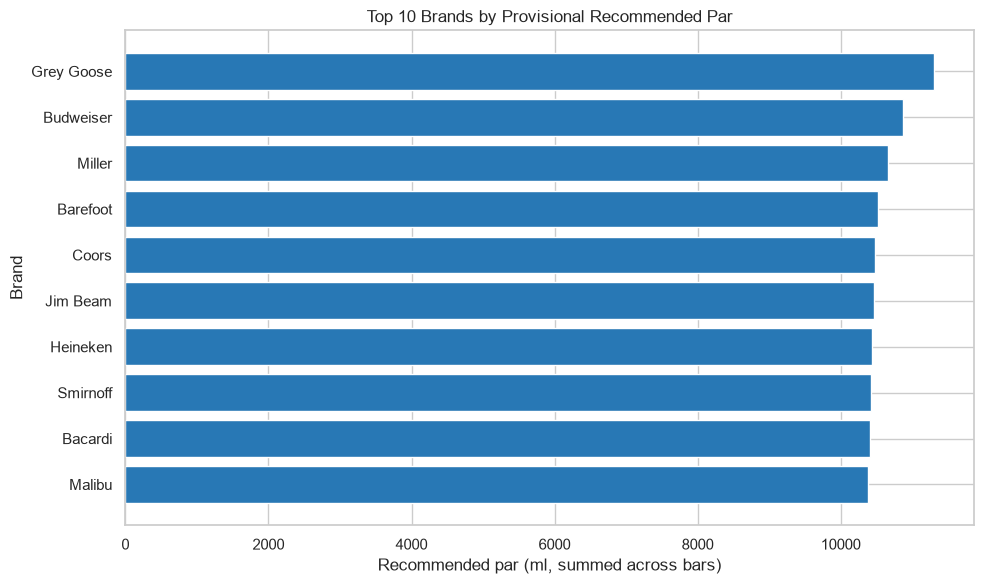

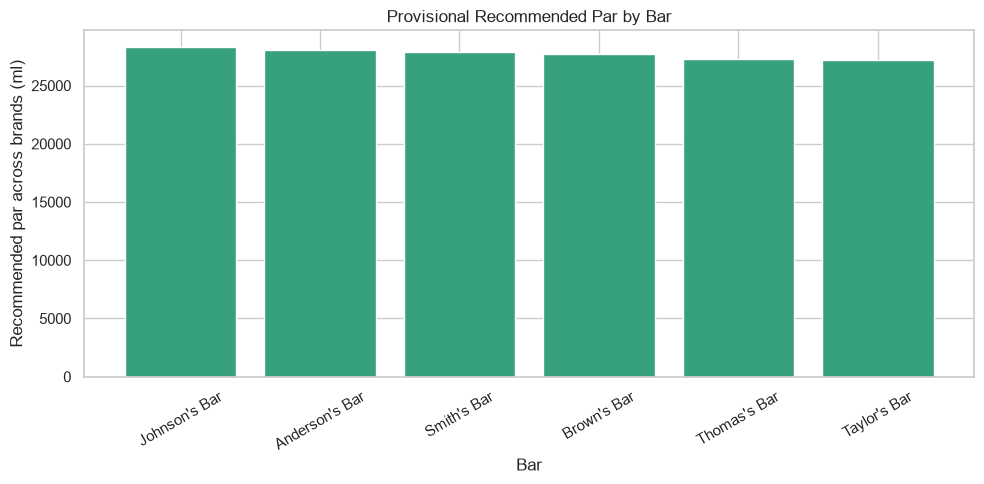

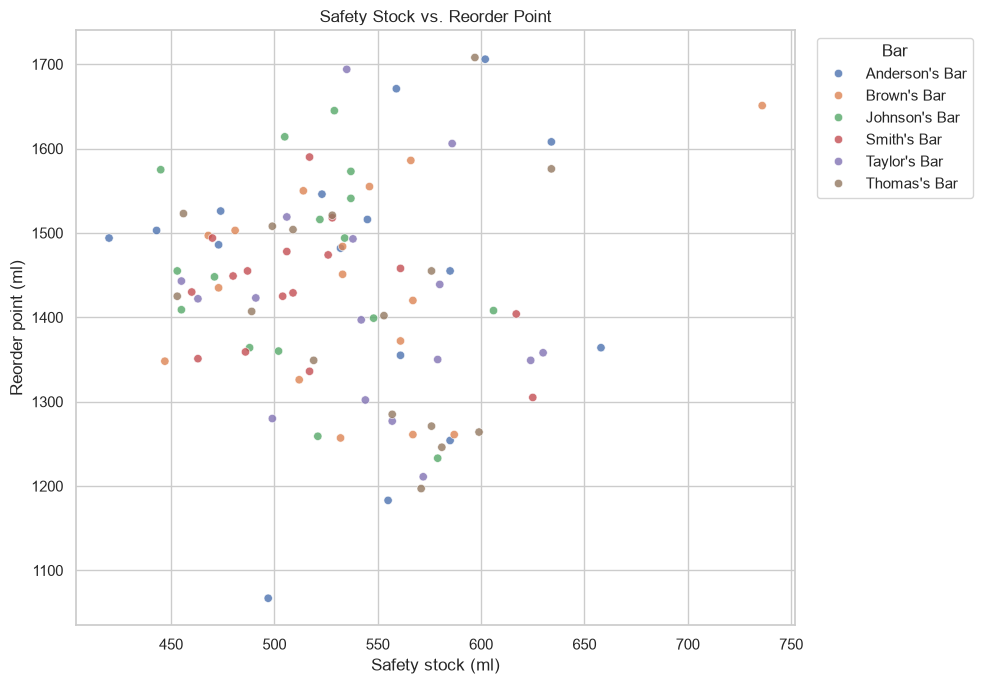

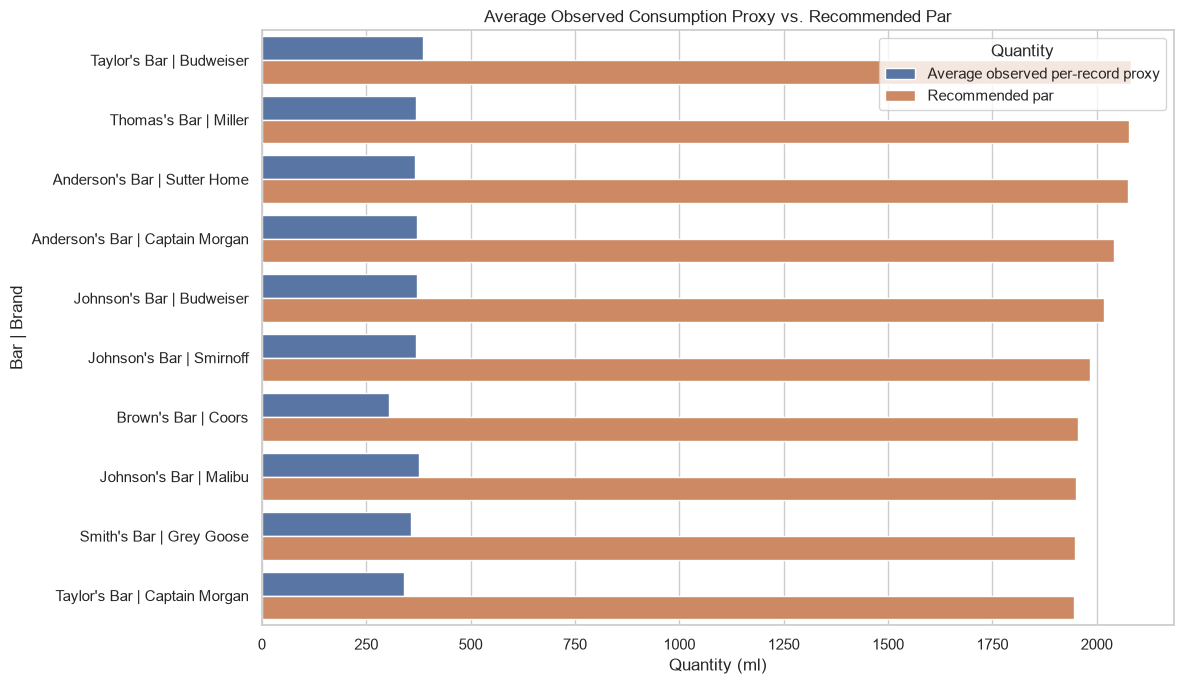

In [25]:
sns.set_theme(style="whitegrid", context="notebook")

par_by_brand = (
    inventory_recommendations.groupby(BRAND_COLUMN)["Recommended_Par_Level_ml"]
    .sum()
    .sort_values(ascending=False)
)
top_10_par_by_brand = par_by_brand.head(10).sort_values(ascending=True)
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(top_10_par_by_brand.index.astype(str), top_10_par_by_brand.values, color="#2878B5")
ax.set(
    title="Top 10 Brands by Provisional Recommended Par",
    xlabel="Recommended par (ml, summed across bars)",
    ylabel="Brand",
)
fig.tight_layout()
plt.show()

par_by_bar = (
    inventory_recommendations.groupby(BAR_COLUMN)["Recommended_Par_Level_ml"]
    .sum()
    .sort_values(ascending=False)
)
fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(par_by_bar.index.astype(str), par_by_bar.values, color="#36A17A")
ax.set(
    title="Provisional Recommended Par by Bar",
    xlabel="Bar",
    ylabel="Recommended par across brands (ml)",
)
ax.tick_params(axis="x", rotation=30)
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(10, 7))
sns.scatterplot(
    data=inventory_recommendations,
    x="Safety_Stock_ml",
    y="Reorder_Point_ml",
    hue=BAR_COLUMN,
    alpha=0.8,
    ax=ax,
)
ax.set(
    title="Safety Stock vs. Reorder Point",
    xlabel="Safety stock (ml)",
    ylabel="Reorder point (ml)",
)
ax.legend(title="Bar", bbox_to_anchor=(1.02, 1), loc="upper left")
fig.tight_layout()
plt.show()

comparison_recommendations = inventory_recommendations.nlargest(
    10, "Recommended_Par_Level_ml"
).copy()
comparison_recommendations["Bar_Brand"] = (
    comparison_recommendations[BAR_COLUMN].astype(str)
    + " | "
    + comparison_recommendations[BRAND_COLUMN].astype(str)
)
comparison_plot_data = comparison_recommendations[
    ["Bar_Brand", "Average_Observed_Consumption_ml", "Recommended_Par_Level_ml"]
].melt(
    id_vars="Bar_Brand",
    var_name="Quantity",
    value_name="Quantity_ml",
)
comparison_plot_data["Quantity"] = comparison_plot_data["Quantity"].replace(
    {
        "Average_Observed_Consumption_ml": "Average observed per-record proxy",
        "Recommended_Par_Level_ml": "Recommended par",
    }
)
fig, ax = plt.subplots(figsize=(12, 7))
sns.barplot(
    data=comparison_plot_data,
    x="Quantity_ml",
    y="Bar_Brand",
    hue="Quantity",
    ax=ax,
)
ax.set(
    title="Average Observed Consumption Proxy vs. Recommended Par",
    xlabel="Quantity (ml)",
    ylabel="Bar | Brand",
)
fig.tight_layout()
plt.show()

### 6.6 Interactive inventory recommendation sheet

When `ipywidgets` is available, choose a bar to inspect its brands, alcohol types, observed consumption average, safety stock, reorder point, recommended par, observation count, and coverage label. The selector only filters the already calculated recommendations; it does not change assumptions or recalculate demand.

In [26]:
import importlib.util

recommendation_display_columns = [
    BRAND_COLUMN,
    "Alcohol_Type",
    "Average_Observed_Consumption_ml",
    "Safety_Stock_ml",
    "Reorder_Point_ml",
    "Recommended_Par_Level_ml",
    "Observation_Count",
    "Recommendation_Confidence",
]
if importlib.util.find_spec("ipywidgets") is not None:
    import ipywidgets as widgets
    from IPython.display import clear_output

    available_bars = sorted(inventory_recommendations[BAR_COLUMN].dropna().unique())
    bar_selector = widgets.Dropdown(
        options=available_bars,
        value=available_bars[0] if available_bars else None,
        description="Bar:",
        layout=widgets.Layout(width="350px"),
    )
    recommendation_output = widgets.Output()

    def update_recommendation_sheet(change=None):
        with recommendation_output:
            clear_output(wait=True)
            if bar_selector.value is None:
                print("No bar recommendations are available.")
            else:
                selected_recommendations = inventory_recommendations.loc[
                    inventory_recommendations[BAR_COLUMN].eq(bar_selector.value),
                    recommendation_display_columns,
                ].sort_values("Recommended_Par_Level_ml", ascending=False)
                display(selected_recommendations.reset_index(drop=True))

    bar_selector.observe(update_recommendation_sheet, names="value")
    update_recommendation_sheet()
    display(widgets.VBox([bar_selector, recommendation_output]))
else:
    print("ipywidgets is unavailable; showing the complete recommendation table instead.")
    display(
        inventory_recommendations[
            [BAR_COLUMN, *recommendation_display_columns]
        ].sort_values([BAR_COLUMN, "Recommended_Par_Level_ml"], ascending=[True, False])
    )

### 6.7 Manual formula validation and business limitations

The manual check below recomputes demand statistics and recommendation quantities for one combination directly from its recorded daily observations, then compares them with the recommendation table. The recommendations remain provisional: the dataset has irregularly spaced observations, no supplier lead times or actual service-level requirements were supplied, and recorded averages are used as daily demand proxies. The standard safety-stock formula assumes observed variability represents demand variability. Recalibrate with actual daily POS demand, confirmed supplier lead times, and operational requirements before real-world use.

In [27]:
manual_recommendation = inventory_recommendations.sort_values(
    "Observation_Count", ascending=False
).iloc[0]
manual_observations = daily_demand.loc[
    daily_demand[BAR_COLUMN].eq(manual_recommendation[BAR_COLUMN])
    & daily_demand[BRAND_COLUMN].eq(manual_recommendation[BRAND_COLUMN])
    & daily_demand["Alcohol_Type"].eq(manual_recommendation["Alcohol_Type"]),
    "Daily_Consumption_ml",
]
manual_average = manual_observations.mean()
manual_std_dev = manual_observations.std(ddof=1)
manual_raw_safety_stock = (
    SERVICE_LEVEL_Z_SCORE * manual_std_dev * np.sqrt(LEAD_TIME_DAYS)
)
manual_expected_safety_stock = int(np.ceil(max(manual_raw_safety_stock, 0)))
manual_expected_reorder_point = int(
    np.ceil(max(manual_average * LEAD_TIME_DAYS + manual_raw_safety_stock, 0))
)
manual_expected_par_level = int(
    np.ceil(
        max(
            manual_average * (LEAD_TIME_DAYS + REVIEW_PERIOD_DAYS)
            + manual_raw_safety_stock,
            0,
        )
    )
)

assert len(manual_observations) == manual_recommendation["Observation_Count"]
assert np.isclose(manual_average, manual_recommendation["Average_Observed_Consumption_ml"])
assert np.isclose(manual_std_dev, manual_recommendation["Demand_Std_Dev_ml"])
assert manual_expected_safety_stock == manual_recommendation["Safety_Stock_ml"]
assert manual_expected_reorder_point == manual_recommendation["Reorder_Point_ml"]
assert manual_expected_par_level == manual_recommendation["Recommended_Par_Level_ml"]

print(
    "Manual formula check: "
    f"{manual_recommendation[BAR_COLUMN]} / {manual_recommendation[BRAND_COLUMN]} / "
    f"{manual_recommendation['Alcohol_Type']}"
)
print(f"Observed records: {len(manual_observations)}")
print(f"Observed mean: {manual_average:.2f} ml; sample standard deviation: {manual_std_dev:.2f} ml")
print(
    "Recomputed rounded quantities: "
    f"safety stock={manual_expected_safety_stock:,} ml, "
    f"reorder point={manual_expected_reorder_point:,} ml, "
    f"recommended par={manual_expected_par_level:,} ml"
)
print("Manual formula validation passed.")

print("Sample provisional recommended par levels:")
display(
    inventory_recommendations[
        [
            BAR_COLUMN,
            BRAND_COLUMN,
            "Alcohol_Type",
            "Observation_Count",
            "Average_Observed_Consumption_ml",
            "Safety_Stock_ml",
            "Reorder_Point_ml",
            "Recommended_Par_Level_ml",
            "Recommendation_Confidence",
        ]
    ]
    .sort_values("Recommended_Par_Level_ml", ascending=False)
    .head(10)
    .reset_index(drop=True)
)

Manual formula check: Johnson's Bar / Captain Morgan / Rum
Observed records: 99
Observed mean: 286.06 ml; sample standard deviation: 176.07 ml
Recomputed rounded quantities: safety stock=502 ml, reorder point=1,360 ml, recommended par=1,646 ml
Manual formula validation passed.
Sample provisional recommended par levels:


,Bar Name,Brand Name,Alcohol_Type,Observation_Count,Average_Observed_Consumption_ml,Safety_Stock_ml,Reorder_Point_ml,Recommended_Par_Level_ml,Recommendation_Confidence
0,Taylor's Bar,Budweiser,Beer,57,386.353333,535,1694,2081,Higher
1,Thomas's Bar,Miller,Beer,59,370.208475,597,1708,2078,Higher
2,Anderson's Bar,Sutter Home,Wine,62,367.995806,602,1706,2074,Higher
3,Anderson's Bar,Captain Morgan,Rum,73,370.778493,559,1671,2042,Higher
4,Johnson's Bar,Budweiser,Beer,52,372.022500,529,1645,2017,Higher
5,Johnson's Bar,Smirnoff,Vodka,69,369.652464,505,1614,1984,Higher
6,Brown's Bar,Coors,Beer,46,304.978478,736,1651,1956,Higher
7,Johnson's Bar,Malibu,Rum,70,376.521571,445,1575,1951,Higher
8,Smith's Bar,Grey Goose,Vodka,70,357.736571,517,1590,1948,Higher
9,Taylor's Bar,Captain Morgan,Rum,67,339.800149,586,1606,1946,Higher


## Phase 7: Inventory Replenishment Simulation

### Simulation objective

This hypothetical scenario compares no replenishment with a reorder-up-to-par policy for all bar-brand combinations over a configurable 30-day horizon. It samples historical `Daily_Consumption_ml` values from Phase 4's `daily_demand` as an **observed-consumption daily proxy**. Because source observations are irregularly spaced, this is **not** a reconstruction or backtest of actual historical daily demand. The Phase 6 recommendation table and its reorder-point and par values are reused; the forecasting model is not retrained.

### 7.1 Configurable assumptions and sampling method

The simulation uses the requested seed, horizon, three-day lead time, and 95% service-level assumption. These match the illustrative Phase 6 inputs; the existing recommendation values are not recalculated here. If lead time or service level is changed, rerun Phase 6 so its reorder points and par values stay aligned with the simulation settings.

For each combination, 30 values are sampled **with replacement** from all its recorded daily-consumption observations. Explicit zero-consumption observations remain eligible samples; absent historical dates are never inserted as zeros. One seeded demand path is shared by both policies for a fair comparison. This sampling assumes observed per-record consumption is a plausible daily proxy and does not preserve calendar spacing, seasonality, or serial dependence. No supplier, cost, or operating assumptions are added.

In [28]:
SIMULATION_DAYS = 30
SIMULATION_SEED = 42
LEAD_TIME_DAYS = 3
SERVICE_LEVEL = 0.95

if SIMULATION_DAYS <= 0 or LEAD_TIME_DAYS <= 0:
    raise ValueError("Simulation horizon and lead time must be positive.")
if not 0 < SERVICE_LEVEL < 1:
    raise ValueError("SERVICE_LEVEL must be between 0 and 1.")

SIMULATION_POLICIES = ["No Replenishment", "Reorder-Up-To-Par"]
SIMULATION_COMBINATION_COLUMNS = [BAR_COLUMN, BRAND_COLUMN, "Alcohol_Type"]
print("Simulation assumptions:")
print(f"Simulation days: {SIMULATION_DAYS}")
print(f"Random seed: {SIMULATION_SEED}")
print(f"Lead time: {LEAD_TIME_DAYS} days")
print(f"Service level assumption: {SERVICE_LEVEL:.0%}")
print("Existing Phase 6 reorder points and par levels will be reused.")

Simulation assumptions:
Simulation days: 30
Random seed: 42
Lead time: 3 days
Service level assumption: 95%
Existing Phase 6 reorder points and par levels will be reused.


### 7.2 Generate empirical demand scenarios

A single seeded random generator walks combinations in a consistent sorted order. For each combination it samples only available recorded consumption values, with replacement. These scenario days are synthetic labels (day 1 through day 30), not dates claimed to have occurred. Missing observations are not imputed.

In [29]:
def generate_empirical_demand_scenarios(daily_observations, simulation_days, seed):
    random_generator = np.random.default_rng(seed)
    demand_scenarios = {}
    scenario_rows = []

    for combination, group in daily_observations.groupby(
        SIMULATION_COMBINATION_COLUMNS, sort=True, dropna=False
    ):
        observed_values = group["Daily_Consumption_ml"].dropna().to_numpy(dtype=float)
        if observed_values.size == 0:
            raise ValueError(f"No recorded consumption values for combination {combination}.")
        if not np.isfinite(observed_values).all() or (observed_values < 0).any():
            raise ValueError(f"Invalid historical consumption values for combination {combination}.")

        simulated_values = random_generator.choice(
            observed_values, size=simulation_days, replace=True
        )
        demand_scenarios[combination] = simulated_values
        for simulation_day, demand in enumerate(simulated_values, start=1):
            scenario_rows.append(
                {
                    **dict(zip(SIMULATION_COMBINATION_COLUMNS, combination)),
                    "Simulation_Day": simulation_day,
                    "Daily_Demand_ml": float(demand),
                }
            )

    return demand_scenarios, pd.DataFrame(scenario_rows)


simulation_demand_paths, simulation_demand_scenarios = generate_empirical_demand_scenarios(
    daily_demand, SIMULATION_DAYS, SIMULATION_SEED
)
repeated_demand_paths, _ = generate_empirical_demand_scenarios(
    daily_demand, SIMULATION_DAYS, SIMULATION_SEED
)
if set(simulation_demand_paths) != set(repeated_demand_paths):
    raise AssertionError("Repeated scenario generation returned different combinations.")
if not all(
    np.array_equal(simulation_demand_paths[key], repeated_demand_paths[key])
    for key in simulation_demand_paths
):
    raise AssertionError("Demand scenarios are not reproducible with the fixed seed.")

historical_zero_observations = int(daily_demand["Daily_Consumption_ml"].eq(0).sum())
print(f"Empirical demand paths generated: {len(simulation_demand_paths):,}")
print(f"Scenario demand values: {len(simulation_demand_scenarios):,}")
print(f"Explicit zero observations retained in historical sampling pools: {historical_zero_observations:,}")
print("Demand scenarios are reproducible with the configured seed.")
display(simulation_demand_scenarios.head())

Empirical demand paths generated: 96
Scenario demand values: 2,880
Explicit zero observations retained in historical sampling pools: 910
Demand scenarios are reproducible with the configured seed.


,Bar Name,Brand Name,Alcohol_Type,Simulation_Day,Daily_Demand_ml
0,Anderson's Bar,Absolut,Vodka,1,0.00
1,Anderson's Bar,Absolut,Vodka,2,189.66
2,Anderson's Bar,Absolut,Vodka,3,0.00
3,Anderson's Bar,Absolut,Vodka,4,0.00
4,Anderson's Bar,Absolut,Vodka,5,0.00


### 7.3 Policy sequence and inventory accounting

Both policies begin each combination at its Phase 6 recommended par. For the reorder policy, each day runs in this order:

1. Receive any order scheduled for the start of the current simulation day.
2. Apply that day's sampled demand; fulfill up to on-hand stock, record any remainder as lost demand, and keep physical stock non-negative.
3. Calculate inventory position as end-of-day on-hand plus all outstanding orders.
4. If inventory position is at or below the Phase 6 reorder point **and no order is already outstanding**, order enough to raise inventory position to par.

An order placed after day *t* with a three-day lead time is scheduled to arrive at the start of day *t + 3*, before that day's demand. An order due after day 30 remains outstanding and is not received in the simulation. No second order is placed while one is in the pipeline. `Average_Inventory_ml` is the mean of daily end-of-day on-hand inventory; a stockout day is a day with positive lost demand.

In [30]:
def simulate_inventory_policy(recommendation, demand_path, policy):
    combination = tuple(
        recommendation[column] for column in SIMULATION_COMBINATION_COLUMNS
    )
    initial_inventory = float(recommendation["Recommended_Par_Level_ml"])
    reorder_point = float(recommendation["Reorder_Point_ml"])
    par_level = float(recommendation["Recommended_Par_Level_ml"])
    if par_level < reorder_point:
        raise ValueError(f"Recommended par is below reorder point for {combination}.")

    on_hand_inventory = initial_inventory
    order_pipeline = []
    total_orders_placed = 0
    total_order_quantity = 0.0
    daily_rows = []

    for simulation_day, daily_demand_ml in enumerate(demand_path, start=1):
        inventory_before_receipts = on_hand_inventory
        due_orders = [
            order for order in order_pipeline
            if order["arrival_day"] == simulation_day
        ]
        if any(order["arrival_day"] < simulation_day for order in order_pipeline):
            raise AssertionError("An order passed its scheduled arrival day without receipt.")
        orders_received = float(sum(order["quantity_ml"] for order in due_orders))
        order_pipeline = [
            order for order in order_pipeline
            if order["arrival_day"] > simulation_day
        ]
        on_hand_inventory += orders_received
        available_before_demand = on_hand_inventory

        daily_demand_ml = float(daily_demand_ml)
        fulfilled_demand = min(available_before_demand, daily_demand_ml)
        lost_demand = daily_demand_ml - fulfilled_demand
        on_hand_inventory = max(available_before_demand - fulfilled_demand, 0.0)
        stockout = lost_demand > 0

        inventory_position_before_order = on_hand_inventory + sum(
            order["quantity_ml"] for order in order_pipeline
        )
        order_placed = 0.0
        scheduled_arrival_day = None
        if (
            policy == "Reorder-Up-To-Par"
            and not order_pipeline
            and inventory_position_before_order <= reorder_point
        ):
            order_placed = max(par_level - inventory_position_before_order, 0.0)
            if order_placed > 0:
                scheduled_arrival_day = simulation_day + LEAD_TIME_DAYS
                order_pipeline.append(
                    {
                        "arrival_day": scheduled_arrival_day,
                        "quantity_ml": order_placed,
                    }
                )
                total_orders_placed += 1
                total_order_quantity += order_placed

        outstanding_quantity = float(
            sum(order["quantity_ml"] for order in order_pipeline)
        )
        inventory_position_after_order = on_hand_inventory + outstanding_quantity
        daily_rows.append(
            {
                **dict(zip(SIMULATION_COMBINATION_COLUMNS, combination)),
                "Policy": policy,
                "Simulation_Day": simulation_day,
                "Inventory_Before_Receipts_ml": inventory_before_receipts,
                "Orders_Received_ml": orders_received,
                "Available_Inventory_Before_Demand_ml": available_before_demand,
                "Daily_Demand_ml": daily_demand_ml,
                "Fulfilled_Demand_ml": fulfilled_demand,
                "Lost_Demand_ml": lost_demand,
                "Stockout_Status": stockout,
                "Ending_Inventory_ml": on_hand_inventory,
                "Inventory_Position_After_Demand_Before_Order_ml": inventory_position_before_order,
                "Order_Placed_ml": order_placed,
                "Scheduled_Arrival_Day": scheduled_arrival_day,
                "Outstanding_Order_Count": len(order_pipeline),
                "Outstanding_Order_Quantity_ml": outstanding_quantity,
                "Inventory_Position_After_Order_ml": inventory_position_after_order,
            }
        )

    daily_result = pd.DataFrame(daily_rows)
    summary = {
        **dict(zip(SIMULATION_COMBINATION_COLUMNS, combination)),
        "Policy": policy,
        "Initial_Inventory_ml": initial_inventory,
        "Total_Demand_ml": daily_result["Daily_Demand_ml"].sum(),
        "Fulfilled_Demand_ml": daily_result["Fulfilled_Demand_ml"].sum(),
        "Lost_Demand_ml": daily_result["Lost_Demand_ml"].sum(),
        "Stockout_Days": int(daily_result["Stockout_Status"].sum()),
        "Average_Inventory_ml": daily_result["Ending_Inventory_ml"].mean(),
        "Ending_Inventory_ml": on_hand_inventory,
        "Orders_Placed": total_orders_placed,
        "Total_Order_Quantity_ml": total_order_quantity,
        "Outstanding_Order_Quantity_ml": float(
            sum(order["quantity_ml"] for order in order_pipeline)
        ),
    }
    return summary, daily_rows


def run_replenishment_simulation(demand_scenarios, recommendations):
    summary_rows = []
    daily_rows = []
    for _, recommendation in recommendations.iterrows():
        combination = tuple(
            recommendation[column] for column in SIMULATION_COMBINATION_COLUMNS
        )
        if combination not in demand_scenarios:
            raise KeyError(f"No generated demand path for combination {combination}.")
        for policy in SIMULATION_POLICIES:
            summary, policy_daily_rows = simulate_inventory_policy(
                recommendation,
                demand_scenarios[combination],
                policy,
            )
            summary_rows.append(summary)
            daily_rows.extend(policy_daily_rows)
    return pd.DataFrame(summary_rows), pd.DataFrame(daily_rows)


simulation_results, daily_simulation_details = run_replenishment_simulation(
    simulation_demand_paths, inventory_recommendations
)
print(f"Simulation summary rows: {len(simulation_results):,}")
print(f"Daily simulation detail rows: {len(daily_simulation_details):,}")
display(simulation_results.head())
display(daily_simulation_details.head())

Simulation summary rows: 192
Daily simulation detail rows: 5,760


,Bar Name,Brand Name,Alcohol_Type,Policy,Initial_Inventory_ml,Total_Demand_ml,Fulfilled_Demand_ml,Lost_Demand_ml,Stockout_Days,Average_Inventory_ml,Ending_Inventory_ml,Orders_Placed,Total_Order_Quantity_ml,Outstanding_Order_Quantity_ml
0,Anderson's Bar,Absolut,Vodka,No Replenishment,1257.0,4446.47,1257.00,3189.47,12,308.006000,0.00,0,0.00,0.00
1,Anderson's Bar,Absolut,Vodka,Reorder-Up-To-Par,1257.0,4446.47,4374.47,72.00,1,710.093000,814.73,8,4319.96,387.76
2,Anderson's Bar,Bacardi,Rum,No Replenishment,1877.0,10725.44,1877.00,8848.44,25,98.773000,0.00,0,0.00,0.00
3,Anderson's Bar,Bacardi,Rum,Reorder-Up-To-Par,1877.0,10725.44,10349.50,375.94,2,560.570667,340.56,10,9886.49,1073.43
4,Anderson's Bar,Barefoot,Wine,No Replenishment,1823.0,8782.80,1823.00,6959.80,22,151.133667,0.00,0,0.00,0.00


,Bar Name,Brand Name,Alcohol_Type,Policy,Simulation_Day,Inventory_Before_Receipts_ml,Orders_Received_ml,Available_Inventory_Before_Demand_ml,Daily_Demand_ml,Fulfilled_Demand_ml,Lost_Demand_ml,Stockout_Status,Ending_Inventory_ml,Inventory_Position_After_Demand_Before_Order_ml,Order_Placed_ml,Scheduled_Arrival_Day,Outstanding_Order_Count,Outstanding_Order_Quantity_ml,Inventory_Position_After_Order_ml
0,Anderson's Bar,Absolut,Vodka,No Replenishment,1,1257.00,0.0,1257.00,0.00,0.00,0.0,False,1257.00,1257.00,0.0,NaN,0,0.0,1257.00
1,Anderson's Bar,Absolut,Vodka,No Replenishment,2,1257.00,0.0,1257.00,189.66,189.66,0.0,False,1067.34,1067.34,0.0,NaN,0,0.0,1067.34
2,Anderson's Bar,Absolut,Vodka,No Replenishment,3,1067.34,0.0,1067.34,0.00,0.00,0.0,False,1067.34,1067.34,0.0,NaN,0,0.0,1067.34
3,Anderson's Bar,Absolut,Vodka,No Replenishment,4,1067.34,0.0,1067.34,0.00,0.00,0.0,False,1067.34,1067.34,0.0,NaN,0,0.0,1067.34
4,Anderson's Bar,Absolut,Vodka,No Replenishment,5,1067.34,0.0,1067.34,0.00,0.00,0.0,False,1067.34,1067.34,0.0,NaN,0,0.0,1067.34


### 7.4 Policy comparison summary

Summary totals aggregate the same set of 30 sampled daily demands under each policy. `Average_Ending_Inventory_ml` is the mean ending on-hand stock across combinations. Stockout combinations count combinations with at least one day of lost demand.

In [31]:
policy_comparison_summary = (
    simulation_results.groupby("Policy", sort=False)
    .agg(
        Total_Demand_ml=("Total_Demand_ml", "sum"),
        Total_Fulfilled_Demand_ml=("Fulfilled_Demand_ml", "sum"),
        Total_Lost_Demand_ml=("Lost_Demand_ml", "sum"),
        Total_Stockout_Days=("Stockout_Days", "sum"),
        Number_of_Combinations_Experiencing_Stockouts=(
            "Stockout_Days", lambda values: int(values.gt(0).sum())
        ),
        Average_Ending_Inventory_ml=("Ending_Inventory_ml", "mean"),
        Total_Orders_Placed=("Orders_Placed", "sum"),
    )
    .reindex(SIMULATION_POLICIES)
)
print("Policy comparison summary (ml unless noted):")
display(policy_comparison_summary)
print("Per-combination simulation results sample:")
display(
    simulation_results[
        [
            BAR_COLUMN,
            BRAND_COLUMN,
            "Policy",
            "Total_Demand_ml",
            "Fulfilled_Demand_ml",
            "Lost_Demand_ml",
            "Stockout_Days",
            "Ending_Inventory_ml",
            "Orders_Placed",
            "Outstanding_Order_Quantity_ml",
        ]
    ].head(10)
)

Policy comparison summary (ml unless noted):


,Total_Demand_ml,Total_Fulfilled_Demand_ml,Total_Lost_Demand_ml,Total_Stockout_Days,Number_of_Combinations_Experiencing_Stockouts,Average_Ending_Inventory_ml,Total_Orders_Placed
Policy,,,,,,,
No Replenishment,853016.51,166445.00,686571.51,2014,96,0.000000,0
Reorder-Up-To-Par,853016.51,810290.34,42726.17,224,88,454.435313,934


Per-combination simulation results sample:


,Bar Name,Brand Name,Policy,Total_Demand_ml,Fulfilled_Demand_ml,Lost_Demand_ml,Stockout_Days,Ending_Inventory_ml,Orders_Placed,Outstanding_Order_Quantity_ml
0,Anderson's Bar,Absolut,No Replenishment,4446.47,1257.00,3189.47,12,0.00,0,0.00
1,Anderson's Bar,Absolut,Reorder-Up-To-Par,4446.47,4374.47,72.00,1,814.73,8,387.76
2,Anderson's Bar,Bacardi,No Replenishment,10725.44,1877.00,8848.44,25,0.00,0,0.00
3,Anderson's Bar,Bacardi,Reorder-Up-To-Par,10725.44,10349.50,375.94,2,340.56,10,1073.43
4,Anderson's Bar,Barefoot,No Replenishment,8782.80,1823.00,6959.80,22,0.00,0,0.00
5,Anderson's Bar,Barefoot,Reorder-Up-To-Par,8782.80,8772.71,10.09,1,91.54,10,1429.82
6,Anderson's Bar,Budweiser,No Replenishment,5856.40,1393.00,4463.40,14,0.00,0,0.00
7,Anderson's Bar,Budweiser,Reorder-Up-To-Par,5856.40,5856.40,0.00,0,378.63,10,1014.37
8,Anderson's Bar,Captain Morgan,No Replenishment,11716.34,2042.00,9674.34,25,0.00,0,0.00
9,Anderson's Bar,Captain Morgan,Reorder-Up-To-Par,11716.34,11281.93,434.41,1,94.60,10,1239.91


### 7.5 Simulation visualizations

The policy charts summarize scenario outcomes, not realized hotel operations. Lost-demand and stockout comparisons are aggregated across the simulated combinations; the representative inventory trace uses one selected combination and the common scenario demand path.

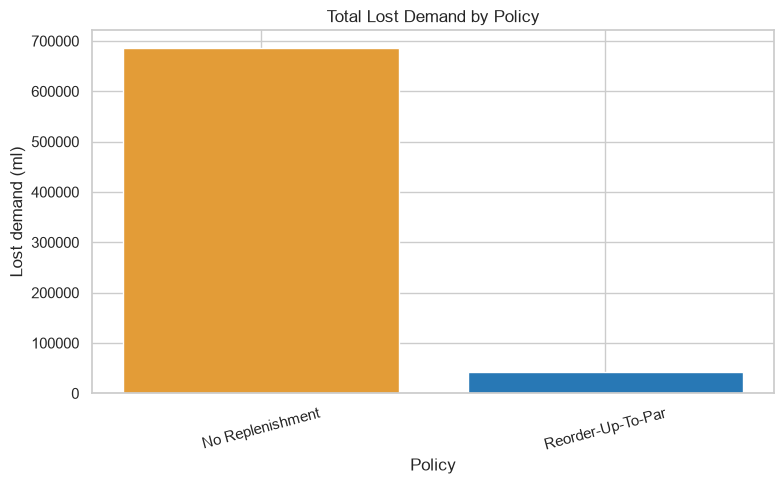

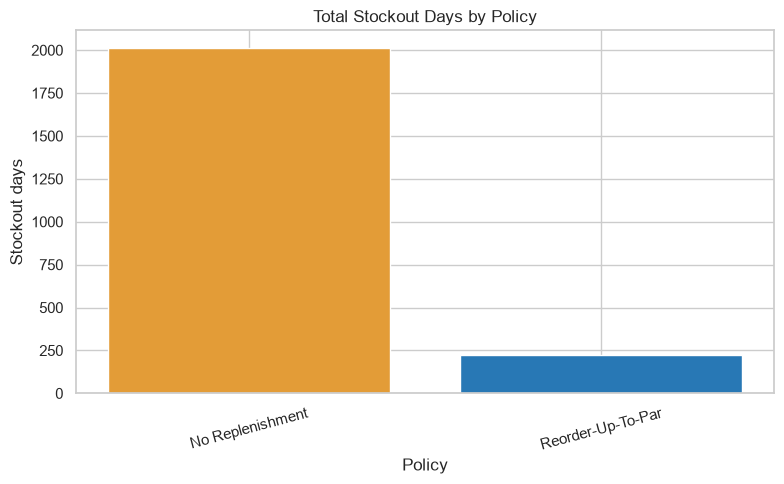

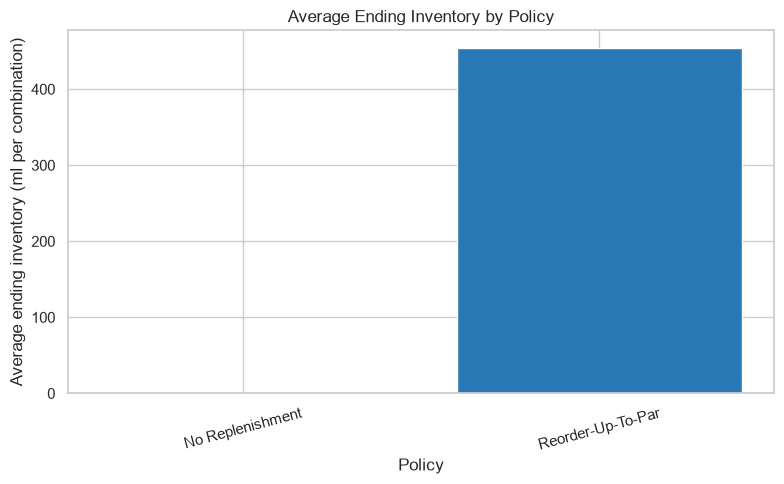

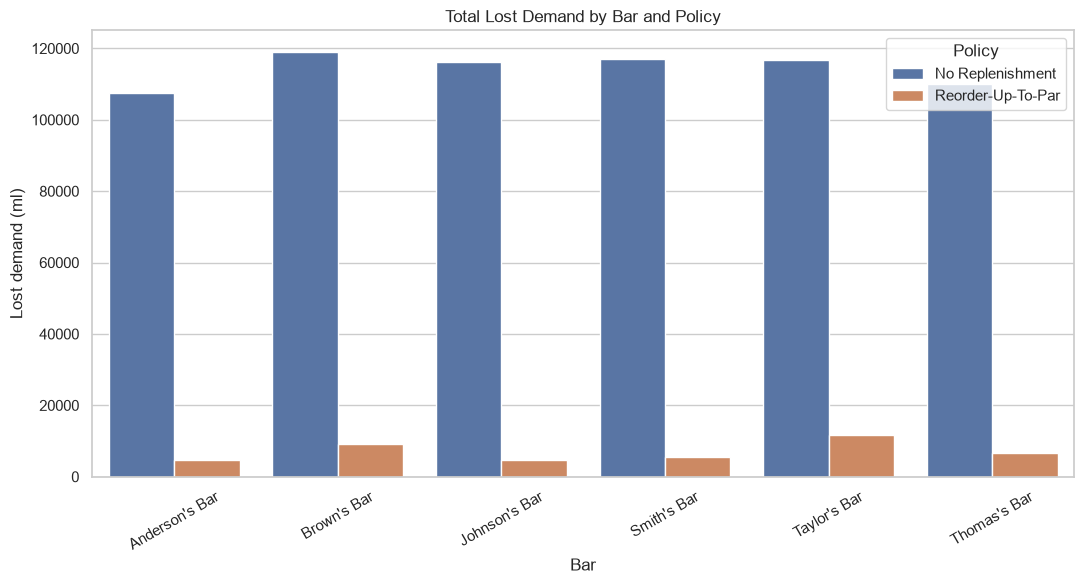

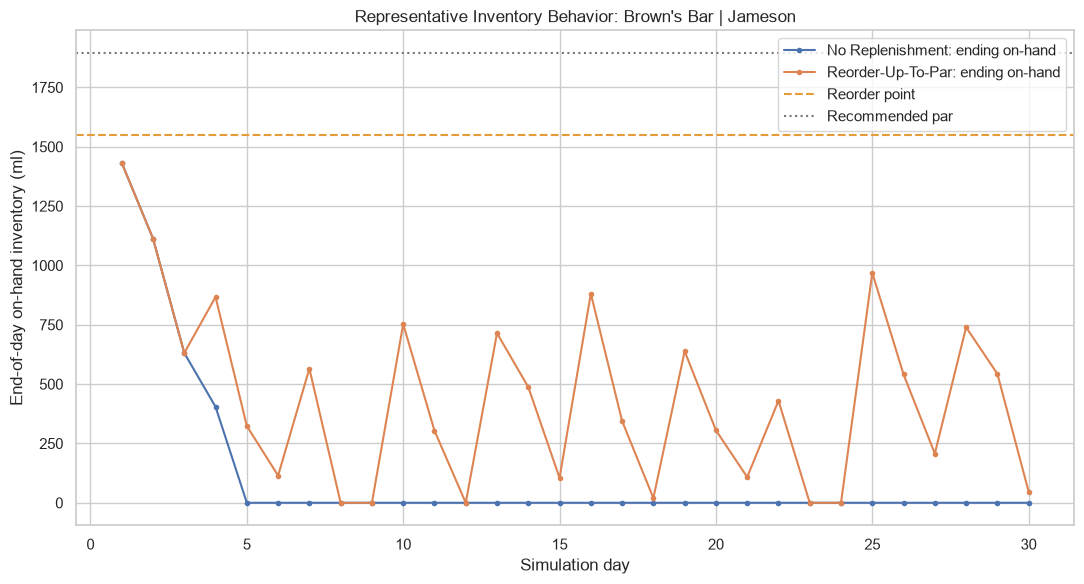

Representative combination selected from the highest no-replenishment lost-demand group with a reorder-policy receipt when available: Brown's Bar / Jameson


In [32]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(
    policy_comparison_summary.index,
    policy_comparison_summary["Total_Lost_Demand_ml"],
    color=["#E39C37", "#2878B5"],
)
ax.set(title="Total Lost Demand by Policy", xlabel="Policy", ylabel="Lost demand (ml)")
ax.tick_params(axis="x", rotation=15)
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(
    policy_comparison_summary.index,
    policy_comparison_summary["Total_Stockout_Days"],
    color=["#E39C37", "#2878B5"],
)
ax.set(title="Total Stockout Days by Policy", xlabel="Policy", ylabel="Stockout days")
ax.tick_params(axis="x", rotation=15)
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(
    policy_comparison_summary.index,
    policy_comparison_summary["Average_Ending_Inventory_ml"],
    color=["#E39C37", "#2878B5"],
)
ax.set(
    title="Average Ending Inventory by Policy",
    xlabel="Policy",
    ylabel="Average ending inventory (ml per combination)",
)
ax.tick_params(axis="x", rotation=15)
fig.tight_layout()
plt.show()

lost_demand_by_bar = (
    simulation_results.groupby([BAR_COLUMN, "Policy"], as_index=False)
    .agg(Lost_Demand_ml=("Lost_Demand_ml", "sum"))
)
fig, ax = plt.subplots(figsize=(11, 6))
sns.barplot(
    data=lost_demand_by_bar,
    x=BAR_COLUMN,
    y="Lost_Demand_ml",
    hue="Policy",
    ax=ax,
)
ax.set(title="Total Lost Demand by Bar and Policy", xlabel="Bar", ylabel="Lost demand (ml)")
ax.tick_params(axis="x", rotation=30)
fig.tight_layout()
plt.show()

no_replenishment_results = simulation_results.loc[
    simulation_results["Policy"].eq("No Replenishment")
]
reorder_policy_details = daily_simulation_details.loc[
    daily_simulation_details["Policy"].eq("Reorder-Up-To-Par")
]
combinations_with_receipts = reorder_policy_details.loc[
    reorder_policy_details["Orders_Received_ml"].gt(0),
    SIMULATION_COMBINATION_COLUMNS,
].drop_duplicates()
representative_candidates = no_replenishment_results.merge(
    combinations_with_receipts,
    on=SIMULATION_COMBINATION_COLUMNS,
    how="inner",
)
if representative_candidates.empty:
    representative_candidates = no_replenishment_results.copy()
representative_row = representative_candidates.sort_values(
    "Lost_Demand_ml", ascending=False
).iloc[0]
representative_combination = tuple(
    representative_row[column] for column in SIMULATION_COMBINATION_COLUMNS
)
representative_recommendation = inventory_recommendations.loc[
    inventory_recommendations[SIMULATION_COMBINATION_COLUMNS]
    .eq(pd.Series(representative_combination, index=SIMULATION_COMBINATION_COLUMNS))
    .all(axis=1)
].iloc[0]
representative_details = daily_simulation_details.loc[
    daily_simulation_details[SIMULATION_COMBINATION_COLUMNS]
    .eq(pd.Series(representative_combination, index=SIMULATION_COMBINATION_COLUMNS))
    .all(axis=1)
]

fig, ax = plt.subplots(figsize=(11, 6))
for policy in SIMULATION_POLICIES:
    policy_trace = representative_details.loc[
        representative_details["Policy"].eq(policy)
    ]
    ax.plot(
        policy_trace["Simulation_Day"],
        policy_trace["Ending_Inventory_ml"],
        marker="o",
        markersize=3,
        label=f"{policy}: ending on-hand",
    )
ax.axhline(
    representative_recommendation["Reorder_Point_ml"],
    color="#E39C37",
    linestyle="--",
    label="Reorder point",
)
ax.axhline(
    representative_recommendation["Recommended_Par_Level_ml"],
    color="#777777",
    linestyle=":",
    label="Recommended par",
)
ax.set(
    title=(
        "Representative Inventory Behavior: "
        f"{representative_combination[0]} | {representative_combination[1]}"
    ),
    xlabel="Simulation day",
    ylabel="End-of-day on-hand inventory (ml)",
)
ax.legend()
fig.tight_layout()
plt.show()
print(
    "Representative combination selected from the highest no-replenishment lost-demand "
    "group with a reorder-policy receipt when available: "
    f"{representative_combination[0]} / {representative_combination[1]}"
)

### 7.6 Validation, manual event review, and limitations

Validation checks combination and policy counts, non-negative demand and inventory, demand conservation, complete required summary fields, non-negative orders/outstanding quantities, and reproducibility with the same seed. The manual event table shows the placement and receipt sequence for one combination.

This is a hypothetical scenario, not an actual historical backtest. The original observations are irregularly spaced and are used as a daily demand proxy; actual POS demand, lost sales, supplier lead times, and replenishment records are unavailable. The 95% service level is illustrative, and the safety/reorder/par inputs remain provisional. Outcomes do not prove actual cost savings or operational improvements.

In [33]:
simulation_result_required_columns = [
    *SIMULATION_COMBINATION_COLUMNS,
    "Policy",
    "Initial_Inventory_ml",
    "Total_Demand_ml",
    "Fulfilled_Demand_ml",
    "Lost_Demand_ml",
    "Stockout_Days",
    "Average_Inventory_ml",
    "Ending_Inventory_ml",
    "Orders_Placed",
    "Total_Order_Quantity_ml",
    "Outstanding_Order_Quantity_ml",
]
missing_simulation_values = simulation_results[
    simulation_result_required_columns
].isna().sum()

unique_bar_brand_count = simulation_results[
    [BAR_COLUMN, BRAND_COLUMN]
].drop_duplicates().shape[0]
combinations_per_policy = simulation_results.groupby("Policy")[
    [BAR_COLUMN, BRAND_COLUMN]
].apply(lambda group: group.drop_duplicates().shape[0])
policy_count_per_combination = simulation_results.groupby(
    SIMULATION_COMBINATION_COLUMNS, dropna=False
)["Policy"].nunique()
if unique_bar_brand_count != 96:
    raise AssertionError(f"Expected 96 bar-brand combinations, found {unique_bar_brand_count}.")
if not combinations_per_policy.eq(96).all():
    raise AssertionError(f"Expected 96 combinations per policy, got {combinations_per_policy.to_dict()}.")
if len(simulation_results) != 96 * len(SIMULATION_POLICIES):
    raise AssertionError("The result row count does not equal combinations times policies.")
if not policy_count_per_combination.eq(2).all():
    raise AssertionError("Each combination must have exactly two policy results.")
if simulation_results.duplicated(
    subset=[*SIMULATION_COMBINATION_COLUMNS, "Policy"]
).any():
    raise AssertionError("Duplicate combination-policy results were found.")
if missing_simulation_values.any():
    raise AssertionError("Required simulation summary fields contain missing values.")

nonnegative_summary_columns = [
    "Initial_Inventory_ml",
    "Total_Demand_ml",
    "Fulfilled_Demand_ml",
    "Lost_Demand_ml",
    "Average_Inventory_ml",
    "Ending_Inventory_ml",
    "Orders_Placed",
    "Total_Order_Quantity_ml",
    "Outstanding_Order_Quantity_ml",
]
if (simulation_results[nonnegative_summary_columns] < 0).any().any():
    raise AssertionError("Negative demand, inventory, or order quantities were found.")
if not np.allclose(
    simulation_results["Fulfilled_Demand_ml"] + simulation_results["Lost_Demand_ml"],
    simulation_results["Total_Demand_ml"],
):
    raise AssertionError("Fulfilled plus lost demand does not equal total demand.")
if (daily_simulation_details["Daily_Demand_ml"] < 0).any():
    raise AssertionError("Negative simulated daily demand was found.")
nonnegative_daily_columns = [
    "Inventory_Before_Receipts_ml",
    "Orders_Received_ml",
    "Available_Inventory_Before_Demand_ml",
    "Fulfilled_Demand_ml",
    "Lost_Demand_ml",
    "Ending_Inventory_ml",
    "Inventory_Position_After_Demand_Before_Order_ml",
    "Order_Placed_ml",
    "Outstanding_Order_Quantity_ml",
    "Inventory_Position_After_Order_ml",
]
if (daily_simulation_details[nonnegative_daily_columns] < 0).any().any():
    raise AssertionError("Negative daily inventory or quantity values were found.")
if daily_simulation_details["Outstanding_Order_Count"].gt(1).any():
    raise AssertionError("More than one order was outstanding for a combination.")
if not np.allclose(
    daily_simulation_details["Fulfilled_Demand_ml"]
    + daily_simulation_details["Lost_Demand_ml"],
    daily_simulation_details["Daily_Demand_ml"],
):
    raise AssertionError("A daily fulfilled/lost demand balance does not reconcile.")

order_events = daily_simulation_details.loc[
    daily_simulation_details["Order_Placed_ml"].gt(0)
]
for _, order_event in order_events.iterrows():
    expected_arrival_day = int(order_event["Simulation_Day"] + LEAD_TIME_DAYS)
    if order_event["Scheduled_Arrival_Day"] != expected_arrival_day:
        raise AssertionError("An order arrival does not match the configured lead time.")
    same_policy_rows = daily_simulation_details.loc[
        daily_simulation_details[SIMULATION_COMBINATION_COLUMNS]
        .eq(order_event[SIMULATION_COMBINATION_COLUMNS])
        .all(axis=1)
        & daily_simulation_details["Policy"].eq(order_event["Policy"])
    ]
    if expected_arrival_day <= SIMULATION_DAYS:
        receipt = same_policy_rows.loc[
            same_policy_rows["Simulation_Day"].eq(expected_arrival_day),
            "Orders_Received_ml",
        ]
        if len(receipt) != 1 or not np.isclose(
            receipt.iloc[0], order_event["Order_Placed_ml"]
        ):
            raise AssertionError("An in-horizon order was not received on its scheduled day.")
    else:
        matching_summary = simulation_results.loc[
            simulation_results[SIMULATION_COMBINATION_COLUMNS]
            .eq(order_event[SIMULATION_COMBINATION_COLUMNS])
            .all(axis=1)
            & simulation_results["Policy"].eq(order_event["Policy"])
        ]
        if matching_summary["Outstanding_Order_Quantity_ml"].iloc[0] < order_event["Order_Placed_ml"]:
            raise AssertionError("An order due beyond the horizon was not left outstanding.")

repeated_demand_paths, _ = generate_empirical_demand_scenarios(
    daily_demand, SIMULATION_DAYS, SIMULATION_SEED
)
if not all(
    np.array_equal(simulation_demand_paths[key], repeated_demand_paths[key])
    for key in simulation_demand_paths
):
    raise AssertionError("Re-running demand generation with the same seed changed the paths.")
repeated_simulation_results, repeated_daily_details = run_replenishment_simulation(
    repeated_demand_paths, inventory_recommendations
)
pd.testing.assert_frame_equal(
    simulation_results.reset_index(drop=True),
    repeated_simulation_results.reset_index(drop=True),
)
pd.testing.assert_frame_equal(
    daily_simulation_details.reset_index(drop=True),
    repeated_daily_details.reset_index(drop=True),
)

if not order_events.empty:
    received_combinations = daily_simulation_details.loc[
        daily_simulation_details["Policy"].eq("Reorder-Up-To-Par")
        & daily_simulation_details["Orders_Received_ml"].gt(0),
        SIMULATION_COMBINATION_COLUMNS,
    ].drop_duplicates()
    eligible_no_replenishment = simulation_results.loc[
        simulation_results["Policy"].eq("No Replenishment")
    ].merge(received_combinations, on=SIMULATION_COMBINATION_COLUMNS, how="inner")
    if eligible_no_replenishment.empty:
        manual_key = tuple(
            simulation_results.loc[
                simulation_results["Policy"].eq("No Replenishment")
            ].sort_values("Lost_Demand_ml", ascending=False).iloc[0][column]
            for column in SIMULATION_COMBINATION_COLUMNS
        )
    else:
        manual_row = eligible_no_replenishment.sort_values(
            "Lost_Demand_ml", ascending=False
        ).iloc[0]
        manual_key = tuple(manual_row[column] for column in SIMULATION_COMBINATION_COLUMNS)
    manual_policy_sequence = daily_simulation_details.loc[
        daily_simulation_details[SIMULATION_COMBINATION_COLUMNS]
        .eq(pd.Series(manual_key, index=SIMULATION_COMBINATION_COLUMNS))
        .all(axis=1)
        & daily_simulation_details["Policy"].eq("Reorder-Up-To-Par")
    ].sort_values("Simulation_Day")
    first_placed_order = manual_policy_sequence.loc[
        manual_policy_sequence["Order_Placed_ml"].gt(0)
    ].iloc[0]
    first_arrival_day = int(first_placed_order["Scheduled_Arrival_Day"])
    display_start = max(1, int(first_placed_order["Simulation_Day"]) - 1)
    display_end = min(SIMULATION_DAYS, first_arrival_day + 1)
    manual_event_window = manual_policy_sequence.loc[
        manual_policy_sequence["Simulation_Day"].between(display_start, display_end),
        [
            "Simulation_Day",
            "Inventory_Before_Receipts_ml",
            "Orders_Received_ml",
            "Available_Inventory_Before_Demand_ml",
            "Daily_Demand_ml",
            "Fulfilled_Demand_ml",
            "Lost_Demand_ml",
            "Ending_Inventory_ml",
            "Order_Placed_ml",
            "Scheduled_Arrival_Day",
            "Outstanding_Order_Quantity_ml",
        ],
    ]
    print(
        "Manual reorder sequence: "
        f"{manual_key[0]} / {manual_key[1]} / {manual_key[2]}"
    )
    print(
        f"Order placed on day {int(first_placed_order['Simulation_Day'])}; "
        f"scheduled to arrive before demand on day {first_arrival_day}."
    )
    display(manual_event_window)
else:
    print("No reorder orders were triggered; daily inventory sequence is available in daily_simulation_details.")

print("Validation passed: 96 combinations, two policies each, non-negative inventory/demand/orders, demand reconciled, no missing required summary values, and repeatable results.")
print(f"Number of combinations simulated: {unique_bar_brand_count}")
print(f"Number of simulation days: {SIMULATION_DAYS}")
print("Assumptions:")
print(f"- Lead time: {LEAD_TIME_DAYS} days")
print(f"- Service level: {SERVICE_LEVEL:.0%}")
print(f"- Random seed: {SIMULATION_SEED}")
print("Policy comparison summary:")
display(policy_comparison_summary)
print("Combinations with the highest simulated lost demand by policy:")
top_lost_demand_examples = (
    simulation_results.sort_values("Lost_Demand_ml", ascending=False)
    .groupby("Policy", group_keys=False)
    .head(3)
    .sort_values(["Policy", "Lost_Demand_ml"], ascending=[True, False])
)
display(
    top_lost_demand_examples[
        [
            BAR_COLUMN,
            BRAND_COLUMN,
            "Alcohol_Type",
            "Policy",
            "Total_Demand_ml",
            "Lost_Demand_ml",
            "Stockout_Days",
            "Ending_Inventory_ml",
            "Outstanding_Order_Quantity_ml",
        ]
    ]
)

Manual reorder sequence: Brown's Bar / Jameson / Whiskey
Order placed on day 1; scheduled to arrive before demand on day 4.


,Simulation_Day,Inventory_Before_Receipts_ml,Orders_Received_ml,Available_Inventory_Before_Demand_ml,Daily_Demand_ml,Fulfilled_Demand_ml,Lost_Demand_ml,Ending_Inventory_ml,Order_Placed_ml,Scheduled_Arrival_Day,Outstanding_Order_Quantity_ml
1530,1,1895.00,0.0,1895.00,462.80,462.80,0.0,1432.20,462.80,4.0,462.80
1531,2,1432.20,0.0,1432.20,318.88,318.88,0.0,1113.32,0.00,NaN,462.80
1532,3,1113.32,0.0,1113.32,482.22,482.22,0.0,631.10,0.00,NaN,462.80
1533,4,631.10,462.8,1093.90,226.85,226.85,0.0,867.05,1027.95,7.0,1027.95
1534,5,867.05,0.0,867.05,543.61,543.61,0.0,323.44,0.00,NaN,1027.95


Validation passed: 96 combinations, two policies each, non-negative inventory/demand/orders, demand reconciled, no missing required summary values, and repeatable results.
Number of combinations simulated: 96
Number of simulation days: 30
Assumptions:
- Lead time: 3 days
- Service level: 95%
- Random seed: 42
Policy comparison summary:


,Total_Demand_ml,Total_Fulfilled_Demand_ml,Total_Lost_Demand_ml,Total_Stockout_Days,Number_of_Combinations_Experiencing_Stockouts,Average_Ending_Inventory_ml,Total_Orders_Placed
Policy,,,,,,,
No Replenishment,853016.51,166445.00,686571.51,2014,96,0.000000,0
Reorder-Up-To-Par,853016.51,810290.34,42726.17,224,88,454.435313,934


Combinations with the highest simulated lost demand by policy:


,Bar Name,Brand Name,Alcohol_Type,Policy,Total_Demand_ml,Lost_Demand_ml,Stockout_Days,Ending_Inventory_ml,Outstanding_Order_Quantity_ml
50,Brown's Bar,Jameson,Whiskey,No Replenishment,12778.53,10883.53,26,0.00,0.00
44,Brown's Bar,Grey Goose,Vodka,No Replenishment,12291.21,10365.21,23,0.00,0.00
86,Johnson's Bar,Malibu,Rum,No Replenishment,11719.02,9768.02,24,0.00,0.00
45,Brown's Bar,Grey Goose,Vodka,Reorder-Up-To-Par,12291.21,1351.64,6,0.00,1124.16
185,Thomas's Bar,Miller,Beer,Reorder-Up-To-Par,11508.96,1335.05,4,814.83,1263.17
151,Taylor's Bar,Malibu,Rum,Reorder-Up-To-Par,9249.11,1307.54,5,781.34,388.22


# Executive Dashboard ? Hotel Bar Demand Forecasting and Inventory Optimization

This executive view brings together the project's historical consumption patterns, Phase 5 demand-forecasting performance, Phase 6 provisional inventory recommendations, and Phase 7 replenishment-simulation outcomes. Inventory recommendations and simulation results are provisional because historical observations are irregularly spaced; they are not validated daily demand or an actual historical operations backtest.

## Key performance indicators

The KPIs below are drawn from the existing Phase 3, 5, 6, and 7 results. Historical bar and brand charts use the recorded consumption summaries from Phase 3.

,KPI,Value
0,Total historical consumption,"1,968,681.66 ml"
1,Number of bars,6
2,Number of brands,16
3,Bar-brand combinations,96
4,Historical records,"6,575"
5,Random Forest MAE,147.911 ml
6,Random Forest WAPE,49.107%
7,Total recommended par quantity,"166,445 ml"
8,Simulated total demand,"853,016.51 ml"
9,Simulated lost demand (reorder-up-to-par),"42,726.17 ml"


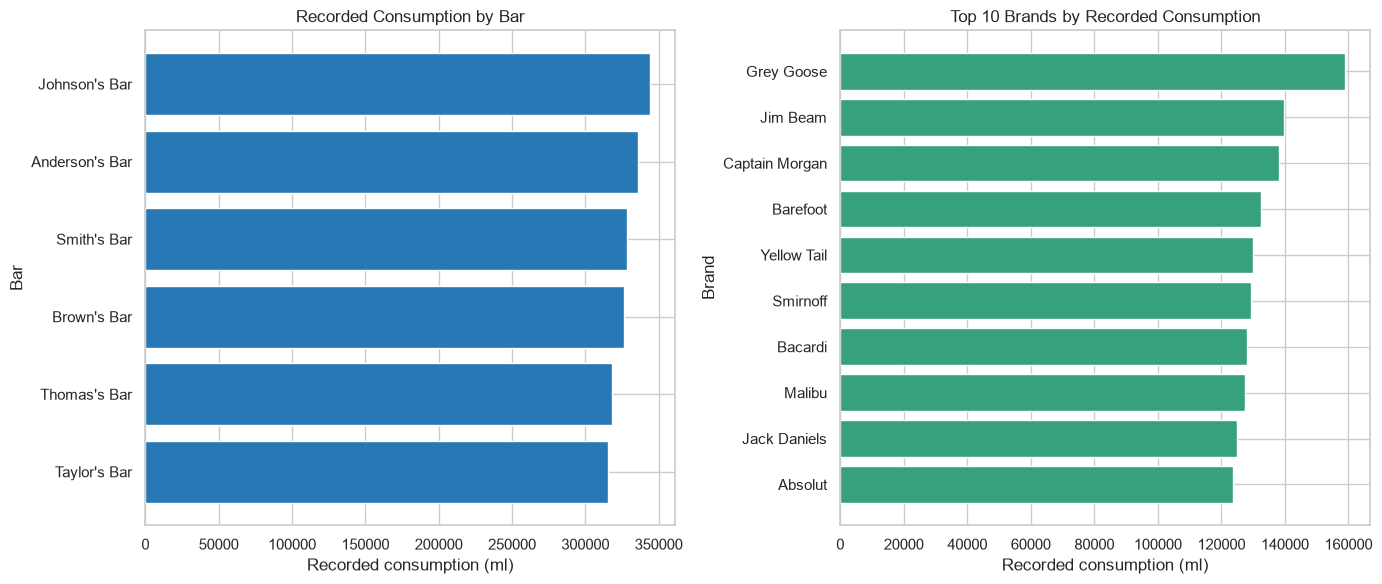

In [34]:
dashboard_recommendation_count = len(inventory_recommendations)
dashboard_bar_brand_count = inventory_recommendations[
    [BAR_COLUMN, BRAND_COLUMN]
].drop_duplicates().shape[0]
dashboard_total_recommended_par_ml = inventory_recommendations[
    "Recommended_Par_Level_ml"
].sum()
dashboard_reorder_policy = "Reorder-Up-To-Par"

dashboard_kpi_rows = [
    ("Total historical consumption", f"{total_recorded_consumption_ml:,.2f} ml"),
    ("Number of bars", f"{df[BAR_COLUMN].nunique():,}"),
    ("Number of brands", f"{df[BRAND_COLUMN].nunique():,}"),
    ("Bar-brand combinations", f"{dashboard_bar_brand_count:,}"),
    ("Historical records", f"{len(df):,}"),
    (
        "Random Forest MAE",
        f"{comparison_results.loc['MAE (ml)', 'Random Forest']:,.3f} ml",
    ),
    (
        "Random Forest WAPE",
        f"{comparison_results.loc['WAPE (%)', 'Random Forest']:.3f}%",
    ),
    ("Total recommended par quantity", f"{dashboard_total_recommended_par_ml:,.0f} ml"),
    (
        "Simulated total demand",
        f"{policy_comparison_summary.loc[dashboard_reorder_policy, 'Total_Demand_ml']:,.2f} ml",
    ),
    (
        "Simulated lost demand (reorder-up-to-par)",
        f"{policy_comparison_summary.loc[dashboard_reorder_policy, 'Total_Lost_Demand_ml']:,.2f} ml",
    ),
    (
        "Replenishment orders placed",
        f"{policy_comparison_summary.loc[dashboard_reorder_policy, 'Total_Orders_Placed']:,.0f}",
    ),
]
dashboard_kpi_summary = pd.DataFrame(dashboard_kpi_rows, columns=["KPI", "Value"])
display(dashboard_kpi_summary)

sns.set_theme(style="whitegrid", context="notebook")
top_historical_bars = consumption_by_bar.head(6).sort_values(ascending=True)
top_historical_brands = consumption_by_brand.head(10).sort_values(ascending=True)
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].barh(
    top_historical_bars.index.astype(str),
    top_historical_bars.values,
    color="#2878B5",
)
axes[0].set(
    title="Recorded Consumption by Bar",
    xlabel="Recorded consumption (ml)",
    ylabel="Bar",
)
axes[1].barh(
    top_historical_brands.index.astype(str),
    top_historical_brands.values,
    color="#36A17A",
)
axes[1].set(
    title="Top 10 Brands by Recorded Consumption",
    xlabel="Recorded consumption (ml)",
    ylabel="Brand",
)
fig.tight_layout()
plt.show()

## Forecasting performance

The table and chart reuse the Phase 5 chronological-test results. Random Forest had lower MAE, RMSE, and WAPE than the previous-observation baseline on that holdout. WAPE remains relatively high, and predictions apply to recorded observation points rather than a complete daily demand series.

Phase 5 chronological test-set comparison:


,Previous Observation Baseline,Random Forest,Random Forest improvement over baseline (%)
Metric,,,
MAE (ml),176.278,147.911,16.092
RMSE (ml),238.279,180.944,24.062
WAPE (%),58.525,49.107,16.092


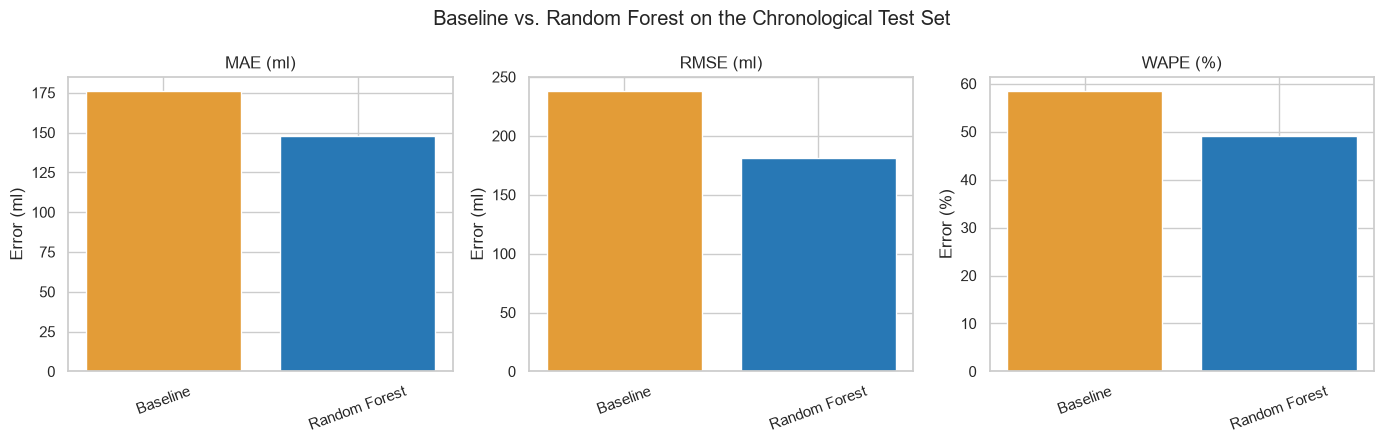

In [35]:
dashboard_model_comparison = comparison_results.copy()
dashboard_metric_names = ["MAE (ml)", "RMSE (ml)", "WAPE (%)"]
dashboard_model_columns = [
    "Previous Observation Baseline",
    "Random Forest",
    "Random Forest improvement over baseline (%)",
]
print("Phase 5 chronological test-set comparison:")
display(dashboard_model_comparison.loc[dashboard_metric_names, dashboard_model_columns].round(3))

fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))
for ax, metric_name in zip(axes, dashboard_metric_names):
    metric_values = dashboard_model_comparison.loc[
        metric_name,
        ["Previous Observation Baseline", "Random Forest"],
    ]
    ax.bar(
        ["Baseline", "Random Forest"],
        metric_values.values,
        color=["#E39C37", "#2878B5"],
    )
    ax.set_title(metric_name)
    ax.set_ylabel("Error (ml)" if metric_name != "WAPE (%)" else "Error (%)")
    ax.tick_params(axis="x", rotation=20)
fig.suptitle("Baseline vs. Random Forest on the Chronological Test Set")
fig.tight_layout()
plt.show()

## Inventory recommendations

The tables and charts below use the Phase 6 `inventory_recommendations` values without changing the recommendations. Totals by bar or brand are sums of the existing per-combination par values. All figures remain provisional and use the recorded-consumption proxy and illustrative Phase 6 assumptions.

Recommendations: 96
Total recommended par: 166,445 ml
Average par per bar-brand combination: 1,733.8 ml
Highest recommended par combinations:


,Bar Name,Brand Name,Alcohol_Type,Recommended_Par_Level_ml
0,Taylor's Bar,Budweiser,Beer,2081
1,Thomas's Bar,Miller,Beer,2078
2,Anderson's Bar,Sutter Home,Wine,2074
3,Anderson's Bar,Captain Morgan,Rum,2042
4,Johnson's Bar,Budweiser,Beer,2017
5,Johnson's Bar,Smirnoff,Vodka,1984
6,Brown's Bar,Coors,Beer,1956
7,Johnson's Bar,Malibu,Rum,1951
8,Smith's Bar,Grey Goose,Vodka,1948
9,Taylor's Bar,Captain Morgan,Rum,1946


Highest safety-stock combinations:


,Bar Name,Brand Name,Alcohol_Type,Safety_Stock_ml
0,Brown's Bar,Coors,Beer,736
1,Anderson's Bar,Yellow Tail,Wine,658
2,Anderson's Bar,Miller,Beer,634
3,Thomas's Bar,Budweiser,Beer,634
4,Taylor's Bar,Miller,Beer,630


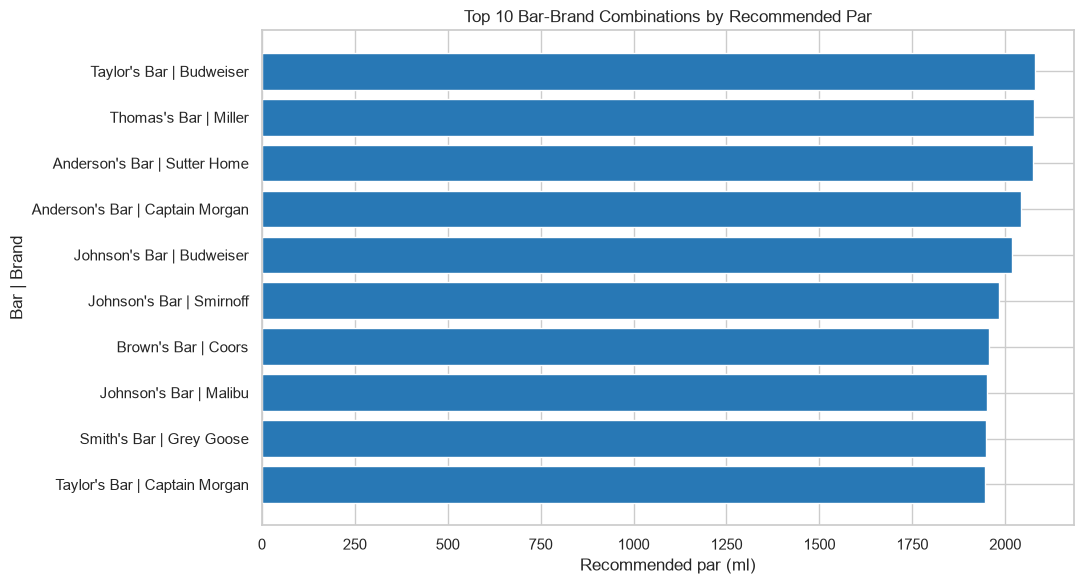

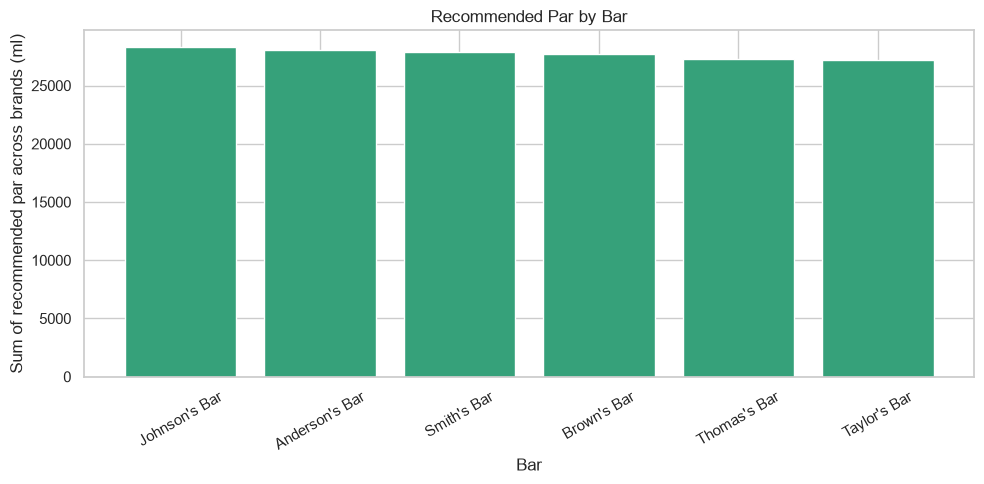

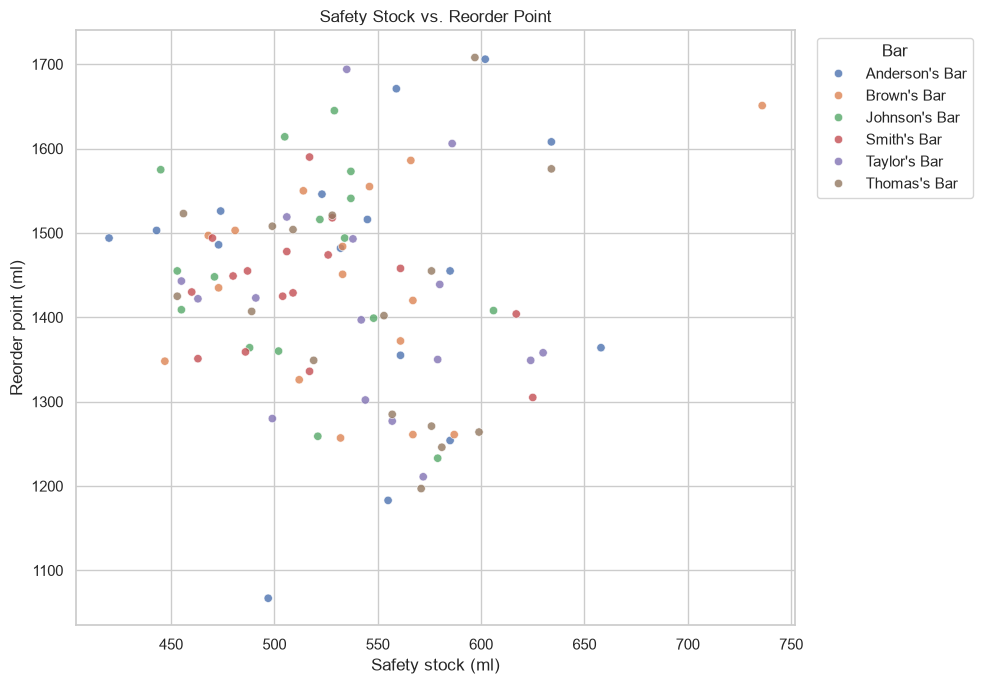

In [36]:
dashboard_average_par_ml = inventory_recommendations[
    "Recommended_Par_Level_ml"
].mean()
dashboard_top_par_combinations = inventory_recommendations.nlargest(
    10, "Recommended_Par_Level_ml"
).copy()
dashboard_top_safety_stock_combinations = inventory_recommendations.nlargest(
    5, "Safety_Stock_ml"
).copy()
print(f"Recommendations: {dashboard_recommendation_count:,}")
print(f"Total recommended par: {dashboard_total_recommended_par_ml:,.0f} ml")
print(f"Average par per bar-brand combination: {dashboard_average_par_ml:,.1f} ml")
print("Highest recommended par combinations:")
display(
    dashboard_top_par_combinations[
        [BAR_COLUMN, BRAND_COLUMN, "Alcohol_Type", "Recommended_Par_Level_ml"]
    ].reset_index(drop=True)
)
print("Highest safety-stock combinations:")
display(
    dashboard_top_safety_stock_combinations[
        [BAR_COLUMN, BRAND_COLUMN, "Alcohol_Type", "Safety_Stock_ml"]
    ].reset_index(drop=True)
)

par_chart_data = dashboard_top_par_combinations.sort_values(
    "Recommended_Par_Level_ml", ascending=True
).copy()
par_chart_data["Bar_Brand"] = (
    par_chart_data[BAR_COLUMN].astype(str)
    + " | "
    + par_chart_data[BRAND_COLUMN].astype(str)
)
fig, ax = plt.subplots(figsize=(11, 6))
ax.barh(
    par_chart_data["Bar_Brand"],
    par_chart_data["Recommended_Par_Level_ml"],
    color="#2878B5",
)
ax.set(
    title="Top 10 Bar-Brand Combinations by Recommended Par",
    xlabel="Recommended par (ml)",
    ylabel="Bar | Brand",
)
fig.tight_layout()
plt.show()

dashboard_par_by_bar = (
    inventory_recommendations.groupby(BAR_COLUMN)["Recommended_Par_Level_ml"]
    .sum()
    .sort_values(ascending=False)
)
fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(dashboard_par_by_bar.index.astype(str), dashboard_par_by_bar.values, color="#36A17A")
ax.set(
    title="Recommended Par by Bar",
    xlabel="Bar",
    ylabel="Sum of recommended par across brands (ml)",
)
ax.tick_params(axis="x", rotation=30)
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(10, 7))
sns.scatterplot(
    data=inventory_recommendations,
    x="Safety_Stock_ml",
    y="Reorder_Point_ml",
    hue=BAR_COLUMN,
    alpha=0.8,
    ax=ax,
)
ax.set(
    title="Safety Stock vs. Reorder Point",
    xlabel="Safety stock (ml)",
    ylabel="Reorder point (ml)",
)
ax.legend(title="Bar", bbox_to_anchor=(1.02, 1), loc="upper left")
fig.tight_layout()
plt.show()

## Replenishment simulation

This section reuses the Phase 7 policy summary and simulation results. Demand and lost-sales totals are scenario outcomes, not realized hotel operations. The percentage reduction compares reorder-up-to-par lost demand with no-replenishment lost demand and safely reports `NaN` if the no-replenishment denominator is zero.

Phase 7 policy comparison:


,Total_Demand_ml,Total_Fulfilled_Demand_ml,Total_Lost_Demand_ml,Total_Stockout_Days,Number_of_Combinations_Experiencing_Stockouts,Average_Ending_Inventory_ml,Total_Orders_Placed
Policy,,,,,,,
No Replenishment,853016.51,166445.00,686571.51,2014,96,0.000000,0
Reorder-Up-To-Par,853016.51,810290.34,42726.17,224,88,454.435313,934


Lost-demand reduction under reorder-up-to-par vs. no replenishment: 93.78% (scenario result)


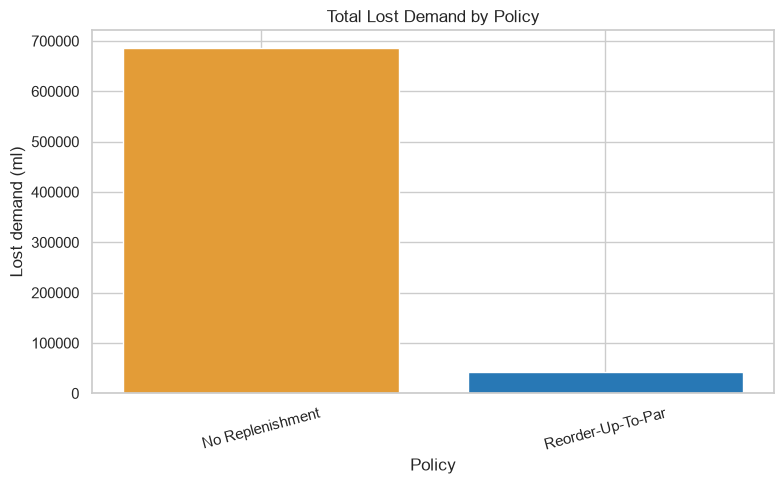

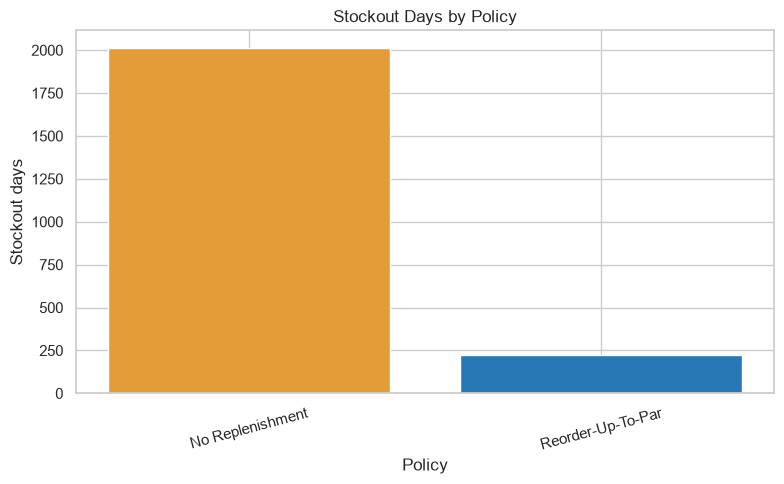

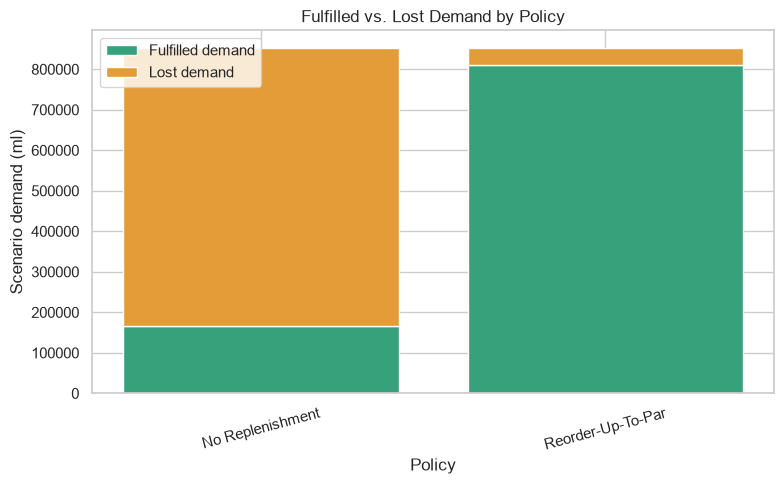

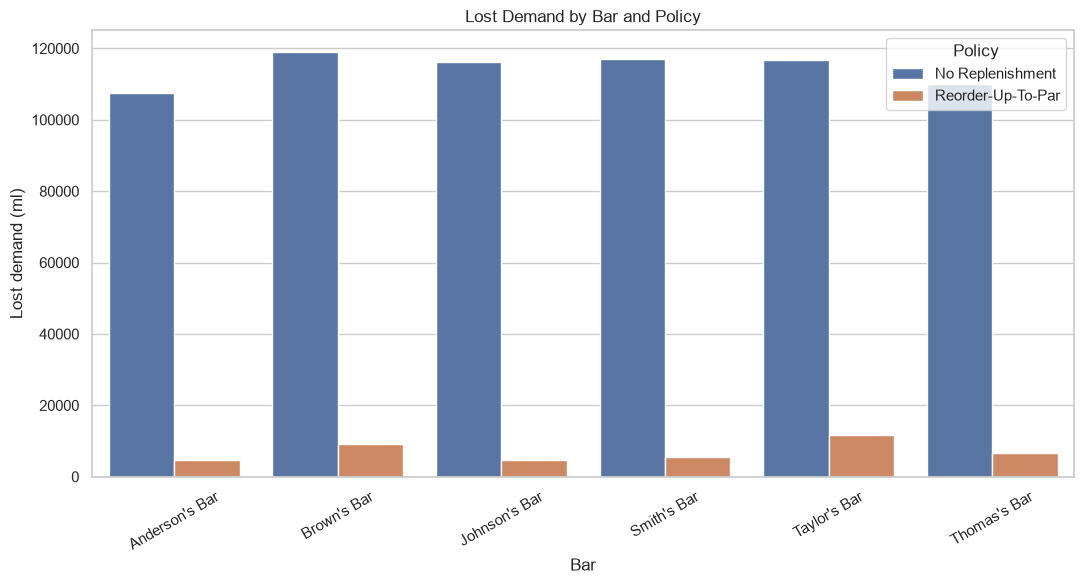

In [37]:
dashboard_simulation_columns = [
    "Total_Demand_ml",
    "Total_Fulfilled_Demand_ml",
    "Total_Lost_Demand_ml",
    "Total_Stockout_Days",
    "Number_of_Combinations_Experiencing_Stockouts",
    "Average_Ending_Inventory_ml",
    "Total_Orders_Placed",
]
dashboard_policy_summary = policy_comparison_summary[
    dashboard_simulation_columns
].copy()
print("Phase 7 policy comparison:")
display(dashboard_policy_summary)

no_replenishment_lost_ml = float(
    dashboard_policy_summary.loc["No Replenishment", "Total_Lost_Demand_ml"]
)
reorder_policy_lost_ml = float(
    dashboard_policy_summary.loc[dashboard_reorder_policy, "Total_Lost_Demand_ml"]
)
if no_replenishment_lost_ml == 0:
    dashboard_lost_demand_reduction_pct = np.nan
else:
    dashboard_lost_demand_reduction_pct = (
        (no_replenishment_lost_ml - reorder_policy_lost_ml)
        / no_replenishment_lost_ml
        * 100
    )
if np.isfinite(dashboard_lost_demand_reduction_pct):
    print(
        "Lost-demand reduction under reorder-up-to-par vs. no replenishment: "
        f"{dashboard_lost_demand_reduction_pct:.2f}% (scenario result)"
    )
else:
    print("Lost-demand reduction is undefined because no-replenishment lost demand is zero.")

fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(
    dashboard_policy_summary.index,
    dashboard_policy_summary["Total_Lost_Demand_ml"],
    color=["#E39C37", "#2878B5"],
)
ax.set(title="Total Lost Demand by Policy", xlabel="Policy", ylabel="Lost demand (ml)")
ax.tick_params(axis="x", rotation=15)
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(
    dashboard_policy_summary.index,
    dashboard_policy_summary["Total_Stockout_Days"],
    color=["#E39C37", "#2878B5"],
)
ax.set(title="Stockout Days by Policy", xlabel="Policy", ylabel="Stockout days")
ax.tick_params(axis="x", rotation=15)
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(
    dashboard_policy_summary.index,
    dashboard_policy_summary["Total_Fulfilled_Demand_ml"],
    label="Fulfilled demand",
    color="#36A17A",
)
ax.bar(
    dashboard_policy_summary.index,
    dashboard_policy_summary["Total_Lost_Demand_ml"],
    bottom=dashboard_policy_summary["Total_Fulfilled_Demand_ml"],
    label="Lost demand",
    color="#E39C37",
)
ax.set(
    title="Fulfilled vs. Lost Demand by Policy",
    xlabel="Policy",
    ylabel="Scenario demand (ml)",
)
ax.tick_params(axis="x", rotation=15)
ax.legend()
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(11, 6))
sns.barplot(
    data=lost_demand_by_bar,
    x=BAR_COLUMN,
    y="Lost_Demand_ml",
    hue="Policy",
    ax=ax,
)
ax.set(
    title="Lost Demand by Bar and Policy",
    xlabel="Bar",
    ylabel="Lost demand (ml)",
)
ax.tick_params(axis="x", rotation=30)
fig.tight_layout()
plt.show()

## Business insights

The following points are generated from the existing Phase 3, 5, 6, and 7 outputs. They describe recorded data, a held-out evaluation, and hypothetical scenario outcomes; they are not causal findings or claims of realized financial savings.

In [38]:
from IPython.display import Markdown

top_historical_bar_name = consumption_by_bar.index[0]
top_historical_bar_ml = float(consumption_by_bar.iloc[0])
top_historical_brand_name = consumption_by_brand.index[0]
top_historical_brand_ml = float(consumption_by_brand.iloc[0])
top_par_row = dashboard_top_par_combinations.iloc[0]
top_safety_stock_row = dashboard_top_safety_stock_combinations.iloc[0]
rf_is_better_on_all_reported_metrics = all(
    dashboard_model_comparison.loc[metric, "Random Forest"]
    < dashboard_model_comparison.loc[metric, "Previous Observation Baseline"]
    for metric in dashboard_metric_names
)
if np.isfinite(dashboard_lost_demand_reduction_pct):
    dashboard_lost_demand_reduction_text = (
        f"{dashboard_lost_demand_reduction_pct:.2f}% scenario reduction"
    )
else:
    dashboard_lost_demand_reduction_text = (
        "an undefined percentage reduction because baseline lost demand is zero"
    )

insight_lines = [
    (
        f"- **Historical consumption:** {top_historical_bar_name} has the highest recorded "
        f"bar total ({top_historical_bar_ml:,.2f} ml); {top_historical_brand_name} has the "
        f"highest recorded brand total ({top_historical_brand_ml:,.2f} ml)."
    ),
    (
        "- **Forecasting:** Random Forest "
        f"{'outperformed' if rf_is_better_on_all_reported_metrics else 'did not outperform'} "
        "the previous-observation baseline on all three reported chronological-test metrics; "
        f"its MAE is {dashboard_model_comparison.loc['MAE (ml)', 'Random Forest']:,.3f} ml "
        f"and WAPE is {dashboard_model_comparison.loc['WAPE (%)', 'Random Forest']:.3f}%. "
        "WAPE remains relatively high and predictions are at recorded observations."
    ),
    (
        f"- **Inventory:** the highest recommended par is {top_par_row[BAR_COLUMN]} / "
        f"{top_par_row[BRAND_COLUMN]} ({top_par_row['Recommended_Par_Level_ml']:,.0f} ml); "
        f"the highest safety stock is {top_safety_stock_row[BAR_COLUMN]} / "
        f"{top_safety_stock_row[BRAND_COLUMN]} "
        f"({top_safety_stock_row['Safety_Stock_ml']:,.0f} ml)."
    ),
    (
        f"- **Simulation:** reorder-up-to-par lost {reorder_policy_lost_ml:,.2f} ml versus "
        f"{no_replenishment_lost_ml:,.2f} ml without replenishment, a "
        f"{dashboard_lost_demand_reduction_text}; "
        f"it placed {dashboard_policy_summary.loc[dashboard_reorder_policy, 'Total_Orders_Placed']:,.0f} "
        "orders and still had stockouts in "
        f"{dashboard_policy_summary.loc[dashboard_reorder_policy, 'Number_of_Combinations_Experiencing_Stockouts']:.0f} "
        "combinations."
    ),
    "- **Operational caveat:** observations are sparse and irregular; the inventory and simulation demand proxy is not validated daily POS demand, and actual supplier, occupancy, and lost-sales data are unavailable.",
]
display(Markdown("\n".join(insight_lines)))

- **Historical consumption:** Johnson's Bar has the highest recorded bar total (344,184.38 ml); Grey Goose has the highest recorded brand total (158,924.02 ml).
- **Forecasting:** Random Forest outperformed the previous-observation baseline on all three reported chronological-test metrics; its MAE is 147.911 ml and WAPE is 49.107%. WAPE remains relatively high and predictions are at recorded observations.
- **Inventory:** the highest recommended par is Taylor's Bar / Budweiser (2,081 ml); the highest safety stock is Brown's Bar / Coors (736 ml).
- **Simulation:** reorder-up-to-par lost 42,726.17 ml versus 686,571.51 ml without replenishment, a 93.78% scenario reduction; it placed 934 orders and still had stockouts in 88 combinations.
- **Operational caveat:** observations are sparse and irregular; the inventory and simulation demand proxy is not validated daily POS demand, and actual supplier, occupancy, and lost-sales data are unavailable.

## Assumptions and limitations

- Historical observations are irregularly spaced; missing dates were not treated as zero demand.
- Recorded consumption is used as a **provisional daily-demand proxy** in inventory calculations and simulation.
- A 3-day lead time, 1-day review period, and 95% service level are illustrative assumptions, not confirmed operating parameters.
- Actual supplier lead-time, purchase-order, POS, occupancy, and lost-sales data are unavailable.
- Phase 7 simulation results are hypothetical scenario outcomes, not an actual historical backtest.
- Forecasting performance is measured at recorded observation points and does not establish production readiness.
- Dashboard comparisons do not prove actual cost savings or operational improvements; recommendations need operational calibration before use.

## Dashboard validation

The final checks below compare the dashboard views with the existing Phase 3, 5, 6, and 7 DataFrames and variables. They do not fit or retrain a forecasting model.

In [39]:
dashboard_expected_historical_total_ml = df[CONSUMPTION_COLUMN].sum(min_count=1)
if not np.isclose(total_recorded_consumption_ml, dashboard_expected_historical_total_ml):
    raise AssertionError("Dashboard historical consumption KPI differs from the Phase 3 source total.")
if dashboard_recommendation_count != len(inventory_recommendations):
    raise AssertionError("Dashboard recommendation count differs from the Phase 6 table.")
if not np.isclose(
    dashboard_total_recommended_par_ml,
    inventory_recommendations["Recommended_Par_Level_ml"].sum(),
):
    raise AssertionError("Dashboard par total differs from the Phase 6 recommendation table.")
if not dashboard_model_comparison.equals(comparison_results):
    raise AssertionError("Dashboard metrics differ from the saved Phase 5 comparison results.")
if not dashboard_policy_summary.equals(
    policy_comparison_summary[dashboard_simulation_columns]
):
    raise AssertionError("Dashboard simulation summary differs from the Phase 7 results.")
if not np.isclose(
    policy_comparison_summary.loc["No Replenishment", "Total_Demand_ml"],
    policy_comparison_summary.loc[dashboard_reorder_policy, "Total_Demand_ml"],
):
    raise AssertionError("The two simulation policies do not use the same total demand path.")

print("Dashboard validation passed:")
print(f"- Historical consumption: {total_recorded_consumption_ml:,.2f} ml; records: {len(df):,}.")
print(f"- Model comparison rows matched Phase 5: {len(dashboard_model_comparison)} metrics.")
print(
    "- Phase 6 recommendation rows and total par matched: "
    f"{dashboard_recommendation_count:,} combinations, {dashboard_total_recommended_par_ml:,.0f} ml."
)
print("- Phase 7 policy totals matched the existing comparison summary.")
print("- No forecasting model was fitted or retrained in the dashboard section.")
print("Dashboard sections created: KPIs/history, forecasting, recommendations, simulation, insights, limitations.")
print("Dashboard charts created: historical consumption, model metrics, three recommendation charts, four simulation charts.")

Dashboard validation passed:
- Historical consumption: 1,968,681.66 ml; records: 6,575.
- Model comparison rows matched Phase 5: 3 metrics.
- Phase 6 recommendation rows and total par matched: 96 combinations, 166,445 ml.
- Phase 7 policy totals matched the existing comparison summary.
- No forecasting model was fitted or retrained in the dashboard section.
Dashboard sections created: KPIs/history, forecasting, recommendations, simulation, insights, limitations.
Dashboard charts created: historical consumption, model metrics, three recommendation charts, four simulation charts.


# Phase 9: Excel Results Export

This phase exports the executed Phase 1?8 results into a formatted workbook. The export reuses the saved forecasting metrics and existing recommendation and simulation tables; it does not retrain a model, change assumptions, fill missing observations, or alter source data. Summary totals describe recorded observations or the stated hypothetical simulation, not validated complete daily demand.


In [40]:
from pathlib import Path

required_export_objects = [
    "df",
    "business_overview",
    "total_recorded_consumption_ml",
    "consumption_by_bar",
    "consumption_by_brand",
    "comparison_results",
    "inventory_recommendations",
    "simulation_results",
    "daily_simulation_details",
    "policy_comparison_summary",
    "bar_brand_coverage",
]
missing_export_objects = [name for name in required_export_objects if name not in globals()]
if missing_export_objects:
    raise NameError(f"Required Phase 1?8 results are unavailable: {missing_export_objects}")

bar_brand_columns = [BAR_COLUMN, BRAND_COLUMN]
simulation_combination_columns = [BAR_COLUMN, BRAND_COLUMN, "Alcohol_Type"]
recommendation_required_columns = [
    BAR_COLUMN,
    BRAND_COLUMN,
    "Alcohol_Type",
    "Observation_Count",
    "Average_Observed_Consumption_ml",
    "Demand_Std_Dev_ml",
    "Safety_Stock_ml",
    "Reorder_Point_ml",
    "Recommended_Par_Level_ml",
    "Recommendation_Confidence",
]
simulation_required_columns = [
    *simulation_combination_columns,
    "Policy",
    "Initial_Inventory_ml",
    "Total_Demand_ml",
    "Fulfilled_Demand_ml",
    "Lost_Demand_ml",
    "Stockout_Days",
    "Average_Inventory_ml",
    "Ending_Inventory_ml",
    "Orders_Placed",
    "Total_Order_Quantity_ml",
    "Outstanding_Order_Quantity_ml",
]
daily_required_columns = [
    *simulation_combination_columns,
    "Policy",
    "Simulation_Day",
    "Daily_Demand_ml",
    "Fulfilled_Demand_ml",
    "Lost_Demand_ml",
    "Ending_Inventory_ml",
]
coverage_required_columns = [
    *bar_brand_columns,
    "Recorded_Observations",
    "Observed_Days",
    "First_Observation_Date",
    "Last_Observation_Date",
    "Average_Gap_Days",
    "Maximum_Gap_Days",
]
for table_name, table, required_columns in [
    ("inventory_recommendations", inventory_recommendations, recommendation_required_columns),
    ("simulation_results", simulation_results, simulation_required_columns),
    ("daily_simulation_details", daily_simulation_details, daily_required_columns),
    ("bar_brand_coverage", bar_brand_coverage, coverage_required_columns),
]:
    missing_columns = [column for column in required_columns if column not in table.columns]
    if missing_columns:
        raise KeyError(f"{table_name} is missing required columns: {missing_columns}")

if inventory_recommendations[bar_brand_columns].isna().any().any():
    raise ValueError("Inventory recommendations contain missing bar or brand identifiers.")
if inventory_recommendations.duplicated(bar_brand_columns).any():
    raise ValueError("Inventory recommendations contain duplicate bar-brand combinations.")
if len(inventory_recommendations) != 96:
    raise AssertionError(f"Expected 96 inventory recommendations, found {len(inventory_recommendations)}.")
if inventory_recommendations[recommendation_required_columns].isna().any().any():
    raise ValueError("Required recommendation fields contain missing values; export cancelled.")

simulation_key = [*simulation_combination_columns, "Policy"]
if simulation_results.duplicated(simulation_key).any():
    raise ValueError("Simulation results contain duplicate combination-policy rows.")
if len(simulation_results) != 192:
    raise AssertionError(f"Expected 192 simulation summaries, found {len(simulation_results)}.")
combinations_per_policy = simulation_results.groupby("Policy")[simulation_combination_columns].apply(
    lambda values: len(values.drop_duplicates())
)
if set(simulation_results["Policy"].unique()) != {"No Replenishment", "Reorder-Up-To-Par"}:
    raise AssertionError("Simulation results do not contain exactly the expected two policies.")
if not combinations_per_policy.eq(96).all():
    raise AssertionError(f"Expected 96 combinations per policy; found {combinations_per_policy.to_dict()}.")
if simulation_results[simulation_required_columns].isna().any().any():
    raise ValueError("Required simulation summary fields contain missing values; export cancelled.")

if daily_simulation_details.duplicated([*simulation_key, "Simulation_Day"]).any():
    raise ValueError("Daily simulation details contain duplicate combination-policy-day records.")
if daily_simulation_details[daily_required_columns].isna().any().any():
    raise ValueError("Required daily simulation fields contain missing values; export cancelled.")
if bar_brand_coverage.duplicated(bar_brand_columns).any():
    raise ValueError("Observation coverage contains duplicate bar-brand combinations.")
if len(bar_brand_coverage) != 96:
    raise AssertionError(f"Expected 96 coverage combinations, found {len(bar_brand_coverage)}.")

model_comparison_export = comparison_results.rename_axis("Metric").reset_index()
inventory_recommendations_export = inventory_recommendations.copy()
simulation_results_export = simulation_results.copy()
daily_simulation_details_export = daily_simulation_details.copy()
bar_performance_export = consumption_by_bar.rename_axis(BAR_COLUMN).reset_index()
brand_performance_export = consumption_by_brand.rename_axis(BRAND_COLUMN).reset_index()
observation_coverage_export = bar_brand_coverage.copy()

if bar_performance_export[BAR_COLUMN].duplicated().any():
    raise ValueError("Bar performance contains duplicate bar rows.")
if brand_performance_export[BRAND_COLUMN].duplicated().any():
    raise ValueError("Brand performance contains duplicate brand rows.")

summary_rows = [
    ("Project", "Title", "Kristalball Hotel Bar Demand Forecasting and Inventory Optimization"),
    ("Project", "Objective", "Summarize recorded consumption, observation-level forecasting, provisional inventory recommendations, and hypothetical replenishment scenarios."),
    ("Dataset Overview", "Original records", int(len(df))),
    ("Dataset Overview", "Original columns", int(df.shape[1])),
    ("Dataset Overview", "Unique bars", int(business_overview["Unique bars"])),
    ("Dataset Overview", "Unique brands", int(business_overview["Unique brands"])),
    ("Dataset Overview", "Alcohol categories", int(business_overview["Alcohol categories"])),
    ("Dataset Overview", "Bar-brand combinations", int(len(inventory_recommendations))),
    ("Historical Consumption", "Total recorded consumption (ml)", float(total_recorded_consumption_ml)),
    ("Historical Consumption", "First parsed service date", business_overview["First parsed service date"]),
    ("Historical Consumption", "Last parsed service date", business_overview["Last parsed service date"]),
]
for metric in model_comparison_export.itertuples(index=False):
    metric_name, baseline_value, forest_value, improvement = metric
    summary_rows.extend([
        ("Forecasting Performance", f"Baseline {metric_name}", float(baseline_value)),
        ("Forecasting Performance", f"Random Forest {metric_name}", float(forest_value)),
        ("Forecasting Performance", f"Random Forest improvement for {metric_name}", float(improvement)),
    ])
summary_rows.extend([
    ("Inventory Assumptions", "Illustrative lead time (days)", int(LEAD_TIME_DAYS)),
    ("Inventory Assumptions", "Illustrative review period (days)", int(REVIEW_PERIOD_DAYS)),
    ("Inventory Assumptions", "Illustrative service level", float(SERVICE_LEVEL)),
    ("Inventory Assumptions", "Service-level Z-score", float(SERVICE_LEVEL_Z_SCORE)),
    ("Inventory Recommendations", "Recommendation combinations", int(len(inventory_recommendations))),
    ("Inventory Recommendations", "Total recommended par (ml)", float(inventory_recommendations["Recommended_Par_Level_ml"].sum())),
    ("Inventory Recommendations", "Average recommended par per combination (ml)", float(inventory_recommendations["Recommended_Par_Level_ml"].mean())),
    ("Simulation Assumptions", "Simulation horizon (days)", int(SIMULATION_DAYS)),
    ("Simulation Assumptions", "Simulation random seed", int(SIMULATION_SEED)),
])
for policy_name, policy_row in policy_comparison_summary.iterrows():
    for metric_name, metric_value in policy_row.items():
        summary_rows.append(("Simulation Comparison", f"{policy_name} ? {metric_name}", float(metric_value)))

highest_bar_name = consumption_by_bar.index[0]
highest_brand_name = consumption_by_brand.index[0]
highest_par = inventory_recommendations.loc[inventory_recommendations["Recommended_Par_Level_ml"].idxmax()]
highest_safety_stock = inventory_recommendations.loc[inventory_recommendations["Safety_Stock_ml"].idxmax()]
no_replenishment_lost = float(policy_comparison_summary.loc["No Replenishment", "Total_Lost_Demand_ml"])
reorder_policy_lost = float(policy_comparison_summary.loc["Reorder-Up-To-Par", "Total_Lost_Demand_ml"])
if no_replenishment_lost == 0:
    lost_demand_reduction = np.nan
else:
    lost_demand_reduction = (no_replenishment_lost - reorder_policy_lost) / no_replenishment_lost * 100
summary_rows.extend([
    ("Key Business Insights", "Highest historical consumption bar", f"{highest_bar_name}: {float(consumption_by_bar.iloc[0]):,.2f} ml recorded"),
    ("Key Business Insights", "Highest historical consumption brand", f"{highest_brand_name}: {float(consumption_by_brand.iloc[0]):,.2f} ml recorded"),
    ("Key Business Insights", "Highest recommended par combination", f"{highest_par[BAR_COLUMN]} / {highest_par[BRAND_COLUMN]}: {highest_par['Recommended_Par_Level_ml']:,.0f} ml"),
    ("Key Business Insights", "Highest safety-stock combination", f"{highest_safety_stock[BAR_COLUMN]} / {highest_safety_stock[BRAND_COLUMN]}: {highest_safety_stock['Safety_Stock_ml']:,.0f} ml"),
    ("Key Business Insights", "Lost-demand reduction in scenario (%)", float(lost_demand_reduction)),
    ("Important Limitations", "Observation frequency", "Historical observations are irregularly spaced; missing observation dates were not interpreted as zero demand."),
    ("Important Limitations", "Demand proxy", "Recorded-consumption averages are provisional daily-demand proxies for inventory calculations and simulation, not validated daily POS demand."),
    ("Important Limitations", "Operational inputs", "Lead time, review period, and service level are illustrative; actual supplier lead-time, purchase-order, occupancy, and lost-sales data were not supplied."),
    ("Important Limitations", "Simulation interpretation", "Simulation outputs are hypothetical scenario results using empirical observed-consumption samples, not an actual historical backtest or proof of cost savings."),
    ("Important Limitations", "Forecast interpretation", "Forecast evaluation is one-step-ahead at recorded observation points and does not establish production readiness or predict a complete daily demand series."),
    ("Export Notes", "Phase 5 metric source", "Reuses the executed Phase 5 comparison DataFrame without recalculating metrics or fitting another model in the export phase."),
])
executive_summary_export = pd.DataFrame(summary_rows, columns=["Section", "Item", "Value"])

export_tables = {
    "Executive Summary": executive_summary_export,
    "Model Comparison": model_comparison_export,
    "Inventory Recommendations": inventory_recommendations_export,
    "Simulation Results": simulation_results_export,
    "Daily Simulation Details": daily_simulation_details_export,
    "Bar Performance": bar_performance_export,
    "Brand Performance": brand_performance_export,
    "Observation Coverage": observation_coverage_export,
}
export_source_row_counts = {name: len(table) for name, table in export_tables.items()}
print("Pre-export integrity checks passed; no source rows were dropped or filled.")
print("Export source row counts (data rows, excluding headers):")
for sheet_name, row_count in export_source_row_counts.items():
    print(f"- {sheet_name}: {row_count:,}")


Pre-export integrity checks passed; no source rows were dropped or filled.
Export source row counts (data rows, excluding headers):
- Executive Summary: 54
- Model Comparison: 3
- Inventory Recommendations: 96
- Simulation Results: 192
- Daily Simulation Details: 5,760
- Bar Performance: 6
- Brand Performance: 16
- Observation Coverage: 96


In [41]:
from datetime import date, datetime
from openpyxl import load_workbook
from openpyxl.styles import Alignment, Border, Font, PatternFill, Side

project_root = Path.cwd()
if not (project_root / "data").exists() and (project_root.parent / "data").exists():
    project_root = project_root.parent
if not (project_root / "data").exists():
    raise FileNotFoundError(f"Could not locate project root containing the data directory from {Path.cwd()}.")
output_directory = project_root / "outputs"
output_directory.mkdir(parents=True, exist_ok=True)
workbook_path = output_directory / "Kristalball_Hotel_Inventory_Results.xlsx"

with pd.ExcelWriter(
    workbook_path,
    engine="openpyxl",
    date_format="yyyy-mm-dd",
    datetime_format="yyyy-mm-dd",
) as writer:
    for sheet_name, table in export_tables.items():
        table.to_excel(writer, sheet_name=sheet_name, index=False)

workbook = load_workbook(workbook_path)
header_fill = PatternFill(fill_type="solid", fgColor="17365D")
header_font = Font(bold=True, color="FFFFFF")
header_bottom = Border(bottom=Side(style="medium", color="5B9BD5"))
for worksheet in workbook.worksheets:
    worksheet.freeze_panes = "A2"
    worksheet.auto_filter.ref = worksheet.dimensions
    worksheet.row_dimensions[1].height = 30
    for cell in worksheet[1]:
        cell.fill = header_fill
        cell.font = header_font
        cell.alignment = Alignment(horizontal="center", vertical="center", wrap_text=True)
        cell.border = header_bottom
    headers = [cell.value for cell in worksheet[1]]
    for column_index, header in enumerate(headers, start=1):
        header_text = str(header or "")
        lower_header = header_text.lower()
        for row_index in range(2, worksheet.max_row + 1):
            cell = worksheet.cell(row=row_index, column=column_index)
            cell.alignment = Alignment(vertical="top", wrap_text=worksheet.title == "Executive Summary")
            if isinstance(cell.value, (datetime, date)) or "date" in lower_header:
                if isinstance(cell.value, (datetime, date)):
                    cell.number_format = "yyyy-mm-dd"
            elif "%" in header_text or (
                worksheet.title == "Executive Summary"
                and worksheet.cell(row=row_index, column=2).value == "Lost-demand reduction in scenario (%)"
            ):
                if isinstance(cell.value, (int, float)) and cell.value is not None:
                    cell.number_format = '0.00"%"'
            elif isinstance(cell.value, (int, float)) and not isinstance(cell.value, bool):
                if isinstance(cell.value, int) or any(token in lower_header for token in ["count", "days", "orders", "records"]):
                    cell.number_format = "#,##0"
                else:
                    cell.number_format = "#,##0.00;[Red]-#,##0.00"
        sampled_values = [str(worksheet.cell(row=row, column=column_index).value or "") for row in range(1, min(worksheet.max_row, 250) + 1)]
        max_content_width = max([len(value) for value in sampled_values] or [len(header_text)])
        if worksheet.title == "Executive Summary" and header_text == "Value":
            width = 64
        else:
            width = min(max(max_content_width + 2, len(header_text) + 2, 12), 44)
        worksheet.column_dimensions[worksheet.cell(row=1, column=column_index).column_letter].width = width
    if worksheet.title == "Executive Summary":
        worksheet.column_dimensions["A"].width = 28
        worksheet.column_dimensions["B"].width = 48
        worksheet.column_dimensions["C"].width = 64
        for row_index in range(2, worksheet.max_row + 1):
            worksheet.row_dimensions[row_index].height = 32
workbook.save(workbook_path)

if not workbook_path.is_file():
    raise FileNotFoundError(f"Expected workbook was not created: {workbook_path}")
validated_workbook = load_workbook(workbook_path, data_only=True, read_only=False)
expected_sheet_names = [
    "Executive Summary",
    "Model Comparison",
    "Inventory Recommendations",
    "Simulation Results",
    "Daily Simulation Details",
    "Bar Performance",
    "Brand Performance",
    "Observation Coverage",
]
if validated_workbook.sheetnames != expected_sheet_names:
    raise AssertionError(f"Unexpected workbook sheets: {validated_workbook.sheetnames}")
excel_row_counts = {
    worksheet.title: worksheet.max_row - 1
    for worksheet in validated_workbook.worksheets
}
if excel_row_counts != export_source_row_counts:
    raise AssertionError(f"Excel row counts differ from source tables: {excel_row_counts} vs {export_source_row_counts}")
if excel_row_counts["Inventory Recommendations"] != 96:
    raise AssertionError("The workbook does not contain all 96 recommendations.")
if excel_row_counts["Simulation Results"] != 192:
    raise AssertionError("The workbook does not contain 192 policy-level combination summaries.")
if excel_row_counts["Daily Simulation Details"] != len(daily_simulation_details):
    raise AssertionError("Daily simulation detail rows do not match the Phase 7 source DataFrame.")

excel_model_comparison = pd.read_excel(workbook_path, sheet_name="Model Comparison")
if not excel_model_comparison["Metric"].equals(model_comparison_export["Metric"]):
    raise AssertionError("Model-comparison metric names changed during Excel export.")
if not np.allclose(
    excel_model_comparison.drop(columns="Metric").to_numpy(dtype=float),
    model_comparison_export.drop(columns="Metric").to_numpy(dtype=float),
    equal_nan=True,
):
    raise AssertionError("Model-comparison values changed during Excel export.")
excel_recommendations = pd.read_excel(workbook_path, sheet_name="Inventory Recommendations")
if not np.isclose(
    excel_recommendations["Recommended_Par_Level_ml"].sum(),
    inventory_recommendations["Recommended_Par_Level_ml"].sum(),
):
    raise AssertionError("Recommended par total in Excel differs from Phase 6.")
excel_simulation = pd.read_excel(workbook_path, sheet_name="Simulation Results")
for policy_name, source_row in policy_comparison_summary.iterrows():
    workbook_policy_rows = excel_simulation.loc[excel_simulation["Policy"] == policy_name]
    for source_column, excel_column in [
        ("Total_Demand_ml", "Total_Demand_ml"),
        ("Total_Fulfilled_Demand_ml", "Fulfilled_Demand_ml"),
        ("Total_Lost_Demand_ml", "Lost_Demand_ml"),
        ("Total_Orders_Placed", "Orders_Placed"),
    ]:
        if not np.isclose(workbook_policy_rows[excel_column].sum(), source_row[source_column]):
            raise AssertionError(f"Excel {policy_name} {excel_column} total differs from Phase 7.")

summary_sheet = validated_workbook["Executive Summary"]
summary_values = {
    summary_sheet.cell(row=row, column=2).value: summary_sheet.cell(row=row, column=3).value
    for row in range(2, summary_sheet.max_row + 1)
}
if not np.isclose(
    summary_values["Total recorded consumption (ml)"],
    float(total_recorded_consumption_ml),
):
    raise AssertionError("Historical consumption total in the Executive Summary differs from Phase 1?3.")
validated_workbook.close()

print(f"Workbook created and reopened successfully: {workbook_path.resolve()}")
print("Verified sheet names:", ", ".join(expected_sheet_names))
print("Verified data rows by sheet (header excluded):")
for sheet_name, row_count in excel_row_counts.items():
    print(f"- {sheet_name}: {row_count:,}")
print(
    "Totals checked: historical consumption = "
    f"{float(total_recorded_consumption_ml):,.2f} ml; recommended par = "
    f"{inventory_recommendations['Recommended_Par_Level_ml'].sum():,.0f} ml; "
    f"simulated demand per policy = {policy_comparison_summary['Total_Demand_ml'].iloc[0]:,.2f} ml."
)


Workbook created and reopened successfully: C:\Users\madhu\OneDrive\Desktop\Kristalball-Hotel-Inventory-Optimization\outputs\Kristalball_Hotel_Inventory_Results.xlsx
Verified sheet names: Executive Summary, Model Comparison, Inventory Recommendations, Simulation Results, Daily Simulation Details, Bar Performance, Brand Performance, Observation Coverage
Verified data rows by sheet (header excluded):
- Executive Summary: 54
- Model Comparison: 3
- Inventory Recommendations: 96
- Simulation Results: 192
- Daily Simulation Details: 5,760
- Bar Performance: 6
- Brand Performance: 16
- Observation Coverage: 96
Totals checked: historical consumption = 1,968,681.66 ml; recommended par = 166,445 ml; simulated demand per policy = 853,016.51 ml.
